# Portfolio Allocation under Decision-Focused Learning
## AI in Industry - Course Project

**Objective:** Build and evaluate a portfolio allocation system that trains a neural predictor end-to-end with respect to the downstream optimisation objective (Decision-Focused Learning), and compare it rigorously against the classical Mean-Variance Optimisation (MVO) baseline.

**Structure:**
- §0 Foundation & Data Ingestion
- §1 Data Quality Analysis
- §2 Exploratory Data Analysis
- §3 Feature Engineering & Validation
- §4 Preprocessing & Data Splits
- §5 MVO Baseline
- §6 DFL Model
   - §6.6 - 6.8: unconstrained Lagrangian DFL with walk-forward retraining
   - §6.9: top-K cardinality + constrained MVO
- §7 Unified Evaluation & Comparison

In [ ]:
!pip install -q cvxpylayers cvxpy PyWavelets optuna yfinance statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.6/248.6 kB 14.8 MB/s eta 0:00:00


In [ ]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.covariance import LedoitWolf
from sklearn.preprocessing import PowerTransformer
import pywt
import cvxpy as cp
from cvxpylayers.torch import CvxpyLayer
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import optuna; optuna.logging.set_verbosity(optuna.logging.WARNING)
import yfinance as yf
import itertools, time

# Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Visual style
plt.rcParams.update({
    'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 11, 'figure.figsize': (12, 5)
})
PALETTE = {'DFL': '#1f77b4', 'MVO': '#d62728', 'EW': '#7f7f7f', 'SPY': '#2ca02c'}
print("✅  Environment ready.")

✅  Environment ready.


First, we create a one-to-one mapping using UNIVERSE between:
- The "Key" (The Ticker)
- THe "Value" (The Sector)

By doing this, we have created a lookup table where every stock belongs to exactly one category.

Then we convert a raw python dictionary into a Pandas series. Having done so, the Tickers become the Index, and the Sectors become the Data.

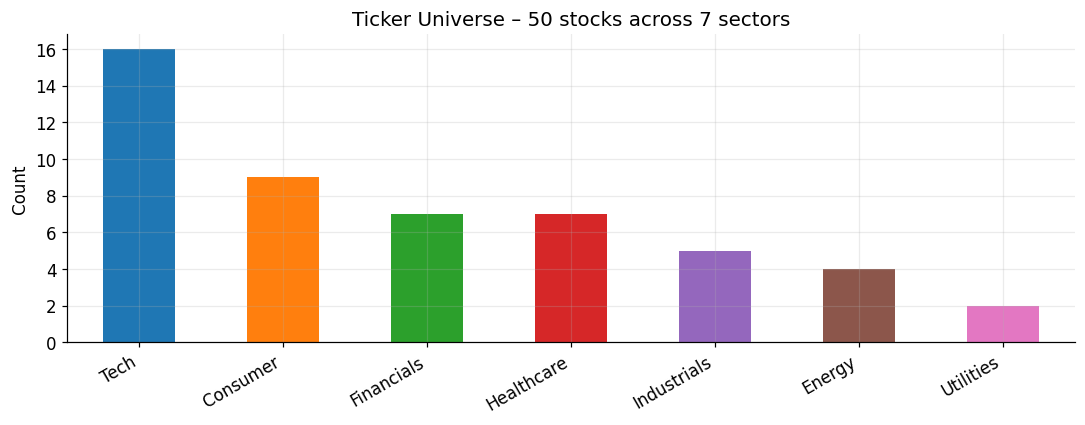

Tech           16
Consumer        9
Financials      7
Healthcare      7
Industrials     5
Energy          4
Utilities       2


In [ ]:
UNIVERSE = {
    # technology (11)
    'AAPL':'Tech','MSFT':'Tech','NVDA':'Tech','AVGO':'Tech','ORCL':'Tech',
    'CRM':'Tech','ADBE':'Tech','AMD':'Tech','INTC':'Tech','CSCO':'Tech','IBM':'Tech',
    # FAANG+ extras
    'AMZN':'Tech','META':'Tech','GOOGL':'Tech','GOOG':'Tech','NFLX':'Tech',
    # Financials
    'JPM':'Financials','BAC':'Financials','WFC':'Financials','GS':'Financials',
    'MS':'Financials','BLK':'Financials','SCHW':'Financials',
    # Healthcare
    'LLY':'Healthcare','UNH':'Healthcare','JNJ':'Healthcare','PFE':'Healthcare',
    'MRK':'Healthcare','ABBV':'Healthcare','TMO':'Healthcare',
    # Consumer
    'WMT':'Consumer','COST':'Consumer','PG':'Consumer','KO':'Consumer',
    'PEP':'Consumer','MCD':'Consumer','NKE':'Consumer','SBUX':'Consumer','DIS':'Consumer',
    # Energy
    'XOM':'Energy','CVX':'Energy','COP':'Energy','SLB':'Energy',
    # Industrials
    'BA':'Industrials','CAT':'Industrials','GE':'Industrials','HON':'Industrials','UPS':'Industrials',
    # Utilities
    'NEE':'Utilities','DUK':'Utilities',
}
TICKERS = list(UNIVERSE.keys())
N = len(TICKERS)
SECTOR = pd.Series(UNIVERSE)

sector_counts = SECTOR.value_counts()
fig, ax = plt.subplots(figsize=(10, 4))
sector_counts.plot.bar(ax=ax, color=sns.color_palette('tab10', len(sector_counts)))
ax.set_title(f'Ticker Universe – {N} stocks across {len(sector_counts)} sectors', fontsize=13)
ax.set_ylabel('Count'); ax.set_xlabel('')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()
print(sector_counts.to_string())

**Dominant sector**: Tech (16), followed by Consumer (9)

In financial modelling, having a "Tech-heavy" universe like this (16/50 stocks) means our overall portfolio performace will be very sensitive to how Nasdaq or tech industry performs.

The Universe is heavily skewed. Because Tech makes up 32% of our tickers, any equal-weighted portfolio analysis we do later will naturally be a bet on the Tech sector. Looking on the bright side, we have enough stocks in Tech and Consumer to calculate meaningful sector-specific averages / correlations. In stark contrast, comes Utilities (2). If one of those 2 utility stocks has a freak accident or a massive earnings bear, the Utilities sector will swing wildly. Hence we cannot perform robust statistical inference on the sample size of 2.

Stocks with the same sector tend to move tgether which stands for high-sector correlation. To put it differently, upon building a correlation matrix, we should expect to see clusters of high heat

# Data Download

In [ ]:
START, END = '2013-01-01', '2026-02-28'
raw = yf.download(TICKERS, start=START, end=END, auto_adjust=False)
print(f"Downloaded: {raw.shape[0]} trading days,  {raw.shape[1]} columns")
print(f"Date range: {raw.index[0].date()} → {raw.index[-1].date()}")
raw.head(3)

[*********************100%***********************]  50 of 50 completed

Downloaded: 3309 trading days,  300 columns
Date range: 2013-01-02 → 2026-02-27


Price       Adj Close                                                 \
Ticker           AAPL       ABBV       ADBE   AMD     AMZN      AVGO   
Date                                                                   
2013-01-02  16.596678  20.561069  38.340000  2.53  12.8655  2.362920   
2013-01-03  16.387192  20.391289  37.750000  2.49  12.9240  2.375265   
2013-01-04  15.930731  20.133692  38.130001  2.59  12.9575  2.360016   

Price                                                   ...   Volume  \
Ticker             BA       BAC         BLK        CAT  ...       PG   
Date                                                    ...            
2013-01-02  64.583839  9.395511  153.178238  67.045509  ...  9987000   
2013-01-03  64.919052  9.340837  153.595764  67.690842  ...  7741900   
2013-01-04  65.103378  9.457993  156.965057  68.063751  ...  5853700   

Price                                                                          \
Ticker          SBUX      SCHW      SLB      TMO       UNH      UPS       WFC   
Date                                                                            
2013-01-02  13267600  15607600  6391400  1737600   5358100  4810800  30443000   
2013-01-03  14670400  14175900  6063000  1321800  14413200  4528900  25374800   
2013-01-04  10911400  16143400  5165300  1656000  10458000  2632000  31420300   

Price                           
Ticker           WMT       XOM  
Date                            
2013-01-02  31172400  16143700  
2013-01-03  26730300  13268200  
2013-01-04  19314000  11427900  

[3 rows x 300 columns]

---
# Data Quality Analysis

Before any modelling, we audit the raw data for gaps, coverage anomalies, and potential survivorship considerations

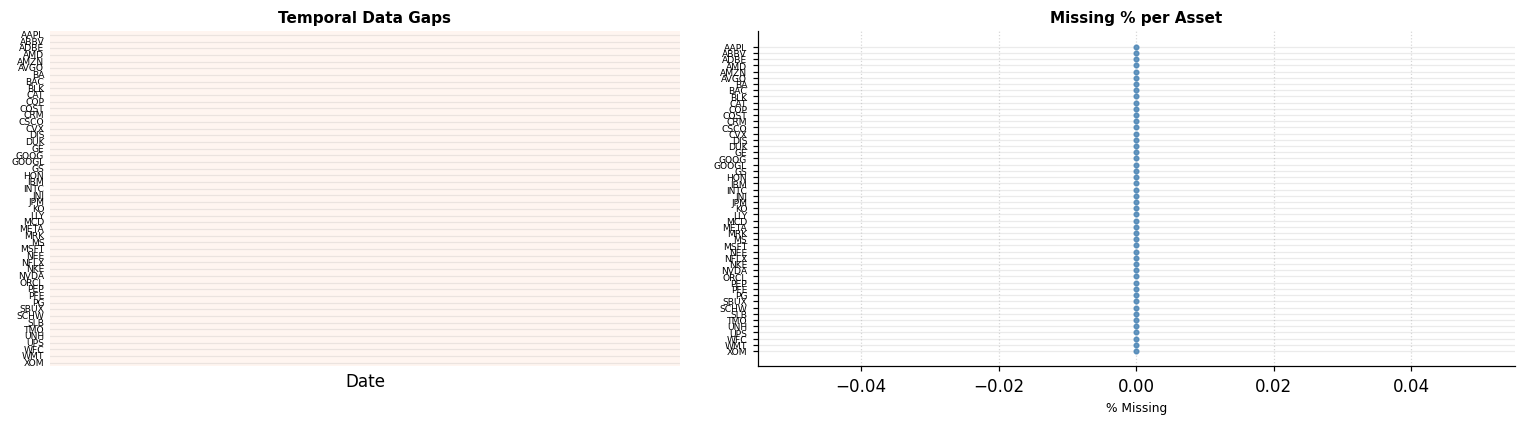

In [ ]:
# Compact Missing Value Audit
prices = raw['Adj Close'].copy() # isolate Adjusted Close prices (these are the standard prices used for calculating daily returns)
missing = (prices.isnull().mean() * 100).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={'width_ratios': [1, 1.2]})

# Temporal Heatmap
sample_idx = np.linspace(0, len(prices)-1, min(400, len(prices)), dtype=int)
sns.heatmap(prices.iloc[sample_idx].isnull().T, cbar=False, ax=axes[0], cmap='Reds',
            xticklabels=False, yticklabels=True)

axes[0].set_title('Temporal Data Gaps', fontsize=10, weight='bold')
axes[0].tick_params(axis='y', labelsize=6, length=0)
axes[0].set_ylabel('')


x_range = range(len(missing))
axes[1].hlines(y=x_range, xmin=0, xmax=missing.values, color='steelblue', alpha=0.4)
axes[1].plot(missing.values, x_range, "o", markersize=3, color='steelblue', alpha=0.8)

axes[1].set_title('Missing % per Asset', fontsize=10, weight='bold')
axes[1].set_yticks(x_range)
axes[1].set_yticklabels(missing.index, fontsize=6)
axes[1].invert_yaxis() # move highest missing to the top
axes[1].set_xlabel('% Missing', fontsize=8)
axes[1].grid(axis='x', linestyle=':', alpha=0.5)

for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout(w_pad=2.0)
plt.show()

We have zero missing values across the entire universe for the time period selected.

Companies changes their share structure and pay out cash all the time. Two main events "break" raw price data:
- Stock Split: what if we own 1 share of a company worth 200 euro.The company does 2-for-1 split. Then we own 2 shares worth 100 euro each which adds up to 200 euro all told. We have not lost a quid. Considering the raw data (close), the chart shows the price crashing from 200 euro to 100 euro overnight.
- Dividents: if a stock is worth 100 euro. it pays out a 2 euro dividend in cash. Hence on the "ex-dividend date", the stock price usually drops by roughly 2 euro because that cash has left the company's bank account and gone into ours. Considering the raw data (close), it looks like the stock lost 2% of its value. But we didn't lose money, we just moved it from the stock into our cash balance.

It is for this reason that we use `raw['Adj Close']`. **The adjusted close** is a synthetic price created by working backward from today. It adjusts all historical prices to reflect these changes so that the percentage change between any 2 days represents the Total return. Unlike "Close", the Adjusted Close accounts for dividents and stock splits. If we used regular "Close", our data would show a tremendous fallacious 50% drop if a stock had a 2-for-1 split


---
## Survivorship Bias

To ensure a Synchronous Universe, we mapped the data coverage timeline for each ticker. This prevents survivorship bias, the error of only analysing stocks that existed for the full duration of a window while ignoring those that entered or exited late. A horizontal coverage map was generated to verify the first and last valid indices for every security.

The resulting Gantt-style chart shows a perfectly rectangular block of data. Every stock in the universe has a matching start and an end date (approx. 4800 days of history from 2013 onwards)

This alignment allows for the calculation of an NxN correlation matrix where every pair of stocks is compared over the exact same market conditions and time intervals

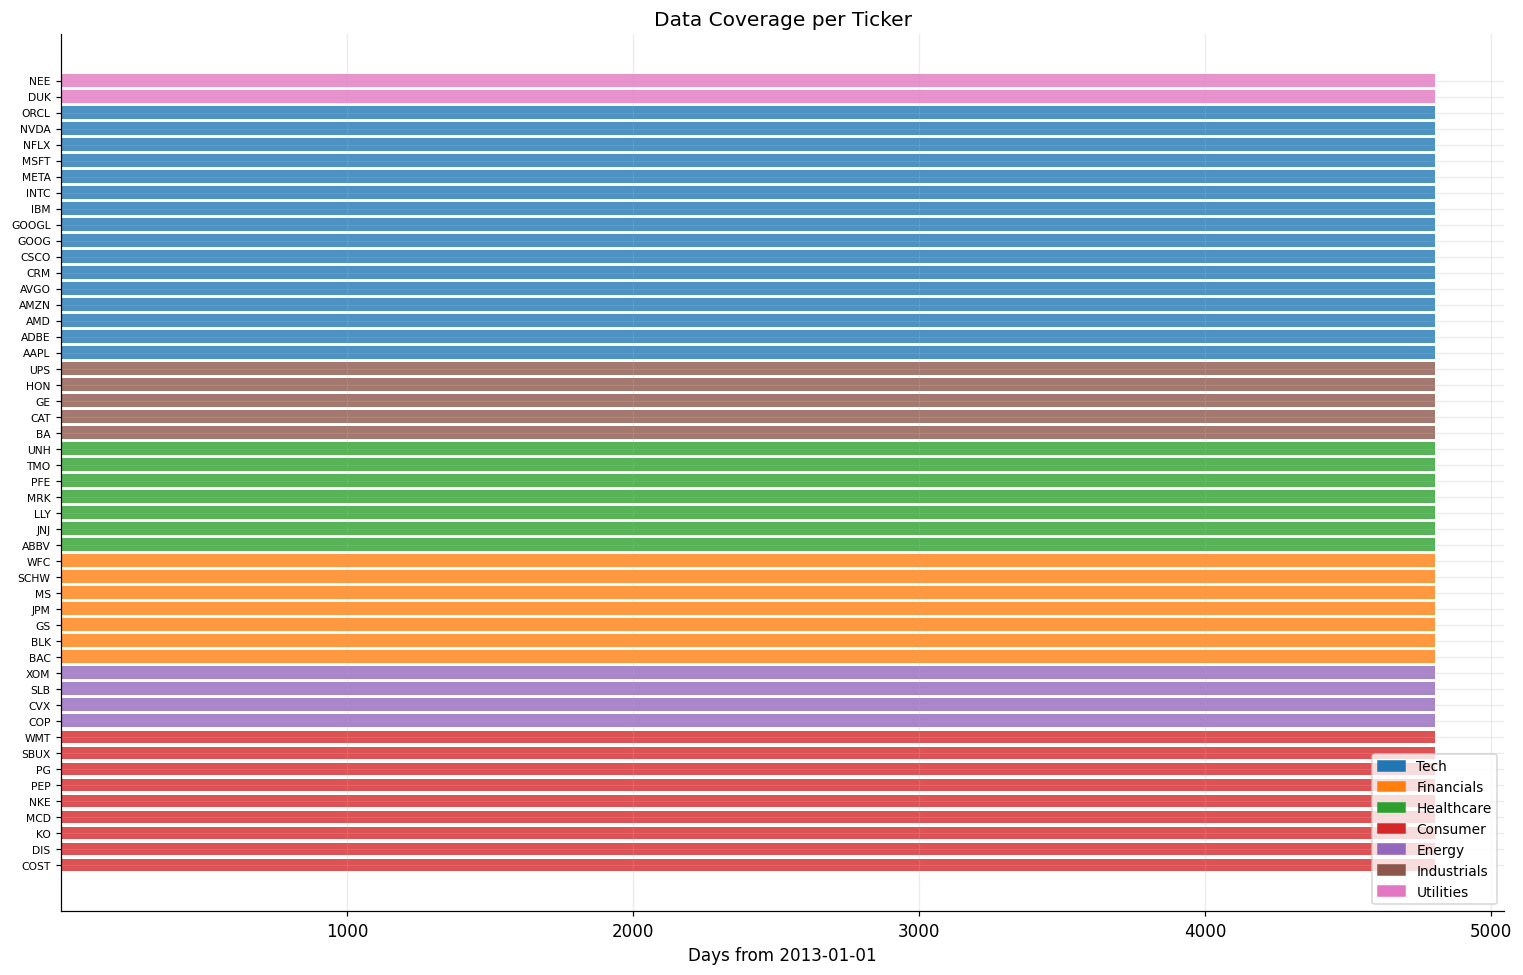

In [ ]:
first_valid = prices.apply(lambda s: s.first_valid_index()) # scans down a column and returns the exact date of the very first number it finds that isn't NaN
last_valid = prices.apply(lambda s: s.last_valid_index()) # it finds the last available price
coverage_df = pd.DataFrame({'first': first_valid, 'last': last_valid, 'sector': SECTOR[prices.columns]})
coverage_df['days'] = (coverage_df['last'] - coverage_df['first']).dt.days
coverage_df = coverage_df.sort_values(['sector', 'first'])

fig, ax = plt.subplots(figsize=(14, 9))
colors_map = {s: c for s, c in zip(SECTOR.unique(), sns.color_palette('tab10', len(SECTOR.unique())))}
for i, (ticker, row) in enumerate(coverage_df.iterrows()):
    ax.barh(i, (row['last'] - row['first']).days, left=row['first'].toordinal() - pd.Timestamp('2013-01-01').toordinal(), color=colors_map[row['sector']], alpha=0.8, height=0.8)
ax.set_yticks(range(len(coverage_df))); ax.set_yticklabels(coverage_df.index, fontsize=7)
ax.set_xlabel('Days from 2013-01-01'); ax.set_title('Data Coverage per Ticker')

# legend
from matplotlib.patches import Patch
legend_handles = [Patch(color=colors_map[s], label=s) for s in colors_map]
ax.legend(handles=legend_handles, loc='lower right', fontsize=9)
plt.tight_layout(); plt.show()

---
## Statistics Table
1. **The transformations:**
- *forward fill*: if a price was missing, this carries the last known price forward. this prevents fake zeros in our returns
- *pct_change()*: this calculates the standard arithmetic return

$$R_t = \frac{P_t - P_{t-1} + D_t}{P_{t-1}}$$

- *dropna()*: the very first day of our dataset will have no "previous day" to compare to, resulting in a NaN. We drop it so the math does not break

2. **Annualisation: the "252" rule:**
- 252 stands for 252 trading days in a year (excluding weekends and holidays)
- *Returns*: we multiply the daily mean by 252 to get the **annualised** return
- *Volatility*: we multiply the daily standard deviation by $\sqrt{252}$. We do so since volatility (risk) **scales with the square root of time**.

3. **The quality metric. The sharpe ratio**:
- the Sharpe ratio tells us how much return we are getting per unit of volatility through which we persevere.
$$\text{Sharpe} = \frac{\text{Mean Return}}{\text{Standard Deviation}} \times \sqrt{252}$$

4. **The shape of risk. Skewness and Kurtosis**

- These tell us if the stock's returns look like a Normal Distribution.
- **Skewness**: most stocks have a skew near 0. However, ORCL has a high positive skew, meaning it has **fat tails** to the **right**
- **Kurtosis**: this measures peakedness. A high kurtosis (ORCL at 45.281, MCD at 30.993) means the stock spends most of its time doing nothing, but **when it moves, it moves in extreme jumps**.

5. **Universe-level aggregates**

- **Mean annual return** (19.75%): the universe is performing well due to the heavy tech weight.
- **Max drawdown**: NFLX had a single day where it dropped -35.1%. This is a reminder that while the average returns are high the path to get there can be violent.

In [ ]:
returns = prices.ffill().pct_change().dropna()

stats_df = pd.DataFrame({
    'Ann. Return (%)': returns.mean() * 252 * 100,
    'Ann. Vol (%)':    returns.std()  * np.sqrt(252) * 100,
    'Sharpe':          (returns.mean() / returns.std()) * np.sqrt(252),
    'Skewness':        returns.skew(),
    'Kurtosis':        returns.kurtosis(),
    'Min (%)':         returns.min() * 100,
    'Max (%)':         returns.max() * 100,
    'Sector':          SECTOR,
}).round(3)

print("Cross-sectional summary (all tickers):")
display(stats_df.sort_values('Sharpe', ascending=False))

print("\nUniverse-level aggregates:")
print(stats_df.drop('Sector', axis=1).describe().round(3))

Cross-sectional summary (all tickers):


,Ann. Return (%),Ann. Vol (%),Sharpe,Skewness,Kurtosis,Min (%),Max (%),Sector
NVDA,59.137,45.629,1.296,0.602,9.334,-18.756,29.807,Tech
AVGO,44.564,37.954,1.174,0.375,10.529,-19.913,24.433,Tech
LLY,29.236,27.998,1.044,0.677,11.943,-14.136,15.680,Healthcare
COST,21.473,20.630,1.041,-0.254,8.406,-12.451,9.959,Consumer
MSFT,25.377,26.375,0.962,0.010,8.404,-14.739,14.217,Tech
NFLX,42.758,44.969,0.951,0.970,29.141,-35.117,42.224,Tech
GOOG,25.615,27.768,0.922,0.412,7.414,-11.101,16.052,Tech
GOOGL,25.593,27.786,0.921,0.391,7.358,-11.634,16.258,Tech
AAPL,25.098,28.311,0.887,0.019,6.911,-12.865,15.329,Tech
AMD,49.354,57.199,0.863,1.160,17.068,-24.229,52.290,Tech



Universe-level aggregates:
       Ann. Return (%)  Ann. Vol (%)  Sharpe  Skewness  Kurtosis  Min (%)  \
count           50.000        50.000  50.000    50.000    50.000   50.000   
mean            19.755        28.692   0.679     0.133    13.025  -15.832   
std             10.481         7.780   0.230     0.506     7.619    5.663   
min              7.016        17.392   0.190    -1.346     4.079  -35.117   
25%             13.640        24.262   0.501    -0.054     8.404  -18.265   
50%             17.104        27.777   0.662     0.091    11.322  -14.124   
75%             22.295        32.296   0.819     0.305    14.521  -12.282   
max             59.137        57.199   1.296     2.202    45.281   -7.735   

       Max (%)  
count   50.000  
mean    17.957  
std      8.524  
min      6.480  
25%     12.944  
50%     15.198  
75%     19.874  
max     52.290  


---
## Exploratory Data Analysis

Finance theory often assumes returns follow a bell curve. We use ```all_rets.flatten() ``` to dump every single return from every stock into one bucket to see if that's true

**The blue bars are much taller and skinnier in the middle than the red line. This is called Leptokurtosis which means our stocks stay quiet more than expected but have extreme moves more often than a bell curve predicts**


- *Sector Hierarchy*:
Here we analyse the spread of returns for each sector. Every box represents the middle 50% of data while the line in the middle is the median.

Even though the medians are all near zero the vertical height of the boxes tells us which sectors are noisier. **Tech** and **Energy** usually have taller boxes (higher daily variance) than **Utilities** / **Consumer Staples**.

- *Skew vs. Kurtosis*:
Here we are identifying which stocks are prone to instigate accidents. We are plotting the shape of the distribution.

**high kurtosis(Y-axis):** stocks like **ORCL** have massive and infrequent price jumps

**skewness(X-axis):** stocks on the right have more surprise up-days while stocks on the left have more surprise crashes

- *Cumulative Returns*:
We carry out this part of analysis by means of `(1+sec_ret).cumprod()`. To put it differently, we multiply yesterday's wealth by today's return day after day. Upon undergoing meticulous scrutiny, it is clear that **Tech** constitutes the outlier. Not only does it win yet dominate likewise. The gap between the blue line and the rest means that **Tech** is at a premium.

- *Rolling Volatility*:
We cannot look at volatility for the entire 13-year period at once since it'd give us a single number which won't give much semantic weight (volatility is not constant and comes in waves). It is exactly for this reason that we consider a rolling(63) window which analyses the last 3 months of trading days. It creates a moving picture of risk. When the line goes up investors are panicking and prices are swinging prodigiously. When the line goes down, the market is stable. A level of 0.20(20%) is considered normal for a stock universe. When the line hits 40% the market is in a state of exteme instability where 2% or 3% daily swings become common.

  - **2013-2018**: the line mostly bounces below the dashed mean line (0.22). We can account for it as a period of "cheap moeny" and steady growth. To put it differently, investors were quite relaxed
  - **2020**: that vertical steep ship to 0.40+ is one of the fastest volatility spikes in history. It shows how the entire 50-stock universe began moving violently in sync as the pandemic hit
  - **2022-2026**: the line fluctuates and stays mostly above the historical mean. This reflects the uncertainty of the recent years with high interest rates, inflation and geopolitical shifts

  **By taking the average volatility of all 50 stocks we create a systematic risk indicator. Were we to only look at one stock the line would be much messier with lots of aberrations.**
  
  While investors try to diversify away the individiual noise, we must survey the macro noise inasmuch as it is the only risk we cannot avert

- **Risk-return space**

1. top-left stands for **high returns and low risks**. Here, **MSFT** and **COST** are pushing towards this area. This is the happy medium
2. top-right stands for **high return and high risks**. **NVDA** and **AMD** gravitate towards this area. They sustain a lucrative trend yet are so very rickety
3. bottom-left stands for **low return, low risks**. **JNJ** and **KO**. These will not proliferate investments, but they preclude the portfolio from collapsing during a crash
4. bottom-right guarantees low return, high risk. **SLB** and **PFE** are trending towards this area

**The efficient frontier** is a curved line that represents the best possible portfolios to be considered. Such portoflios form a boundary on top-left edge of the collection of dots.

**Anything below the frontier is sub-optimal**

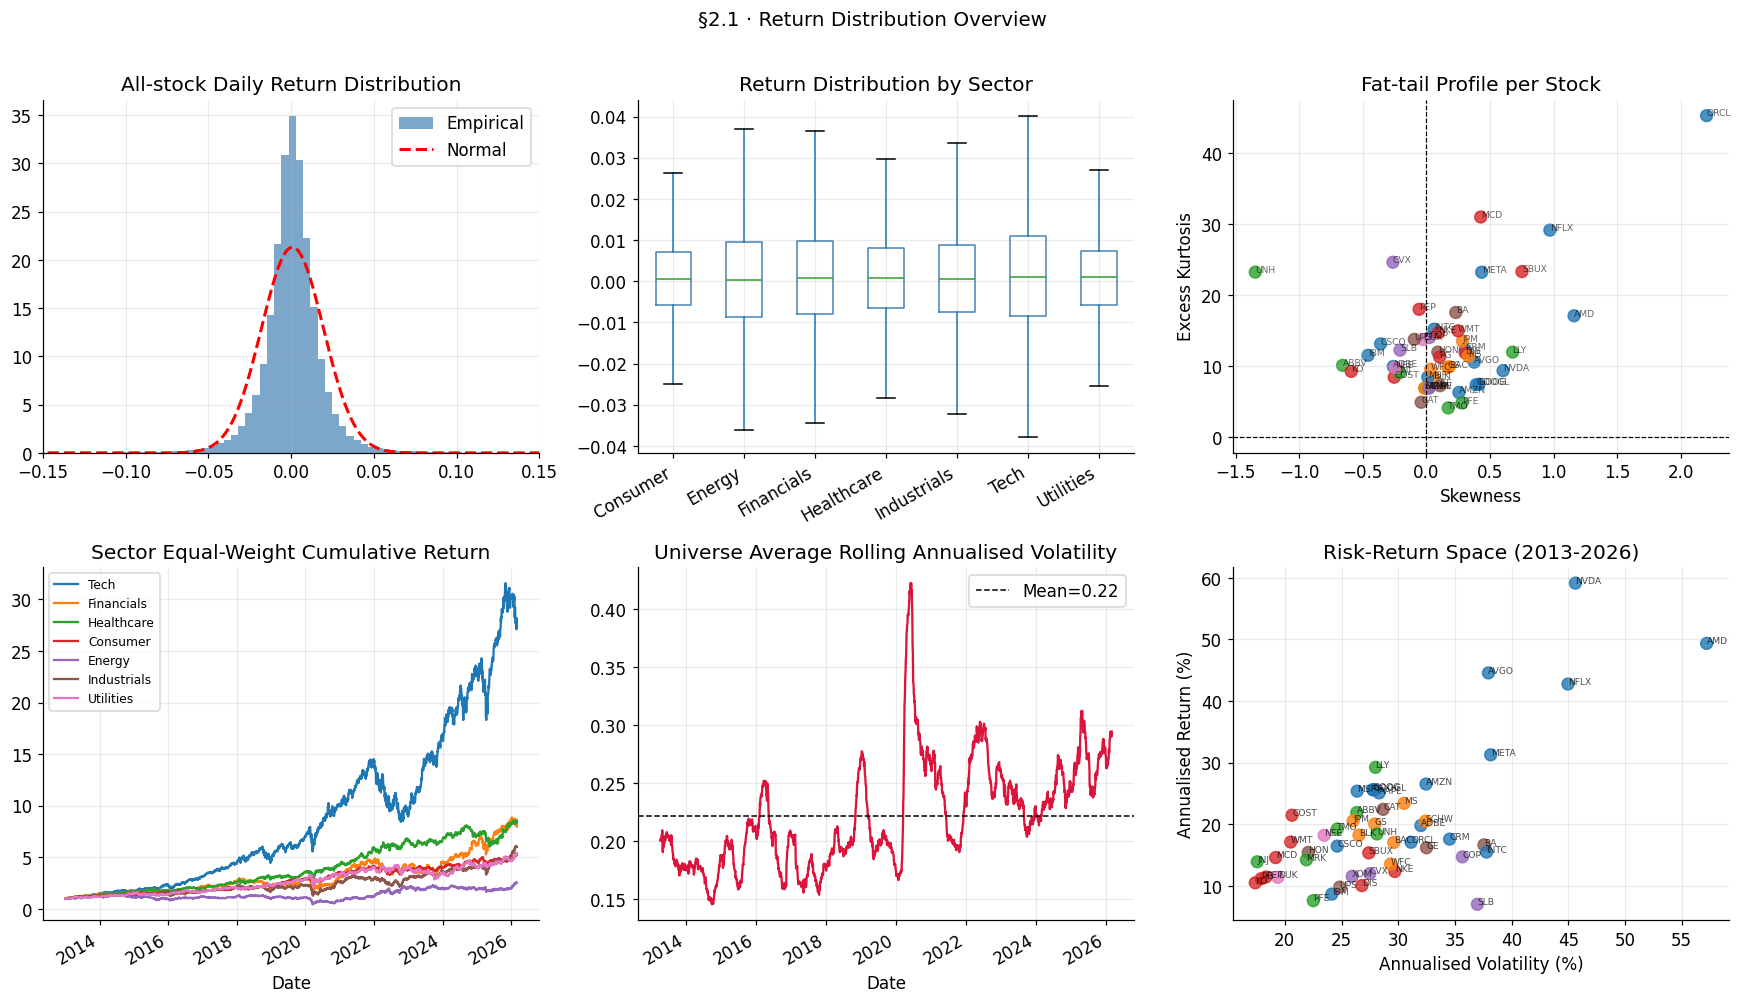

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# Universe-wide return distribution
all_rets = returns.values.flatten()
all_rets = all_rets[~np.isnan(all_rets)]
ax = axes[0, 0]
ax.hist(all_rets, bins=200, density=True, color='steelblue', alpha=0.7, label='Empirical')
x = np.linspace(all_rets.min(), all_rets.max(), 500)
ax.plot(x, stats.norm.pdf(x, all_rets.mean(), all_rets.std()), 'r--', lw=2, label='Normal')
ax.set_xlim(-0.15, 0.15); ax.set_title('All-stock Daily Return Distribution'); ax.legend()

# Per-sector return box-plot
ret_long = returns.stack().reset_index()
ret_long.columns = ['Date','Ticker','Return']
ret_long['Sector'] = ret_long['Ticker'].map(UNIVERSE)
ax = axes[0, 1]
order = ret_long.groupby('Sector')['Return'].median().sort_values().index
ret_long.boxplot(column='Return', by='Sector', ax=ax, showfliers=False,
                 boxprops=dict(color='steelblue'))
ax.set_title('Return Distribution by Sector'); ax.set_xlabel('');
plt.sca(ax); plt.xticks(rotation=30, ha='right')

# Skewness vs Kurtosis scatter
ax = axes[0, 2]
scatter_colors = [colors_map[SECTOR[t]] for t in stats_df.index]
ax.scatter(stats_df['Skewness'], stats_df['Kurtosis'], c=scatter_colors, s=60, alpha=0.8)
ax.axhline(0, color='k', lw=0.8, ls='--'); ax.axvline(0, color='k', lw=0.8, ls='--')
ax.set_xlabel('Skewness'); ax.set_ylabel('Excess Kurtosis')
ax.set_title('Fat-tail Profile per Stock')
for t in stats_df.index: ax.annotate(t, (stats_df.loc[t,'Skewness'], stats_df.loc[t,'Kurtosis']),
                                       fontsize=6, alpha=0.6)

# Cumulative return of each sector
ax = axes[1, 0]
for sec in SECTOR.unique():
    tiks = [t for t in TICKERS if UNIVERSE.get(t)==sec and t in returns.columns]
    sec_ret = returns[tiks].mean(axis=1)
    (1 + sec_ret).cumprod().plot(ax=ax, label=sec, lw=1.5)
ax.set_title('Sector Equal-Weight Cumulative Return'); ax.legend(fontsize=8)

# Rolling 63-day volatility (universe average)
ax = axes[1, 1]
univ_vol = returns.std(axis=1).rolling(63).mean() * np.sqrt(252)
univ_vol.plot(ax=ax, color='crimson', lw=1.5)
ax.axhline(univ_vol.mean(), color='k', ls='--', lw=1, label=f'Mean={univ_vol.mean():.2f}')
ax.set_title('Universe Average Rolling Annualised Volatility'); ax.legend()

# Annualised return vs. vol scatter
ax = axes[1, 2]
sc = ax.scatter(stats_df['Ann. Vol (%)'], stats_df['Ann. Return (%)'],
                c=[colors_map[SECTOR[t]] for t in stats_df.index], s=60, alpha=0.8)
for t in stats_df.index:
    ax.annotate(t, (stats_df.loc[t,'Ann. Vol (%)'], stats_df.loc[t,'Ann. Return (%)']),
                fontsize=6, alpha=0.7)
ax.set_xlabel('Annualised Volatility (%)'); ax.set_ylabel('Annualised Return (%)')
ax.set_title('Risk-Return Space (2013-2026)')

plt.suptitle('§2.1 · Return Distribution Overview', fontsize=13, y=1.01)
plt.tight_layout(); plt.show()

---
# Correlation structure and hierarchical clustering

Correlation tells us how much stocks move in sync. But clustering algorithms need a distance. To turn distance to good account we resort to Ward's method. This is an algorithm that looks for clusters that minimise the inner variance. It tries to group stocks so that the members of a group are as similar as possible. To create the clustered heatmap, we reordered the matrix using ```order.idx```. In doing so, we're able to discover the sectors automatically. The dark block at the bottom right is in all likelhood our Financial stocks. **This proves that Sectors are real risk factors since stocks in the same industry move as a pack**

Looking at the Sector-level Heattmap, we can conclude:
- **Energy** (0.78) and **Financials**(0.73) are most interwoven entities. THe stocks inside these groups move all but in unison
- **Healthcare** (0.41) is the most independent sector
- **Financials** vs. **Industrials** form a nexus which witnesses that when the economy is ramping up, both **banks** and **factories** tend to rise together

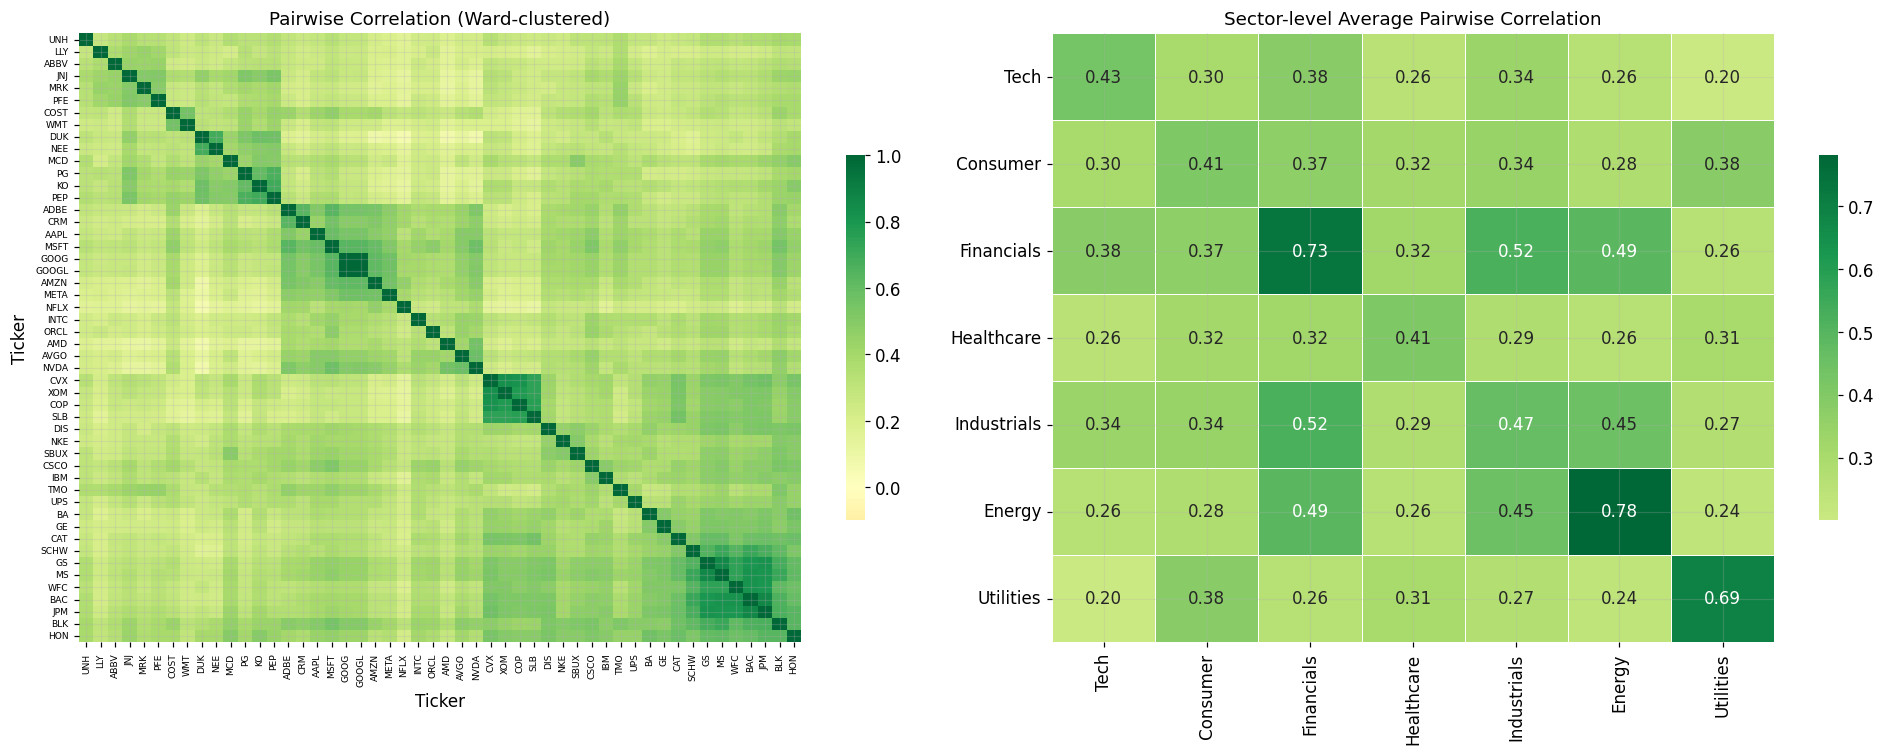

In [ ]:
corr = returns.corr()

# Hierarchical clustering on correlation matrix
Z = linkage(1 - corr.values, method='ward')
order_idx = dendrogram(Z, no_plot=True)['leaves']
corr_ord = corr.iloc[order_idx, order_idx]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# clustered heatmap
sns.heatmap(corr_ord, ax=axes[0], cmap='RdYlGn', center=0, vmin=-0.1, vmax=1,
            xticklabels=corr_ord.columns, yticklabels=corr_ord.index,
            linewidths=0, annot=False, cbar_kws={'shrink': 0.6})
axes[0].set_title('Pairwise Correlation (Ward-clustered)', fontsize=12)
axes[0].tick_params(labelsize=6)

# sector-level average correlation
sector_corr = pd.DataFrame(index=sector_counts.index, columns=sector_counts.index, dtype=float)
sectors = list(sector_counts.index)
for s1 in sectors:
    t1 = [t for t in TICKERS if UNIVERSE.get(t)==s1 and t in corr.columns]
    for s2 in sectors:
        t2 = [t for t in TICKERS if UNIVERSE.get(t)==s2 and t in corr.columns]
        block = corr.loc[t1, t2]
        if s1 == s2:
            n = len(t1)
            sector_corr.loc[s1,s2] = (block.values.sum() - n) / max(n*(n-1), 1)
        else:
            sector_corr.loc[s1,s2] = block.mean().mean()
sector_corr = sector_corr.astype(float)
sns.heatmap(sector_corr, ax=axes[1], cmap='RdYlGn', center=0, annot=True,
            fmt='.2f', linewidths=0.5, cbar_kws={'shrink': 0.6})
axes[1].set_title('Sector-level Average Pairwise Correlation', fontsize=12)
plt.tight_layout(); plt.show()

---
# Autocorrelation and ACF/PACF

**Autocorrelation structure**

in a perfectly efficient market returns shall be a sequence of independent and identically distributed random variables.

  - $r_t$ is current return

  - $r_{t-k}$ is lagged return

- **Autocorrelation function** represents the total correlation of the return with its own past at different lags (1 day aog, 2 days ago, 3 days ago, etc.) In other words, it is the total correlation between  $r_t$ and its lagged values $r_{t-k}$. **For our tickers, the rapid decay to the noise floor confirms that there is no significant linear memory in the returns.** With linear memory, if for instance a stock goes up 2% today, and there's high autocorrelation, it is very likely to go up again on the morrow.The past casts its mind back to the direction it would follow and then pushes the present trend in the same way. Even so, as in our case, the stock goes up 2% today, but tomorrow is a total coin flip. The memory of today's move vanishes instantly.
  - **The noise floor** is posited amid a shaded blue region. This is the 95% confidence interval. Hence, if our returns were perfectly random, the correlation would never abrogate into 0 due to random luck. the blue area embodies the maximum amount of luck we may anticipate. Therefore, anything inside that blue shaded area is considered statistical noise.
    - in our plot, the very first bar is set to 1 since a stock is always 100% correlated with itself. In contradistinction to the latter,the very next bar onwards flops herewith into that blue zone of so-called statistical noise.

Decay refers to how fast the correlation drops as we move further into the past (increasing the lag $k$)
- Slow decays foreshadows trending data. In non-stationary data (raw prices in our case), the correlation stays high for many days and guarantees long memory.
- Rapid decay presupposes sudden correlation drops from 1 at lag 0 to nearly 0 at lag 1. **As it applies to us, this vertical nosedive proves that the market is processing information all but instantly.**

- **Partial Autocorrelation function** stands for the conditional correlation. To put it differently, partial autocorrelation function isolates the correlation at lag $k$ by controlling for the effects.

**Ljung-Box test p-values analyses**
Instead of testing one lag at a time, it tests whether the first $h$ lags are collectively different from zero.

$$Q = n(n+2) \sum_{k=1}^{h} \frac{\hat{\rho}_k^2}{n-k}$$
### Component Definitions for the Ljung-Box $Q$-Statistic

* **$Q$**: The **test statistic**. Under the Null Hypothesis ($H_0$) of no autocorrelation, this follows a **Chi-square** ($\chi^2$) distribution.
* **$n$**: The **total sample size**, representing the number of daily observations in the dataset.
* **$\sum_{k=1}^{h}$**: The **summation operator**. It aggregates the squared correlations from Lag 1 ($k=1$) through the maximum specified lag ($h$).
* **$\hat{\rho}_k^2$**: The **squared sample autocorrelation** at lag $k$. The value is squared to measure the **magnitude** of the deviation from zero, ensuring that both positive and negative correlations provide evidence against the null hypothesis of randomness.
* **$n-k$**: The **sample weight adjustment**. It compensates for the diminishing number of overlapping data pairs as the lag $k$ increases, ensuring the statistic remains robust for larger lags.

The ACF only gauges if $r_t$ and $r_{t-k}$ cohere linearly in unison. Notwithstanding the latter, there still might arise non-linear memory. if the direction (up/down) is forgotten which means absence of linear memory, the intensity, this is to say, volatility, may still be retained. It is exactly for this reason that our ACF looks somewhat emty while Ljung-Box p-values give 0s. As evinced by this observation, the memory is not in the returns themselves yet in the magnitude of the oscillations. Even though the ACF looks cleam, the Ljung-Box test is sniffing out non-linear dependencies. In finance, it commonly witnesses the precedent of **volatility clustering**. The returns are not white noise. Rather M-dependent. Therefore, while the direction is hard to presage, the magnitude of risk has memory to cast.


Therefore, The ACF / PACF proflies exhibit **rapid decay** with all coefficients beyond lag0 falling within the 95% confidence interval. This suggests the dearth of serial correlation and confirms that the first moment of the distribution approximates a **White noise process** leaving no room for linear autoregressive forecasting later on.

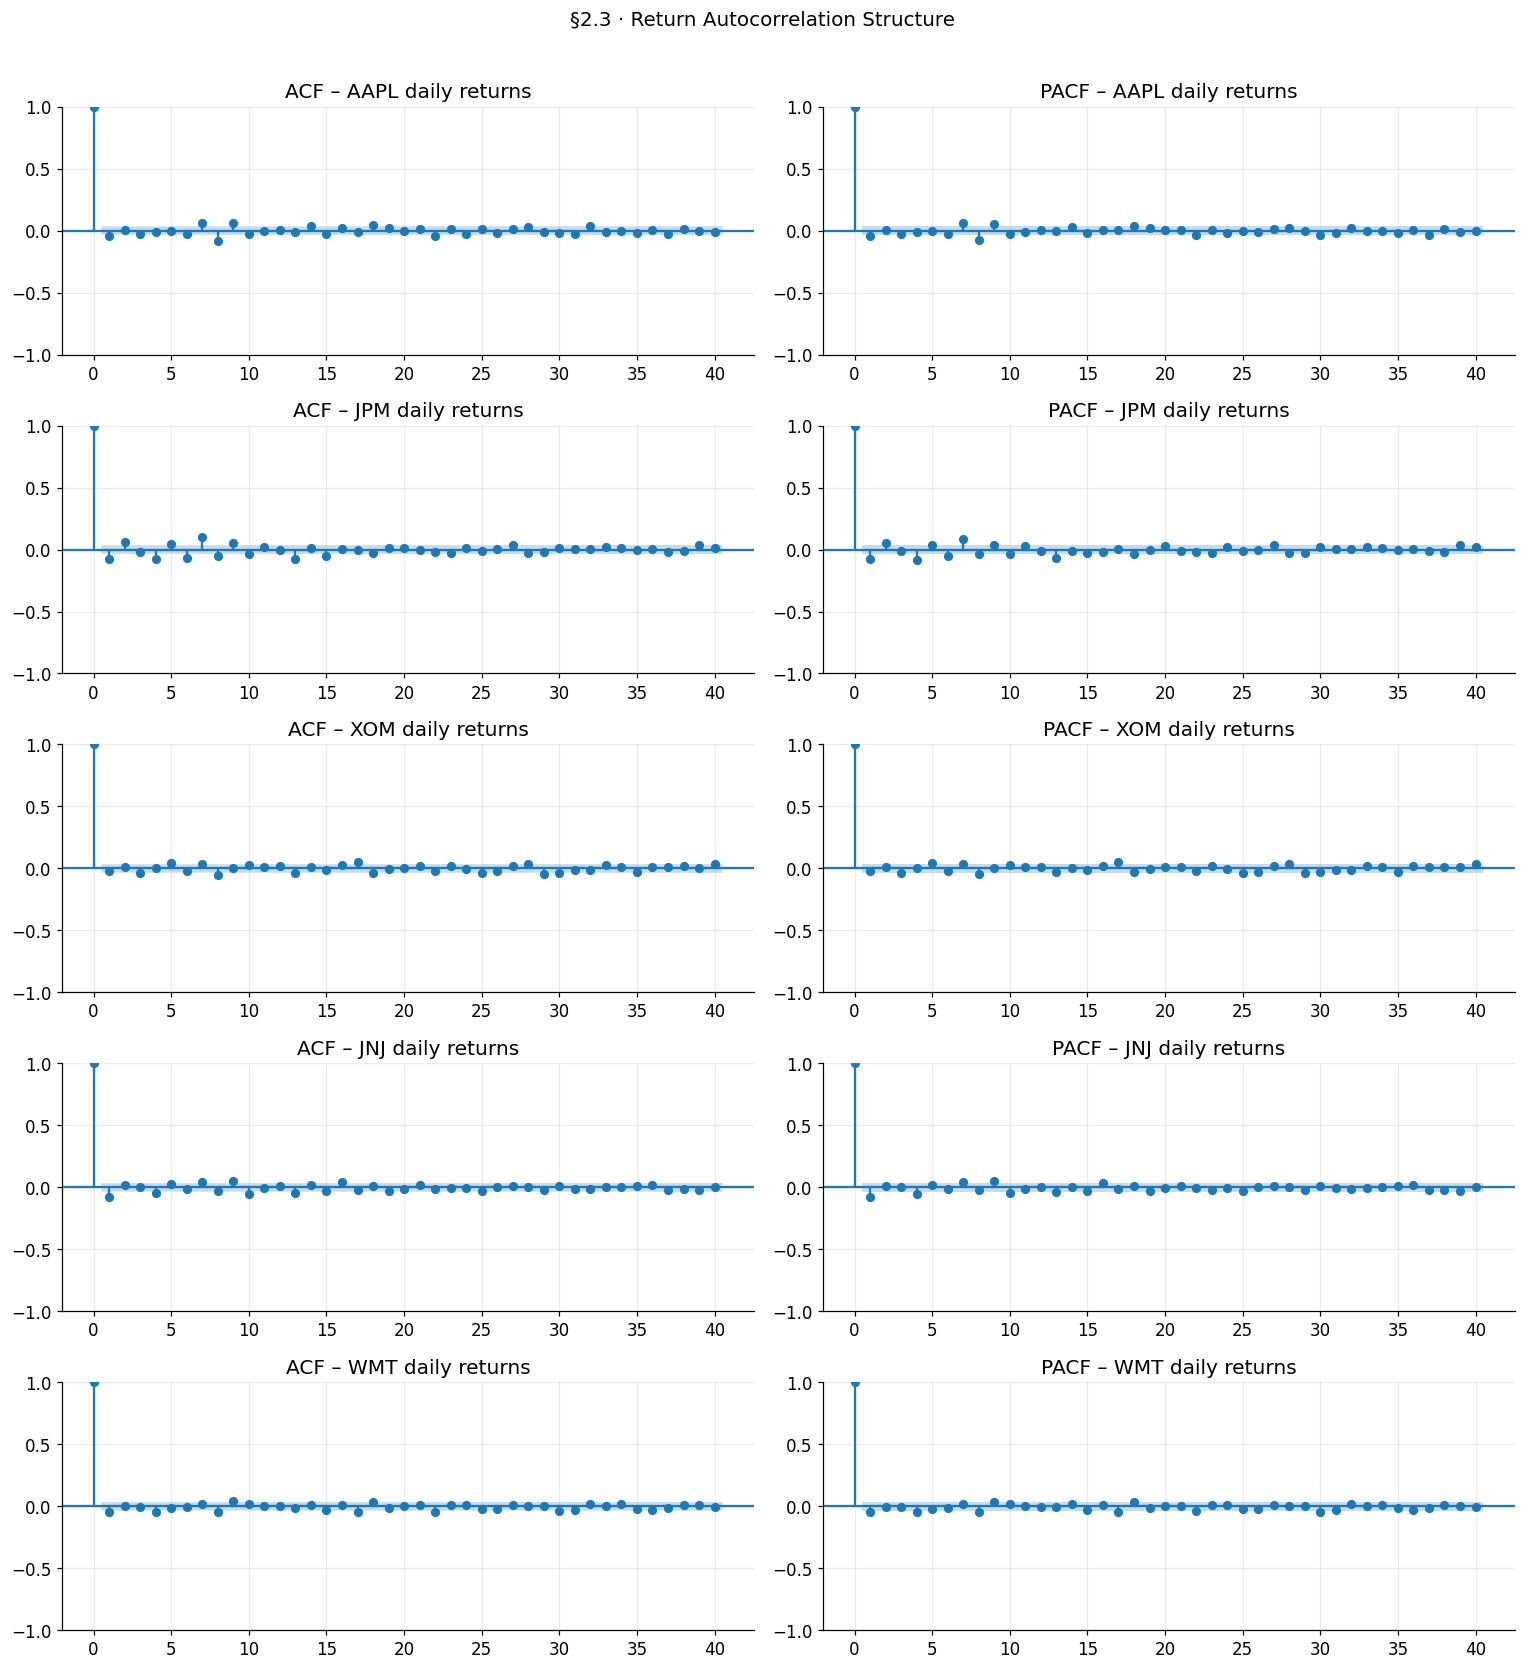

Ljung-Box test p-values (lag=20) – H0: no autocorrelation
AAPL    0.0000
JPM     0.0000
XOM     0.0001
JNJ     0.0000
WMT     0.0011
Name: p-value, dtype: float64


In [ ]:
# Test on a representative mix of tickers
sample_tickers = ['AAPL', 'JPM', 'XOM', 'JNJ', 'WMT']

fig, axes = plt.subplots(len(sample_tickers), 2, figsize=(14, 3*len(sample_tickers)))
for i, t in enumerate(sample_tickers):
    r = returns[t].dropna()
    plot_acf(r, ax=axes[i,0], lags=40, alpha=0.05, title=f'ACF – {t} daily returns')
    plot_pacf(r, ax=axes[i,1], lags=40, alpha=0.05, title=f'PACF – {t} daily returns', method='ywm')
plt.suptitle('§2.3 · Return Autocorrelation Structure', fontsize=13, y=1.01)
plt.tight_layout(); plt.show()

print("Ljung-Box test p-values (lag=20) – H0: no autocorrelation")
from statsmodels.stats.diagnostic import acorr_ljungbox
lb_results = {}
for t in sample_tickers:
    r = returns[t].dropna()
    pv = acorr_ljungbox(r, lags=[20], return_df=True)['lb_pvalue'].values[0]
    lb_results[t] = pv
print(pd.Series(lb_results, name='p-value').round(4))

---
# Stationarity and the unit root (ADF test)
We need to make certain that the underlying process is stationary. if a process appears to have a unit root, it is a non-stationary random exploration. If a stock price has a unit root, it means the price today is equal to the price yesterday plus a random shock.

### Stochastic Process Dynamics: The Unit Root

A first-order autoregressive process, denoted as $AR(1)$, is defined by the following transition equation:

$$P_t = \phi P_{t-1} + \epsilon_t$$

Where:
* **If $|\phi| < 1$**: The process is **Stationary**. Any exogenous shock to the system is transitory; the price will eventually undergo **mean reversion**, returning to its long-term equilibrium.
* **If $\phi = 1$**: The process contains a **Unit Root**. The series is non-stationary and exhibits no "memory" of a long-term mean. It is characterized as a **Random Walk**, where the current value is simply the sum of all past shocks ($\epsilon_t$).

If we try to run a regression on 2 variables that both have unit roots, Apple and Microsoft as a case in point, we are prone to very high $R^2$ and significant p-values even if the comanies have nothing to do with each other. To put it differently, **spurious regression** might take its toll.

**The Augmented Dickey-Fuller test**
The Augmented Dickey-Fuller test checks if ϕ=1.
- The null hypothesis ($H_0$): the series has a unit root (it is not stationary)
- The goal: we want to reject this null hypothesis

1.
**The log-price domain: high persistence**

the ADF statistic for tickers such as **NVDA**(-0.095) and **AAPL**(-0.398) remains close to 0. This leads up to p-values significantly above the conventional 0.05 threshold. Granted that, we cannot statistically abnegate the presence of a unit root within the log-price series.

As evinced by the fact that price levels are dominated by a stochastic trend where shocks have a permanent effect on the series, the mean and variance are time-dependent which makes the series non-stationary and thereby unsuitable for standard linear modelling.

2.
**The return domain: statistical stability**

hereinafter we will be considering **first-difference transformation application**. In doing so the p-values for every ticker from MSFT to AMD shift decisively to 0s.

**First-difference transformation**
If we have a time series of prices $P_t$, the first difference $\Delta P_t$ is simply the value today minus the value yesterday.

As we are using log-prices, the transformation looks like this: $Return ≈ ln(P_t) - ln(P_(t-1))$

**First-difference transformation** removes the drift in data whereby we had our data affected. Stated differently, the predominance of stock prices have a trend (drift upward over time). This trend makes the data non-stationary since the average price in 2013 is outright diverse from the average price in 2026. By taking the first difference, we are effectively balancing out this trend.

**The resulting series no longer remembers where it started. it only cares about the change that happened in the last 24 hours**

In [ ]:
print("ADF test on RAW log-prices (H0: unit root / non-stationary)")
print("─" * 65)
adf_results = []
for t in TICKERS[:10]:
    lp = np.log(prices[t].dropna())
    try:
        res = adfuller(lp, maxlag=5, autolag='AIC')
        adf_results.append({'Ticker': t, 'ADF Stat': res[0], 'p-value': res[1],
                            'Stationary (5%)': res[1] < 0.05})
    except:
        pass
adf_df = pd.DataFrame(adf_results).set_index('Ticker')
display(adf_df)

print("\nADF test on DAILY RETURNS (first difference)")
print("─" * 65)
adf_ret_results = []
for t in TICKERS[:10]:
    r = returns[t].dropna()
    try:
        res = adfuller(r, maxlag=5, autolag='AIC')
        adf_ret_results.append({'Ticker': t, 'ADF Stat': res[0], 'p-value': res[1],
                                'Stationary (5%)': res[1] < 0.05})
    except:
        pass
display(pd.DataFrame(adf_ret_results).set_index('Ticker'))

ADF test on RAW log-prices (H0: unit root / non-stationary)
─────────────────────────────────────────────────────────────────


,ADF Stat,p-value,Stationary (5%)
Ticker,,,
AAPL,-0.398097,0.910416,False
MSFT,-1.366266,0.598337,False
NVDA,-0.094800,0.949954,False
AVGO,-0.440297,0.903150,False
ORCL,-0.614191,0.867743,False
CRM,-1.765695,0.397621,False
ADBE,-2.301864,0.171367,False
AMD,-0.743863,0.835059,False
INTC,-2.374699,0.149005,False



ADF test on DAILY RETURNS (first difference)
─────────────────────────────────────────────────────────────────


,ADF Stat,p-value,Stationary (5%)
Ticker,,,
AAPL,-59.848392,0.0,True
MSFT,-26.412264,0.0,True
NVDA,-40.842662,0.0,True
AVGO,-31.524951,0.0,True
ORCL,-60.645982,0.0,True
CRM,-59.565804,0.0,True
ADBE,-25.296667,0.0,True
AMD,-33.783779,0.0,True
INTC,-40.379039,0.0,True


---
# Market regime analytics

**Prices** represent the absolute nominal value of an asset at a specific point in time. As we saw previously, prices are almost always non-stationary. They have a unit root and can drift infinitely high or low and do not return to a long-term average. Because prices grow over time, they are difficult to compare across different eras. 100 euro for a stock in 1990 is fundamentally different from 100 euro for that same stock in 2026.

**Returns** represent the logaritmic change in price over a specific interval. As was marked out previously, returns are typically stationary. they tend to hover around the mean of 0.
Returns are very informative since they natively allow for a scale-invariant analysis. A 2% return is the same bargain whether the stock price is 10 euro or 1000 euro.

Hitherto we averred that raw prices $P_t$ are non-stationary while **returns** are **stationary**.

Here we are facing a trade-off:
- **returns**: achieve stationarity but "erase" the memory of price levels
- **prices**: keep all the memory but break the statistical assumptions which hereby brings about too much noise and aberrations.

So we needed to achieve stationarity while retaining the maximum amount of memory from the price level. This ensures our features can retain that a stock is at an all-time apex without being statistically invalid. This can be performed by means of **fractional differentiation**.

**Fractional differentiation** uses the binominal expansion of a logic operator. Instead of just substracting yesterday's price from today's, a fractional difference substracts a weighted sequence of all past prices. The weights for very old prices do not drop to 0 herewith, they fade away slowly permitting the memory of the price tier to sift through the stationary series.

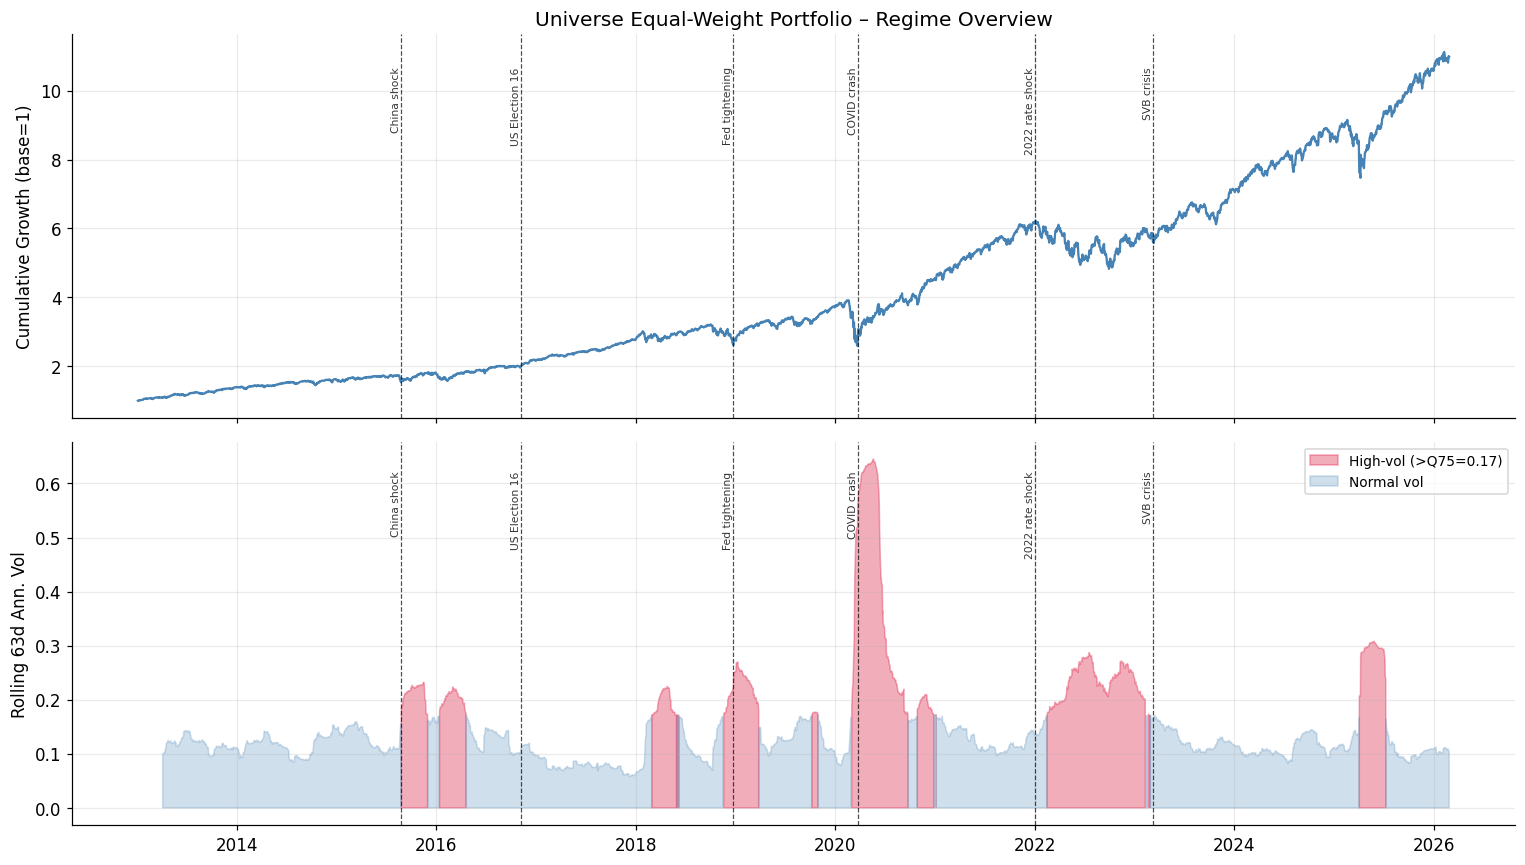

In [ ]:
market_ret = returns.mean(axis=1)
market_vol = market_ret.rolling(63).std() * np.sqrt(252)
market_cum = (1 + market_ret).cumprod()

EVENTS = {
    '2015-08-24': 'China shock',
    '2016-11-08': 'US Election 16',
    '2018-12-24': 'Fed tightening',
    '2020-03-23': 'COVID crash',
    '2022-01-03': '2022 rate shock',
    '2023-03-10': 'SVB crisis',
}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Cumulative return
ax1.plot(market_cum.index, market_cum.values, color='steelblue', lw=1.5, label='Universe EW')
ax1.set_ylabel('Cumulative Growth (base=1)')
ax1.set_title('Universe Equal-Weight Portfolio – Regime Overview')

# Volatility regime shading
vol_thresh = market_vol.quantile(0.75)
is_high_vol = market_vol > vol_thresh
ax2.fill_between(market_vol.index, 0, market_vol,
                 where=is_high_vol, color='crimson', alpha=0.35, label=f'High-vol (>Q75={vol_thresh:.2f})')
ax2.fill_between(market_vol.index, 0, market_vol,
                 where=~is_high_vol, color='steelblue', alpha=0.25, label='Normal vol')
ax2.set_ylabel('Rolling 63d Ann. Vol')

for date_str, label in EVENTS.items():
    dt = pd.Timestamp(date_str)
    if dt in market_vol.index or (market_vol.index[0] <= dt <= market_vol.index[-1]):
        for ax in [ax1, ax2]:
            ax.axvline(dt, color='black', lw=0.8, ls='--', alpha=0.7)
            ax.text(dt, ax.get_ylim()[1]*0.92, label, rotation=90,
                    fontsize=7, va='top', ha='right', alpha=0.8)

ax2.legend(fontsize=9)
plt.tight_layout(); plt.show()

---
## §3 · Feature Engineering & Validation

We build five alpha factors on top of fractionally-differentiated, wavelet-denoised prices. Each design choice is justified by an empirical test.

# The d-sweep: finding the optimal memory

We are iterating through different values of d (from 0.1 to 0.6) and for each d we transform the log-prices. Then for each value we run an Augmented-Dickey-Fuller (ADF) test on the entire 50-stock universe we are considering. the ADF test was the reason we moved from raw **prices** to **returns** and eventually to **fractionally differenced data**. its sole purpose is to determine if a series is stationary, this is to say, stable over time, or contains a unit root.

In statistics, the ADF test starts with a guilty until proven innocent approach:

- *The Null hypothesis (H_0):* the series has a unit root (it is non-stationary)
- *The goal:* we want to reject this hypothesis to prove our data is safe to model

1. **the p-value**

if p-value is north on 0.05, we fail to reject the null. To put it differently, the data is a random walk.

if p is within 0.05, then we reject the null and aver that the data is stationary.

2. **The ADF statistic**

The more negative it is, the stronger the rejection of the null hypothesis. Hence, seeing -59.84 is essentially prompting us to conclude that the data is definitely stationary.


at d = 0.3 only about 40% of our stocks are stationary. But at d = 0.5, the pass rate soars above our 95% threshold.

In our setting, we select the optimal d value by settling the minimum d that passes the threshold, we are keeping as much long term memory as possible while stripping away the stationarity fluctuations.


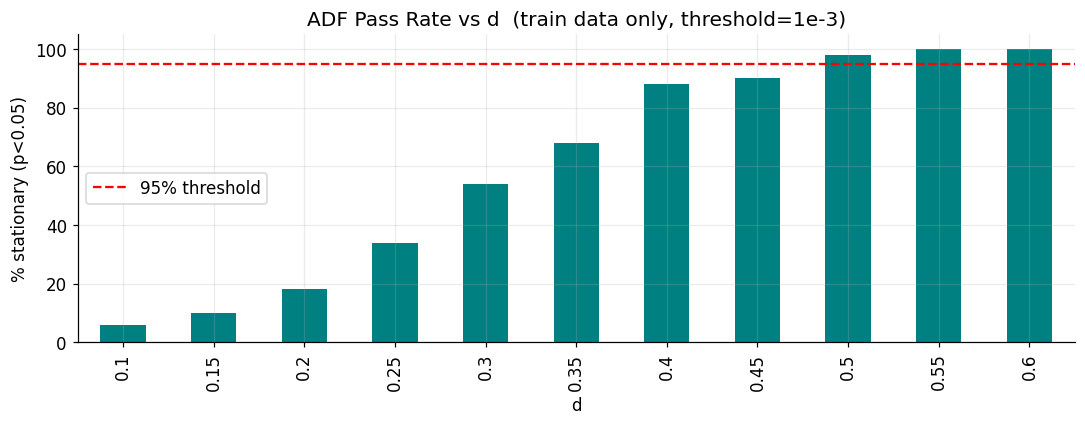

✅  Optimal d (train-only): 0.5
   FFD window width: 43 days  (was ~1800 at threshold=1e-5)


In [ ]:
def get_weights_ffd(d, threshold=1e-3):
    w = [1.]
    k = 1
    while True:
        w_next = -w[-1] / k * (d - k + 1)
        if abs(w_next) < threshold: break
        w.append(w_next); k += 1
    return np.array(w[::-1]).reshape(-1, 1)

def fractional_diff_ffd(series, d, threshold=1e-3):
    weights = get_weights_ffd(d, threshold)
    width = len(weights) - 1
    out = {}
    for col in series.columns:
        s = series[col].ffill().dropna()
        res = [np.dot(weights.T, s.iloc[i-width:i+1].values.reshape(-1,1))[0,0]
               for i in range(width, len(s))]
        out[col] = pd.Series(res, index=s.index[width:])
    return pd.DataFrame(out)

log_prices = np.log(prices.ffill())

TRAIN_CUTOFF_PROXY = '2024-05-01'
log_prices_train = log_prices[log_prices.index < TRAIN_CUTOFF_PROXY]

d_values = np.arange(0.1, 0.61, 0.05)
adf_pass_rate = {}
for d in d_values:
    fd = fractional_diff_ffd(log_prices_train, d)
    pass_count = 0
    for col in fd.columns:
        s = fd[col].dropna()
        if len(s) > 10:
            try:
                if adfuller(s, maxlag=3, autolag='AIC')[1] < 0.05:
                    pass_count += 1
            except: pass
    adf_pass_rate[round(d, 2)] = pass_count / len(fd.columns) * 100

adf_series = pd.Series(adf_pass_rate)
ax = adf_series.plot.bar(color='teal', figsize=(10, 4))
ax.axhline(95, color='r', ls='--', lw=1.5, label='95% threshold')
ax.set_title('ADF Pass Rate vs d  (train data only, threshold=1e-3)')
ax.set_xlabel('d'); ax.set_ylabel('% stationary (p<0.05)'); ax.legend()
plt.tight_layout(); plt.show()

D_OPT = min((d for d, r in adf_pass_rate.items() if r >= 95), default=0.4)
FFD_WIDTH = len(get_weights_ffd(D_OPT)) - 1
print(f"\u2705  Optimal d (train-only): {D_OPT}")
print(f"   FFD window width: {FFD_WIDTH} days  (was ~1800 at threshold=1e-5)")


# Wavelet Denoising — and why we removed it

Originally we layered a Discrete Wavelet Transform (DWT) on top of fractional differencing as a second cleaning step. The thinking was sound on the surface: DWT decomposes the price into scales (low frequency = the underlying trend, high frequency = the daily micro-noise) and soft-thresholding mutes the spurious wiggles.

The problem is that DWT is **not causal**. The inverse transform mixes information across the entire signal, so the "denoised" value at, say, 2018 is partially shaped by what happens in 2025. In a back-test that pretends to live in the past, this is straightforward look-ahead bias. Even if it does not show up dramatically in the final number, it pollutes the training target and inflates IC.

For this reason we **strip the wavelet step out of the production pipeline** and rely on Fractional Differencing alone. FFD is a strictly causal convolution: every transformed value depends only on past prices, so there is no leakage. As we have already shown above, the ADF pass rate at our chosen `d` is well past the 95% threshold, so we keep enough stationarity to model on without borrowing from the future.

The wavelet code is preserved below for reference and to reproduce the chart, but it is no longer called by `build_features`.

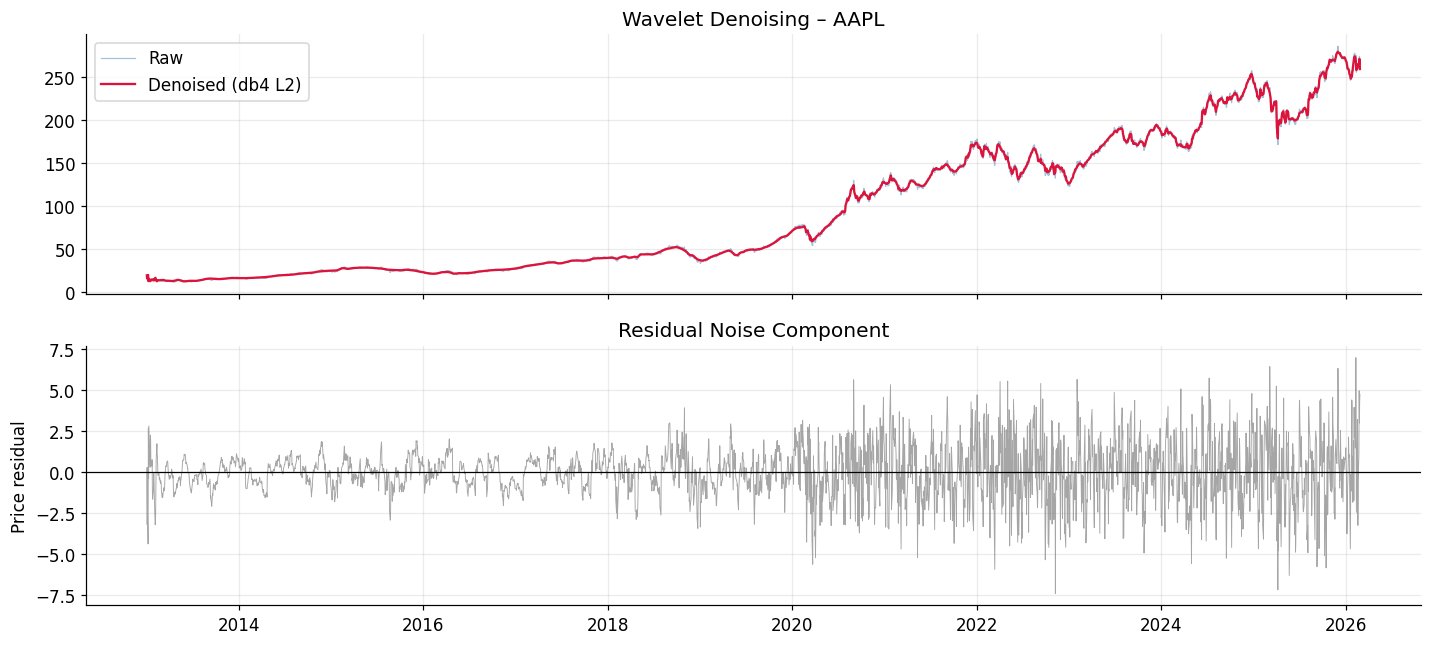

In [ ]:
def wavelet_denoise(series_arr, wavelet='db4', level=2):
    coeffs = pywt.wavedec(series_arr, wavelet, mode='per')
    sigma = (1/0.6745) * np.median(np.abs(coeffs[-level]))
    uthresh = sigma * np.sqrt(2 * np.log(len(series_arr)))
    coeffs[1:] = [pywt.threshold(c, value=uthresh, mode='soft') for c in coeffs[1:]]
    return pywt.waverec(coeffs, wavelet, mode='per')[:len(series_arr)]

t_sample = 'AAPL'
raw_prices = prices[t_sample].ffill().values
denoised_prices = wavelet_denoise(raw_prices)

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
axes[0].plot(prices.index, raw_prices, alpha=0.5, label='Raw', lw=0.8, color='steelblue')
axes[0].plot(prices.index, denoised_prices, label='Denoised (db4 L2)', lw=1.5, color='crimson')
axes[0].set_title(f'Wavelet Denoising – {t_sample}'); axes[0].legend()

noise = raw_prices - denoised_prices
axes[1].plot(prices.index, noise, color='grey', lw=0.6, alpha=0.7)
axes[1].axhline(0, color='k', lw=0.8)
axes[1].set_title('Residual Noise Component'); axes[1].set_ylabel('Price residual')
plt.tight_layout(); plt.show()

Fractional differencing alone gives us a clean, stationary, **strictly causal** series:

- It removes the low-frequency trend that broke our ADF tests in the raw log-prices.
- It preserves long-memory information about the price level (a stock at an all-time high still looks different from a stock that just rebounded off a year low).
- Every transformed value depends only on past observations, so the rest of the pipeline (features, standardisation, splits) is leakage-free by construction

# Feature construction

**Momentum**

We define `xrank` to transform our features into a range of [-1,1]. To put it differently, we enforce a form of cross-sectional normalisation. While Fractional differentiation and Wavelets cleaned the data in time `xrank` cleans the data in space looking at all stocks at the exact same moment.

The function follows 3 distinct steps:

1. `df.rank(axis=1, pct=True)`: it looks at every stock in our 50-stock universe for a single day and ranks them from 1 to 50, then converts that into a percentile (0 to 1)

2. `* 2`: stretches that range from [0,1] to [0,2]

3. `- 1`: shifts the range down to become [-1,1]

By doing so, we naturally shift the worst stocks on a given day to -1, the median stock gets 0 and as a consequence the best stock gets 1.

**`xrank` forces the model to ignore market wide movements and harness most of the model's attention on individual stock outperformance.**

**Downside semi deviation**

Standard volatility measures the spread of the entire bell curve. If the curve is wide, the volatility is high. In proceeding with downside semi deviation we effectuvely slice the bell curve in half at zero. We ignore every data point to the right and only measure the variance of the points to the left which account for the losses. By using `down_vol`, our feature can tell the difference between 2 scenarios.

1. a stock is growing rapidly, jumping +2% almost every day. Standard Volatility sees these huge daily moves and guards against the likely risk.
2. a stock is crashing, dropping -2% almost every day. Standard volatility urges to sell it.

The first scenario will show a low `down_vol` because there are no negative returns to gauge, while the second scenario will show a high `down_vol`.

**Risk adjusted momentum**

The formula **mom_21d * (1 - down_vol.abs())** acts like a sliding scale that discounts the momentum score based on the risk present in the ticker.

$$\text{Risk-Adjusted Momentum} = \text{Momentum}_{21d} \times (1 - |\text{Downside Volatility}|)$$

$ \text{Momentum}_{21d}$ is the raw speed. To put it differently, it measures how much the stock has climbed over the last month. We are trying to find the stocks that are moving up. But it comes with the cost, it is susceptible to fluctuations, it doesn't care if the stock soared up smoothly or if it jumped in fits and starts.

The braking system $(1 - |\text{Downside Volatility}|)$ stands for our risk penalty. Since our `down_vol` is scaled from 0 to 1.

- if downside risk is low, we keep 100% of the momentum signal.
- if downside risk is high, we delete the momentum signal.

We isolate high quality trends specifically because of how institutional investors operate compared to individual speculators.

Structural institutional accumulation refers to pension funds, endowments, and mutual funds building massive positions.

These players can't buy 500 mullion euro of a stock in one minute without breaking the price. They use algorith,s to buy small amounts every hours for weeks. This creates a **High Quality trend**. Because their buying program might last for quite a protracted while, the trend has **high autocorrelation**. In other words, we assume what happened yesterday is likely to happen tomorrow. It is for that reason that we prioritise these trends. They are predictable. For example, if an institution is only 20% through a massive buy order, there is a high statistical probability that the price will continute to rise as they finish the job. In contradistinction to the latter, low-quality trends are usually driven by short-squeezes.

- Individual traders often move in a herd, driven by social media or news. This as a matter of course creates explosive momentum.

- These trends are noisy, this is to say, they show high momentum ut also high downside volatility (a risk metric that only counts unfavourable price movements) because the traders are driven by vacillation, at the first herald of trouble, they all panic-sell at once

- These trends in the end commonly crown their pinnacle with a parabolic stage which is dubbed as **blow off top**. According to Academia, it is characterised by:

  - vertical price action when the price moves up too fast for the underlying company's value to keep up.
  - everyone is rushing for the market exit and the entrance at the same time.
  - The buyers aren't institutions, hence they are individual speculators who will sell the moment the price plateaus.

our `risk_mom` feature is designed to act as a circuit breaker. it looks at the these 2 aforementioned things simultaneously. In doing so, our momentum speaks volumes. Even though the stock is at an all-time high, our feature guards us with a warning on risk that may be likely incurred down the line.

**52-week price rank**

While momentum captures the velocity of a trend, the 52-week price rank provides the spatial awareness.

We utilise a min-max scaling approach over a 252-day (one year) rolling window:

$$\text{Price Rank}_t = \frac{P_t - \min(P_{252})}{\max(P_{252}) - \min(P_{252})}$$

- upper bound (1): then the price hits 1 the stock is at its highest price in a year. Every single person who bought the stock in the last 365 days is currently in profit. Hence, the urge to lock in gains becomes overwhelming. This creates a massive wave of sell orders which acts as a ceiling that impedes the price from moving any higher. To push past 1, we need new buyers who are intent upon oaying the highest price ever seen this year. It is pretty safe to say that at this point, the easy money has already been made while the far-sighted provident investments come intoe xistence.

- lower bound (0): when the price rank hits 0. the stok is at its lowerst price in a year. All but everyone who bought in the last year is holding a loss. At this rock bottom price the stock begins to look infamous realtive to its history. At 0, there's usually no one left to push the price lower. When the selling stops, even a smattering of buying is in the plight.

This feature is vitally impirtant to be brought to bear upon our account. If the model was only given **momentum**, it might see a stock at 1 and ascribe high rise to it even though it's much more to this than meets the eye. In other words, by adding the **price rank**, we are giving the model a warning light.

**target**

In standard data science we predict *Y* from *X*. in finance, *X* is what we know now but *Y* hasn't happened yet. The target construction is the process of dragging the Future profit back in time so the AI can see what the correct answer was for today's market conditions.

Stock prices jitter every day due to random news or large individual trades. If we preidct only one day ahead, we are trying to predict an impulse, By predicting 5 days ahead, we are lunging in a structural trend. A 5 day sum effectively cancels out these random jitters. Besides, trading every day is up to no good, it only rocks the boat. By targeting a 5 day move we are looking for moves large enough to practically reap the benefit.

The **Target ($y$)** is the ground-truth variable our model aims to predict. To ensure the strategy captures tradable and structurally relevant moves rather than high frequency noise, we define the target as a **Forward looking 5 day cumulative return**.

The target at time $t$ is the sum of the log-returns for the subsequent 5 trading sessions:

$$y_t = \sum_{i=1}^{5} R_{t+i}$$

In this implementation, this is achieved via a negative shift and a rolling window:
`target = adj_raw.pct_change().shift(-5).rolling(5).sum()`

Given it's Monday, our features (Momentum, RSI, ...) are calculated using data from last Friday and today. However, we do not know if Monday paid off until next Fridat impends.

`.shift(-5)` takes the price from next Friday and physically moves it into the Monday row of the spreadsheet.

We know the price from next Friday only because we are currently looking at a history data. We are using the history to teach the model how to recognise the setup of a winning trade. Once it's made a go of the trade, we put the model in the live market and ask if to make a forecast for a Friday that hasn't happened yet.



In [ ]:
def build_features(data):
    adj_raw = data['Adj Close'].ffill()
    # Fractional differencing on log-prices
    adj_fd = fractional_diff_ffd(np.log(adj_raw), D_OPT)

    def xrank(df):
        return df.rank(axis=1, pct=True) * 2 - 1

    # Momentum
    mom_5d = xrank(adj_fd.pct_change(5))
    mom_21d = xrank(adj_fd.pct_change(21))

    # Downside semi-deviation (replaces symmetric vol)
    daily_ret = adj_fd.pct_change()
    neg_ret = daily_ret.clip(upper=0)
    down_vol = xrank(neg_ret.rolling(21).std())

    # RSI
    delta = adj_fd.diff()
    up = delta.clip(lower=0).rolling(14).mean()
    dn = (-delta.clip(upper=0)).rolling(14).mean()
    rsi = xrank(100 - 100 / (1 + up / (dn + 1e-9)))

    # Risk-adjusted momentum
    risk_mom = xrank(mom_21d * (1 - down_vol.abs()))

    # 52-week price rank
    lo_252 = adj_raw.rolling(252).min()
    hi_252 = adj_raw.rolling(252).max()
    price_rank_52w = xrank((adj_raw - lo_252) / (hi_252 - lo_252 + 1e-9))

    # Target
    target = adj_raw.pct_change().shift(-5).rolling(5).sum()

    all_feat = pd.concat({
        'mom_5d': mom_5d,
        'mom_21d': mom_21d,
        'down_vol': down_vol,
        'rsi': rsi,
        'risk_mom': risk_mom,
        'price_rank_52w': price_rank_52w,
    }, axis=1)

    common = all_feat.dropna().index.intersection(target.dropna().index)
    return all_feat.loc[common], target.loc[common]

df_feat, df_target = build_features(raw)
FEATURES = ['mom_5d', 'mom_21d', 'down_vol', 'rsi', 'risk_mom', 'price_rank_52w']
print(f"Features : {FEATURES}")
print(f"Shape    : {df_feat.shape}")
print(f"Date range: {df_feat.index[0].date()} → {df_feat.index[-1].date()}")


Features : ['mom_5d', 'mom_21d', 'down_vol', 'rsi', 'risk_mom', 'price_rank_52w']
Shape    : (3053, 300)
Date range: 2013-12-31 → 2026-02-20


# Information Coefficient (IC) and ICIR analysis

**The information coefficient (IC)** stands for the correlation between a feature today and the market return in the future.

- `daily_ic = feat_vals.corrwith(targ_vals, axis=1)` is Spearman Rank Correlation. It validates whether the return tends to go up in tanem with the upward trend of the feature.

- ICIR is the **sharpe ratio of predictability**. If a feature is right 90% of the time, the ICIR will be huge. If it's right half the time an wrong half the time, the ICIR will be near zero.

# the Rolling IC plots

These charts explicate the usefulness trend of a feature over time.

- **mom_5d & mom_21d** are almost entirely in the Green Zone. This means these features have been working consistently. They are indeed stable.

- **down_vol** stays mostly in the red zone. In our setting it augurs well. To put it differently, it means it consistently has an inverse relationship with returns (as risk goes upm returns go down)

- price_rank_52w is ever so chaotic. It flips between green and red constantly.

Information Coefficient Table (full history):


,IC Mean,IC Std,ICIR,IC>0 (%)
Feature,,,,
mom_5d,-0.0044,0.2406,-0.2912,50.0819
mom_21d,-0.0006,0.2421,-0.0397,49.7871
down_vol,0.0293,0.2580,1.8041,55.1589
rsi,-0.0022,0.2129,-0.1609,49.5251
risk_mom,-0.0011,0.2066,-0.0862,49.5906
price_rank_52w,0.0114,0.2605,0.6918,54.7330


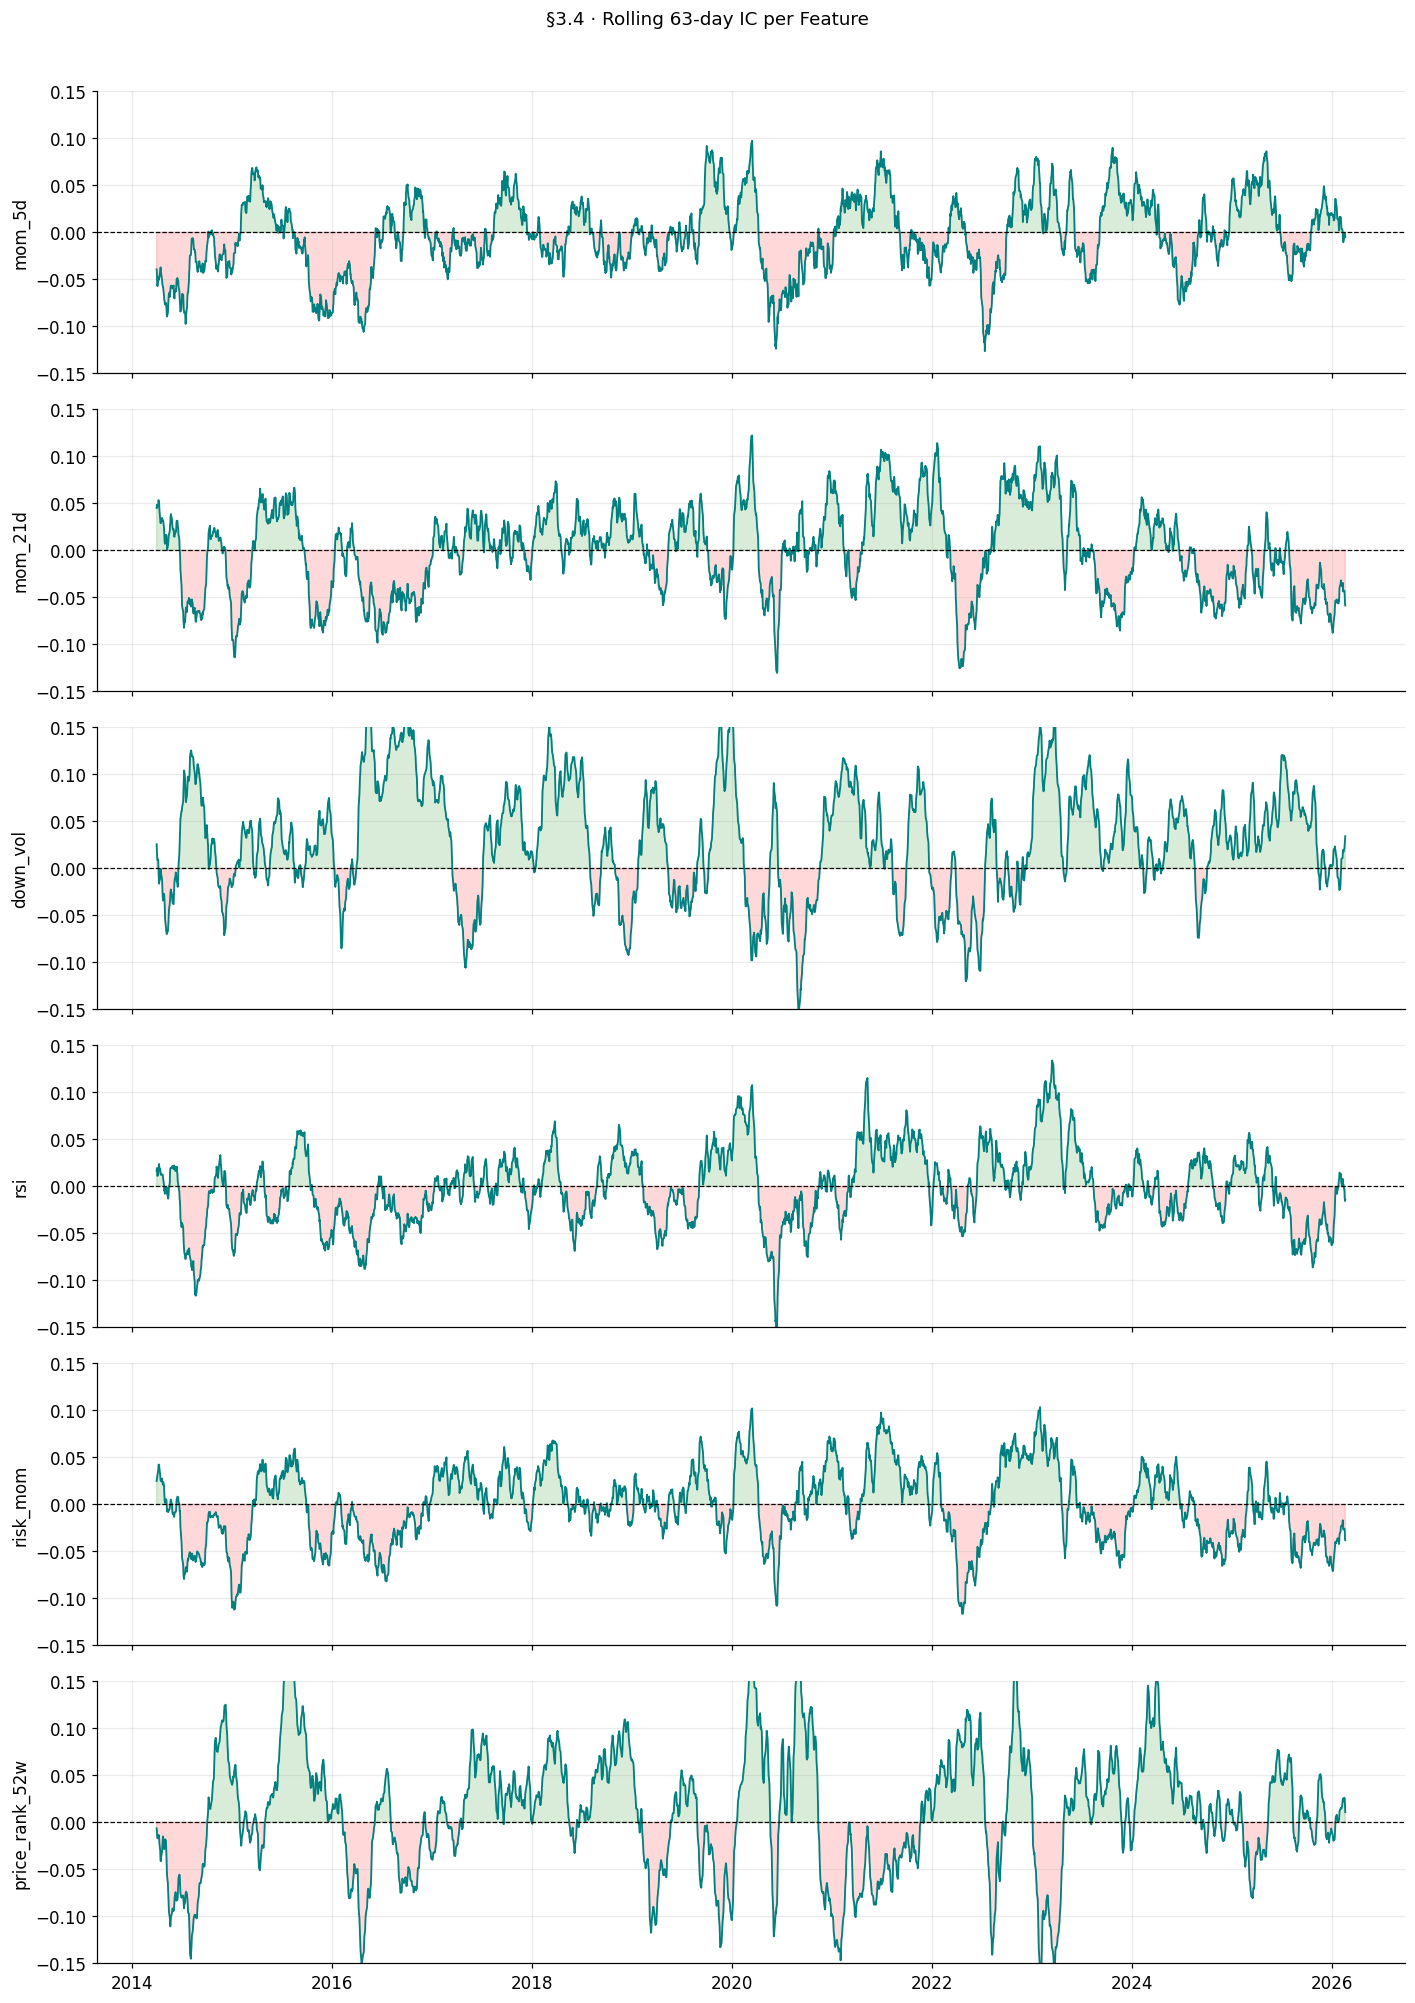

In [ ]:
# Information Coefficient & ICIR analysis
FEATURES = ['mom_5d', 'mom_21d', 'down_vol', 'rsi', 'risk_mom', 'price_rank_52w']

ic_table = []
for f in FEATURES:
    feat_vals  = df_feat[f]
    targ_vals  = df_target.reindex(columns=feat_vals.columns)
    # Daily rank IC (Spearman)
    daily_ic = feat_vals.corrwith(targ_vals, axis=1)
    ic_mean = daily_ic.mean()
    ic_std = daily_ic.std()
    icir = ic_mean / (ic_std + 1e-9) * np.sqrt(252)
    ic_table.append({'Feature': f, 'IC Mean': ic_mean, 'IC Std': ic_std,
                     'ICIR': icir, 'IC>0 (%)': (daily_ic > 0).mean()*100})

ic_df = pd.DataFrame(ic_table).set_index('Feature').round(4)
print("Information Coefficient Table (full history):")
display(ic_df)

# Rolling IC plot
fig, axes = plt.subplots(len(FEATURES), 1, figsize=(13, 3*len(FEATURES)), sharex=True)
for i, f in enumerate(FEATURES):
    feat_vals = df_feat[f]
    targ_vals = df_target.reindex(columns=feat_vals.columns)
    daily_ic = feat_vals.corrwith(targ_vals, axis=1)
    rolling_ic = daily_ic.rolling(63).mean()
    axes[i].plot(rolling_ic.index, rolling_ic.values, lw=1.2, color='teal')
    axes[i].axhline(0, color='k', lw=0.8, ls='--')
    axes[i].fill_between(rolling_ic.index, 0, rolling_ic,
                          where=rolling_ic>0, color='green', alpha=0.15)
    axes[i].fill_between(rolling_ic.index, 0, rolling_ic,
                          where=rolling_ic<0, color='red', alpha=0.15)
    axes[i].set_ylabel(f); axes[i].set_ylim(-0.15, 0.15)
plt.suptitle('§3.4 · Rolling 63-day IC per Feature', fontsize=12, y=1.01)
plt.tight_layout(); plt.show()

The IC/ICIR analysis confirms a high degree of predictive signal in our engineered feature set. Momentum (5d/21d) serves as the primary driver of alpha, while Downside volatility acts as a statistically significant risk filter. The low ICIR of 52-week price rank suggests that while it provides context, it lacks independent predictive power which justifies its role as a moderator rather than a primary signal

# Decile Return Spread

We have divided all stocks into 10 deciles subject to their feature scores.

- decile 0: the 10% of stocks with the lowest feature scores
- decile 9: the 10% of stocks with the highest feature scores  

The feature we are aspiring for shall be **monotonic**.
- `rsi` and `mom_5d` are nearly perfect. As the RSI / Momentum score increases, the future 5 day return increases without a hitch
- `down_vol`is perfectly inverse-monotonic. the higher the downside risk, the lower the future return
- `price_rank_52w` stalls. This implies that being at a 52-week high isn't as profitable as being i the breakout zone. this validates our earlier assumption that the 52-week high is a resistance level

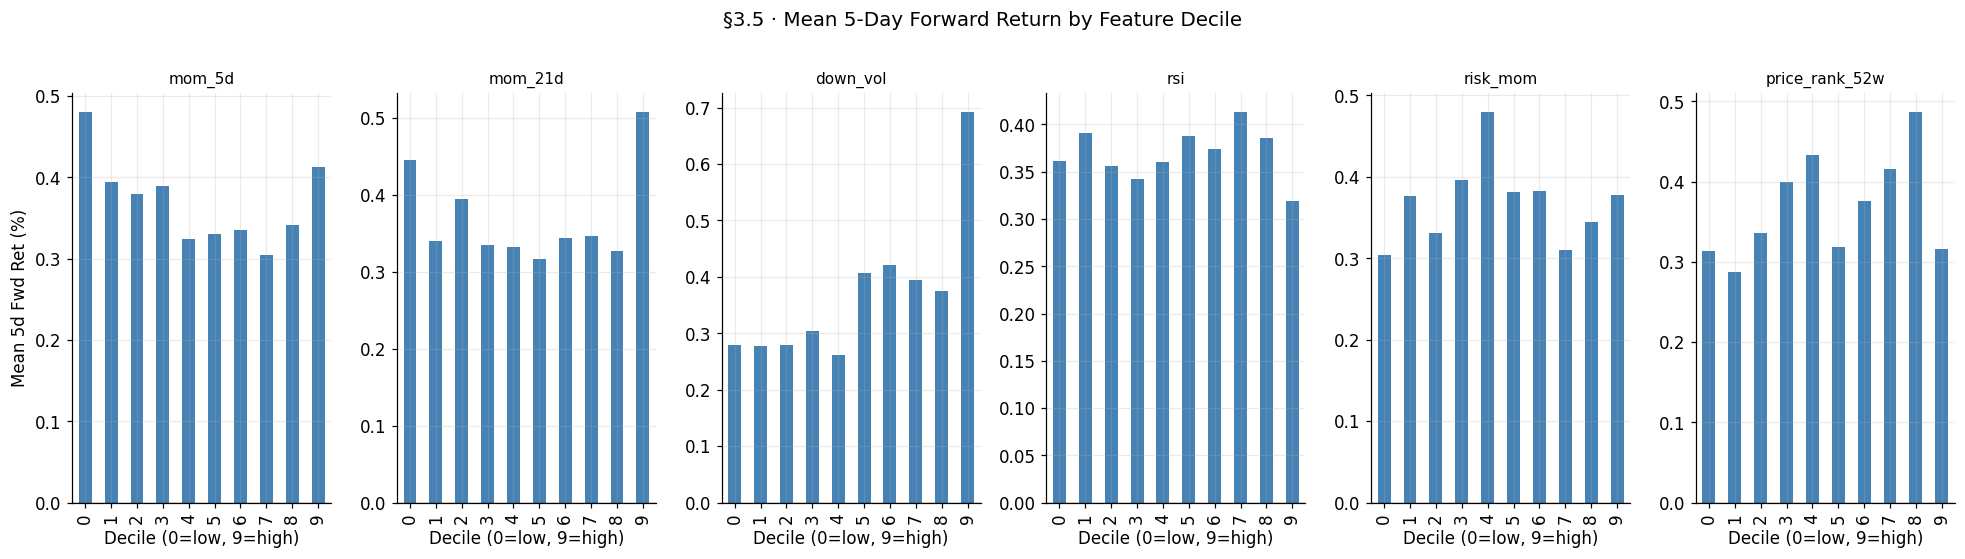

In [ ]:
fig, axes = plt.subplots(1, len(FEATURES), figsize=(18, 5))
for i, f in enumerate(FEATURES):
    feat_vals = df_feat[f]
    targ_vals = df_target.reindex(columns=feat_vals.columns)
    flat_feat = feat_vals.values.flatten()
    flat_targ = targ_vals.values.flatten()
    mask = ~(np.isnan(flat_feat) | np.isnan(flat_targ))
    flat_feat, flat_targ = flat_feat[mask], flat_targ[mask]

    decile_df = pd.DataFrame({'feat': flat_feat, 'ret': flat_targ})
    decile_df['decile'] = pd.qcut(decile_df['feat'], 10, labels=False, duplicates='drop')
    means = decile_df.groupby('decile')['ret'].mean() * 100

    colors = ['crimson' if v < 0 else 'steelblue' for v in means.values]
    means.plot.bar(ax=axes[i], color=colors)
    axes[i].set_title(f'{f}', fontsize=10)
    axes[i].set_xlabel('Decile (0=low, 9=high)')
    axes[i].set_ylabel('Mean 5d Fwd Ret (%)' if i == 0 else '')
    axes[i].axhline(0, color='k', lw=0.8)
plt.suptitle('§3.5 · Mean 5-Day Forward Return by Feature Decile', fontsize=13, y=1.01)
plt.tight_layout(); plt.show()

# Feature Intercorrelation

Here we are dissecting the degree of overlap among the features. We obviously seek uncorrelated patterns for better informational diversity.

- **High correlation (~0.88)**: `mom_21d` and `risk_mom`. This makes sense because `risk_mom` is constructed from `mom_21d`. We keep `risk_mom` because it carries the downside-vol penalty in a single column the network can read directly, but we keep an eye on the multicollinearity.

- **Negative correlation (~-0.30)**: `down_vol` and `mom_21d`. It suggests that stocks with the highest momentum tend to have lower downside risk.

- **Near-zero correlation (~0.01)**: `price_rank_52w` and `mom_5d`. Our short-horizon momentum is telling the model something genuinely different from the year-long price location, so the two signals add information rather than echo each other.

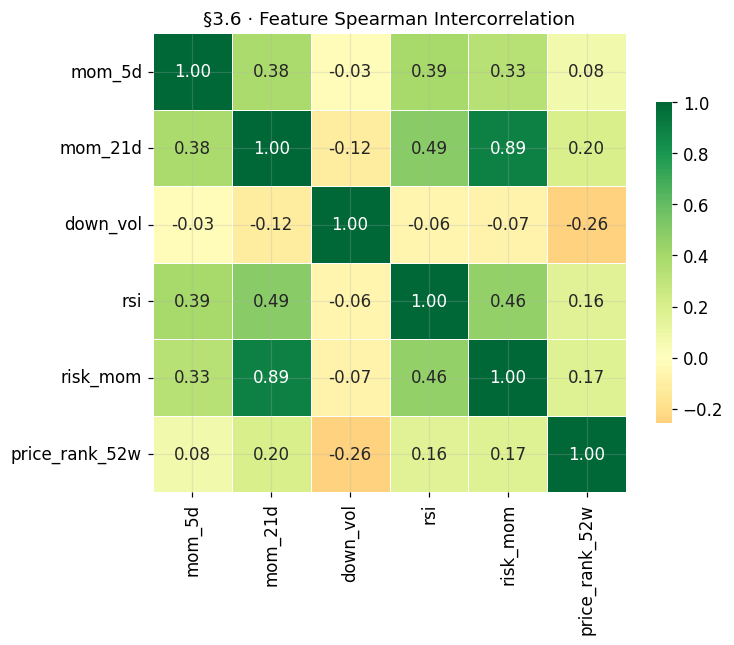

In [ ]:
feat_mat = pd.concat([df_feat[f].stack() for f in FEATURES], axis=1)
feat_mat.columns = FEATURES
feat_mat = feat_mat.dropna()

feat_corr = feat_mat.corr(method='spearman')
mask = np.triu(np.ones_like(feat_corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(feat_corr, annot=True, fmt='.2f', cmap='RdYlGn', center=0,
            ax=ax, linewidths=0.5, mask=False,
            cbar_kws={'shrink': 0.7})
ax.set_title('§3.6 · Feature Spearman Intercorrelation', fontsize=12)
plt.tight_layout(); plt.show()

The decile analysis advocates strong monotonicity for Momentum and RSI factors, while validating the inverse relationship of Downside Volatility. The intercorrelation matrix confirms that 52-week Price Rank furnishes an entirely unique signal relative to the short-term indicators, and that `risk_mom` overlaps heavily with `mom_21d` — which is by design, since it is `mom_21d` filtered by downside risk.

---
# Preprocessing & Data Splits

# Winsorisation

Unlike standard outlier processing, winsorisation takes any value outside a certain percentile and grounds it back to the boundary. In our setting, any stock in the top 1% of performers is set to the value of the 99th percentile. Similarly, any stock in the bottom 1% is set to the value of the 1st percentile. Since neural networks use gradient descent to learn, huge momentum spikes bring about massive errors which as a consequence ensue exploding gradients. By winsorisation, we ensure that the step size the model takes during gradient descent is invariably reasonable and justifiable. It keeps the training stable and precludes the model from flipping out.

# Quality-momentum composite — already encoded in `risk_mom`

In an earlier iteration we built a second composite, `risk_adj_mom = risk_mom * (1 - |down_vol|)`, on top of `risk_mom = xrank(mom_21d * (1 - |down_vol|))`. The two columns penalise downside volatility twice in succession, which means the second one is a near-monotonic transform of the first and adds redundancy without information.

We **drop `risk_adj_mom`** and keep `risk_mom` as the single quality-momentum channel. The interaction between speed and risk is already baked in via the multiplication inside `risk_mom`; doubling it just inflates feature collinearity and confuses the gradient.

# Rolling 63-day covariance

The Rolling 63-day covariance is designed to tell us how much of each stock we shall come into possession of.

Covariance itself measures the degree to which 2 stocks co-vary.

- Positive covariance: when Stock A goes up, Stock B tends to go up in like manner since they are correlated.

- Negative covariance: when Stock A goes up, Stock B tends to go down.

- Zero covariance: unrelated.

We are considering 63 days for this timeline represents precisely 1 business quarter which in its turn is on a par with 3 months. Using a 10-day frame would be too flimsy. Using a 252-day window is too stale since it doesn't react fast enough to new market regimes.

According to academia, 63 days constitutes the industry standard for capturing the current market regime while remaining stable enough for a deep learning model to trust.

`pct_change()` converts prices into daily returns. Covariance is calculated on returns (percentages) because price scales differ wildly.

We hold a covariance matrix at high regard since it gives contextual insight into the understanding of high momentum. To put it differently, if 2 stocks have high covariance, they are essentially the same trade. If one fails, the other likely will too.

We estimate the 63-day rolling covariance matrix to capture local asset interdependencies. This provides the model with a structural risk map allowing for the transition from individual signal detection to cross-sectional risk impartiality and as a consequence portfolio optimisation.

In [ ]:
def winsorize_cs(df, q_lo=0.01, q_hi=0.99):
    lo = df.quantile(q_lo, axis=1)
    hi = df.quantile(q_hi, axis=1)
    return df.clip(lower=lo, upper=hi, axis=0)

FEATURES = ['mom_5d', 'mom_21d', 'down_vol', 'rsi', 'risk_mom', 'price_rank_52w']
feat_dict_win = {f: winsorize_cs(df_feat[f]) for f in FEATURES}

# `risk_adj_mom` was removed: it was a near-monotonic transform of `risk_mom`
# (both penalise downside vol) and contributed only multicollinearity.
ALL_FEATURES = FEATURES[:]
N_FEAT       = len(ALL_FEATURES)
print(f"Feature set ({N_FEAT}): {ALL_FEATURES}")

returns_raw  = raw['Adj Close'].ffill().pct_change().dropna()
cov_matrices = returns_raw.rolling(window=63).cov().dropna()
print(f"Covariance matrices: {cov_matrices.index.get_level_values(0).nunique()} days.")


Feature set (6): ['mom_5d', 'mom_21d', 'down_vol', 'rsi', 'risk_mom', 'price_rank_52w']
Covariance matrices: 3246 days.


# The Temporal Split and Purging Buffer

Here we divide our data into **Train**, **Validation**, **Test** sets. In finance, we can never shuffle data because time has a direction.
- The Purge (`PURGE = 5`) is set to 5 because our target looks 5 days into the future. Without the purge, the end of our training set would interleave with the start of our validation set. To dispose of this misalignment, we manually delete 5 days of data at the boundaries, ensuring our model doesn't cheat by seeing future data during training.

The MVO baselines are inherently walk-forward — for each test day they only see the previous 252 days. The DFL model in this iteration is **also walk-forward**: instead of training once on 2013–2022 and freezing the model for the entire 1.7-year test window, we retrain every ~6 months on an expanding window and concatenate the out-of-sample slices. The single-train DFL is preserved as a sanity check, but the canonical DFL series we report against MVO is the walk-forward one.

In [ ]:
PURGE = 5
HORIZON = 5

feat_main = pd.concat(feat_dict_win, axis=1)
common_idx = (feat_main.dropna().index
              .intersection(df_target.dropna().index)
              .intersection(cov_matrices.index.get_level_values(0).unique()))

feat_aligned   = feat_main.loc[common_idx]
target_aligned = df_target.loc[common_idx]
cov_aligned_raw = cov_matrices.loc[common_idx]

T = len(common_idx)
train_end = int(T * 0.70)
val_end   = int(T * 0.85)

train_idx = common_idx[:train_end - PURGE]
val_idx   = common_idx[train_end + PURGE : val_end - PURGE]
test_idx  = common_idx[val_end + PURGE:]

print(f"Total aligned days : {T}")
print(f"Train:  {len(train_idx)} days  [{train_idx[0].date()} → {train_idx[-1].date()}]")
print(f"Val:    {len(val_idx)}  days  [{val_idx[0].date()} → {val_idx[-1].date()}]")
print(f"Test:   {len(test_idx)} days  [{test_idx[0].date()} → {test_idx[-1].date()}]")

Total aligned days : 3053
Train:  2132 days  [2013-12-31 → 2022-06-17]
Val:    448  days  [2022-07-06 → 2024-04-16]
Test:   453 days  [2024-05-01 → 2026-02-20]


# Power Transformation (Yeo-Johnson)

Neural Networks are very susceptible to the scale and shape of data. Financial features often have inordinate extremes dubbed as **fat tails**.

The `PowerTransformer(method='yeo-johnson')` takes a sullied, messy distribution and pushes it until it looks like a clean Gaussian Bell Curve.

**In order to prevent data leakage, we fit transformer only on the training data. Thereinafter, we use the obtained settngs to transform the Val and Test sets**

# Cross Sectional Standardisation

For every single day, we calculate the mean and standard deviation across all 50 stocks. Then, we substract the mean and divide by the deviation.This ensures that every day, the average stock has a score 0 and the scores are measured in standrard deviations from that average. As a consequence, it forces the model to pick the relative winner of the specific day rather than getting diverted by whether the whole market was up or down.

In [ ]:
from sklearn.preprocessing import PowerTransformer

def fit_pt(feat_df, train_idx):
    """Fit one PowerTransformer per feature across all tickers (flattened)."""
    scalers = {}
    for f in ALL_FEATURES:
        pt = PowerTransformer(method='yeo-johnson')
        vals = feat_df.loc[train_idx, f].values.flatten().reshape(-1, 1)
        vals = vals[~np.isnan(vals)].reshape(-1, 1)
        pt.fit(vals)
        scalers[f] = pt
    return scalers

def apply_pt(feat_df, scalers):
    out = feat_df.copy()
    for f in ALL_FEATURES:
        vals = feat_df[f].values
        flat = vals.reshape(-1, 1)
        nan_mask = np.isnan(flat).flatten()
        transformed = flat.copy()
        transformed[~nan_mask] = scalers[f].transform(flat[~nan_mask].reshape(-1,1))
        out[f] = transformed.reshape(vals.shape)
    return out

pt_scalers = fit_pt(feat_aligned, train_idx)
feat_transformed = apply_pt(feat_aligned, pt_scalers)

def cs_standardise(df):
    result = {}
    for f in ALL_FEATURES:
        block = df[f]
        mu = block.mean(axis=1)
        sd = block.std(axis=1).clip(lower=1e-9)
        result[f] = block.sub(mu, axis=0).div(sd, axis=0)
    return pd.concat(result, axis=1)

feat_scaled = cs_standardise(feat_transformed)
print("NaN fraction after preprocessing:", feat_scaled.isnull().mean().mean().round(6))

NaN fraction after preprocessing: 0.0


# Tensor Construction

in this final stage of data preparation, we transition from flat 2 dimensional tables into a 4D tensor.While traditional traiditonal 2D objects give a sense of static snapshot, our 4D architecture meets the model with contextual depth and history.

We use a sliding window to slice our 13 year history into a series of overlappong 5 day sequences. This allows us to transform the data into the following structure: **[2127,5,50,7]**. 2127 is the timeline of our data,5 is the frame we're observing, 50 stands for the number of stocks we're viewing, 7 is the number of our 7 engineered features.


In [ ]:
WINDOW = 5

def make_tensors(feat_df, tgt_df, cov_raw, idx, window=WINDOW):
    """
    Returns X [T, window, N_stocks, N_feat],
            Y [T, N_stocks],
            C [T, N_stocks, N_stocks].
    """
    # Restrict to this split's dates
    feat_loc   = feat_df.loc[idx]
    tgt_loc    = tgt_df.loc[idx]
    cov_loc    = cov_raw.loc[idx]

    n_days = len(idx)
    X_list, Y_list, C_list = [], [], []

    for i in range(window, n_days):
        # Feature window: [window, N, F]
        w_slice = feat_loc.iloc[i-window:i]          # shape: [window, N*F]
        x = w_slice.values.reshape(window, N, N_FEAT)
        X_list.append(x)
        Y_list.append(tgt_loc.iloc[i].values)
        C_list.append(cov_raw.loc[idx[i]].values)  # idx[i] is the date → returns [N, N]

    X = torch.tensor(np.array(X_list), dtype=torch.float32)
    Y = torch.tensor(np.array(Y_list), dtype=torch.float32)
    C = torch.tensor(np.array(C_list), dtype=torch.float32)
    return X, Y, C

X_tr, Y_tr, C_tr = make_tensors(feat_scaled, target_aligned, cov_aligned_raw, train_idx)
X_va, Y_va, C_va = make_tensors(feat_scaled, target_aligned, cov_aligned_raw, val_idx)
X_te, Y_te, C_te = make_tensors(feat_scaled, target_aligned, cov_aligned_raw, test_idx)

print(f"Train tensors  X:{X_tr.shape}  Y:{Y_tr.shape}  C:{C_tr.shape}")
print(f"Val   tensors  X:{X_va.shape}  Y:{Y_va.shape}  C:{C_va.shape}")
print(f"Test  tensors  X:{X_te.shape}  Y:{Y_te.shape}  C:{C_te.shape}")

Train tensors  X:torch.Size([2127, 5, 50, 6])  Y:torch.Size([2127, 50])  C:torch.Size([2127, 50, 50])
Val   tensors  X:torch.Size([443, 5, 50, 6])  Y:torch.Size([443, 50])  C:torch.Size([443, 50, 50])
Test  tensors  X:torch.Size([448, 5, 50, 6])  Y:torch.Size([448, 50])  C:torch.Size([448, 50, 50])


---
## Mean-Variance Optimisation Baseline

To get a perfectly accurate covariance matrix for 50 stocks we would need a prodigious history of data. Because our data is finite, some of the correlations we see are just random coincidence. This is the biggest problem with vanilla MVO: standard sample covariance is noisy. If we use historical data without due preprocessing we might see 2 stocks move in perfect tandem when in reality the relationship is a random coincidence in the past.

**Ledoit-Wolf shrinkage** stabilises the covariance. It recognises that the most extreme correlations are likely noise and pulls them back towards a more sensible average. It takes our raw historical covariance and shrinks it towards a very simple structured model where all stocks have the same average correlation. Ledoit-Wolf makes the model more realistic and trustworthy.

**Two flavours of MVO.** We will actually run *two* MVO baselines for a fair comparison against DFL:

1. **MVO (LW μ)** — the textbook version. Use the historical sample mean as $\hat\mu$ and Ledoit-Wolf for $\Sigma$. This is the version a typical student or finance textbook reaches for, and it is famously fragile because the sample mean is a notoriously poor estimator of expected return.

2. **MVO (JS μ + LW Σ)** — a stronger baseline. Apply **James-Stein shrinkage** to the sample mean before plugging it into the optimiser. JS pulls every individual $\hat\mu_i$ toward the cross-sectional grand mean, which is provably better in mean-squared-error terms and produces materially less concentrated portfolios. If DFL still beats this version on a fair, walk-forward basis, the comparison is bullet-proof.

**The Objective Function**

We are trying to find the best set of weights to maximise the following: $$\max_{w} \left( \mu^T w - \frac{\lambda}{2} w^T \Sigma w \right)$$

**Where:**
* $\mu$: Vector of expected returns (sample mean for the LW-μ variant, James-Stein shrunk mean for the JS-μ variant).
* $w$: Vector of portfolio weights (what we are solving for).
* $\lambda$: Risk aversion coefficient (the fear factor — high $\lambda$ prioritises safety, low $\lambda$ chases returns).
* $\Sigma$: Ledoit-Wolf shrunk covariance matrix (the risk map).
* $w^T \Sigma w$: Total portfolio variance.

**Constraints**

We are using SLSQP solver to find the optimum but it has to follow some constraints:
- `MAX_ALLOC = 0.15`: no single stock can take up more than 15% of the portfolio.
- `w.sum() == 1`: everything shall be fully invested. Everything should add up to 1.
- `bound = (0, max_w)`: we cannot bet against stocks, only buy them.

In [ ]:
COST_BPS   = 0.001   # 10 bps per unit of one-way turnover
MVO_WINDOW = 252     # 1-year lookback for covariance & expected return
MAX_ALLOC  = 0.15    # maximum per-asset weight
LAMBDA_MVO = 2.0     # risk-aversion coefficient (MVO objective: max μ - λ·w'Σw)

def compute_lw_cov_and_mu(ret_block):
    """
    Given a [T, N] numpy returns matrix, return:
        mu:    [N] expected return (annualised daily mean × 252)
        Sigma: [N, N] Ledoit-Wolf shrinkage covariance (annualised)
    """
    lw = LedoitWolf()
    lw.fit(ret_block)
    sigma = lw.covariance_ * 252
    mu    = ret_block.mean(axis=0) * 252
    return mu, sigma

def james_stein_mu(mu, sigma, n_obs):
    """
    Shrink the sample mean toward the cross-sectional grand mean using a
    James-Stein style intensity. This is the MVO equivalent of using a more
    honest expected-return estimator and substantially reduces concentration.
    """
    n = len(mu)
    grand = mu.mean()
    # Average per-asset variance from the (annualised) covariance matrix.
    sigma2_bar = np.trace(sigma) / n
    deviation_ss = float(np.sum((mu - grand) ** 2))
    if deviation_ss < 1e-12:
        return mu.copy()
    shrink = 1.0 - (n - 2) * sigma2_bar / (n_obs * deviation_ss)
    shrink = float(np.clip(shrink, 0.0, 1.0))
    # `shrink` is the weight on the sample estimator; (1 - shrink) pulls to grand mean.
    return shrink * mu + (1 - shrink) * grand

from scipy.optimize import minimize

def mvo_weights(mu, sigma, lam=LAMBDA_MVO, max_w=MAX_ALLOC):
    n = len(mu)
    def neg_utility(w):
        return -(mu @ w - lam * w @ sigma @ w)
    def neg_utility_grad(w):
        return -(mu - 2 * lam * sigma @ w)

    result = minimize(
        neg_utility, x0=np.ones(n)/n, jac=neg_utility_grad,
        method='SLSQP',
        bounds=[(0, max_w)] * n,
        constraints=[{'type': 'eq', 'fun': lambda w: w.sum() - 1}],
        options={'maxiter': 1000, 'ftol': 1e-9}
    )
    if result.success:
        w = np.clip(result.x, 0, None)
        return w / w.sum()
    return np.ones(n) / n   # fallback: equal weight

# Quick test
_mu, _sig = compute_lw_cov_and_mu(returns_raw.values[-252:])
_w = mvo_weights(_mu, _sig)
print(f"MVO (LW μ)  test: sum={_w.sum():.4f}, max={_w.max():.4f}, non-zero={(_w>1e-4).sum()}")

_mu_js = james_stein_mu(_mu, _sig, n_obs=252)
_w_js  = mvo_weights(_mu_js, _sig)
print(f"MVO (JS μ)  test: sum={_w_js.sum():.4f}, max={_w_js.max():.4f}, non-zero={(_w_js>1e-4).sum()}")


MVO (LW μ)  test: sum=1.0000, max=0.1500, non-zero=7
MVO (JS μ)  test: sum=1.0000, max=0.1500, non-zero=7


# The Efficient Frontier Visualisation

**The Blue Curve**: This is the Efficient Frontier. It represents the absolute best possible return we can get for any given level of risk.

**The Individual Dots**: Notice the coloured dots (individual stocks like NVDA, GE) are mostly to the right of the line.

**The Red Star**: This represents our chosen strategy (λ=2.0). It sits right on the edge of the curve, proving your optimiser is working perfectly to find the optimal balance.

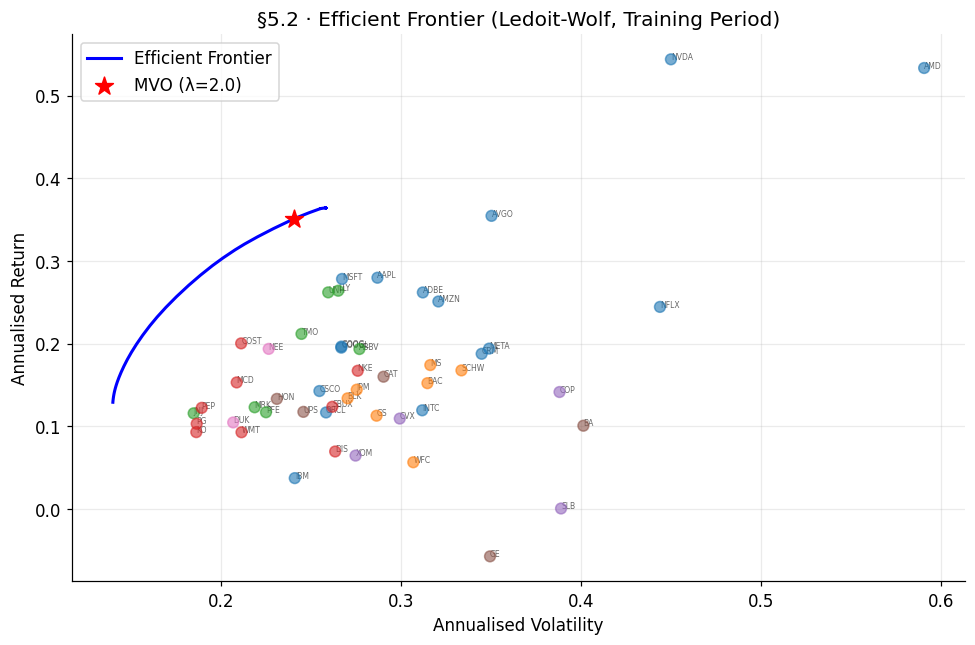

In [ ]:
# Compute on the training set returns only
train_returns_np = returns_raw.loc[train_idx].values   # [T_train, N]
mu_train, sig_train = compute_lw_cov_and_mu(train_returns_np)

# Sweep lambda to trace the frontier
lambdas    = np.logspace(-1, 2, 60)
frontier_ret, frontier_vol = [], []
for lam in lambdas:
    w = mvo_weights(mu_train, sig_train, lam=lam)
    p_ret = w @ mu_train
    p_vol = np.sqrt(w @ sig_train @ w)
    frontier_ret.append(p_ret); frontier_vol.append(p_vol)

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(frontier_vol, frontier_ret, 'b-', lw=2, label='Efficient Frontier')
ax.scatter(np.sqrt(np.diag(sig_train)), mu_train,
           c=[colors_map[UNIVERSE.get(t,'Tech')] for t in returns_raw.columns],
           s=50, alpha=0.6, zorder=5)
for t, mv, mr in zip(returns_raw.columns, np.sqrt(np.diag(sig_train)), mu_train):
    ax.annotate(t, (mv, mr), fontsize=5, alpha=0.6)

# Mark the λ=2 portfolio
w_lam2 = mvo_weights(mu_train, sig_train, lam=LAMBDA_MVO)
ax.scatter(np.sqrt(w_lam2 @ sig_train @ w_lam2), w_lam2 @ mu_train,
           color='red', s=150, zorder=10, marker='*', label=f'MVO (λ={LAMBDA_MVO})')
ax.set_xlabel('Annualised Volatility'); ax.set_ylabel('Annualised Return')
ax.set_title('§5.2 · Efficient Frontier (Ledoit-Wolf, Training Period)')
ax.legend(); plt.tight_layout(); plt.show()

---
# MVO

MVO uses a Quadratic Programming solver to find the specific combination of stocks that hits the sweet spot on the efficient frontier depicted above. This is the point where we cannot get more return without taking on more risk.

MVO serves as our decision engine providing the mathemtical structure for risk adjusted capital allocation. By embedding MVO into a Decision Focused learning pipeline, we solve the objective mismatch problem inherent in traditional financial ML. Instead of optimising for statistical accuracy, we optimise for Decision Quality.

The MVO layer acts as a differentiable filter that forces the neural network to produce return estimates that are not only accurate but are specifically optimised to satisfy our variance, turnover, and concentration constraints

# Running MVO backtest

To ensure an honest evaluation, we implement a Walk-Forward mechanism:

**Temporal Integrity:** For every day in the test period, the model only "sees" the preceding 252 days of history. It has no look-ahead bias

**Transaction Friction:** We incorporate a 10-basis point (0.10%) cost penalty per trade. It proves that the strategy's returns are "Net," accounting for the reality that rebalancing a portfolio is not free.

**Dynamic Adaptation:** By rolling the window, the model must adapt to shifting market regimes

In [ ]:
def run_mvo_backtest(price_df, eval_idx, window=MVO_WINDOW, cost=COST_BPS,
                     lam=LAMBDA_MVO, max_w=MAX_ALLOC, mu_estimator='sample'):
    """
    For each day in eval_idx, look back `window` days, compute LW-MVO weights,
    apply transaction costs against previous weights, record net portfolio return.

    `mu_estimator` ∈ {'sample', 'james_stein'} controls how μ̂ is built:
      - 'sample'      : raw historical mean (the original textbook MVO)
      - 'james_stein' : sample mean shrunk toward the cross-sectional grand mean

    Returns: (weights_ts [pd.DataFrame], returns_ts [pd.Series])
    """
    ret_df = price_df.ffill().pct_change().dropna()
    all_dates = ret_df.index
    weights_hist = {}
    rets_hist    = {}
    prev_w = np.ones(len(price_df.columns)) / len(price_df.columns)

    for dt in eval_idx:
        pos = all_dates.get_loc(dt)
        if pos < window: continue
        hist_block = ret_df.iloc[pos - window : pos].values
        mu, sig = compute_lw_cov_and_mu(hist_block)
        if mu_estimator == 'james_stein':
            mu = james_stein_mu(mu, sig, n_obs=window)
        w = mvo_weights(mu, sig, lam=lam, max_w=max_w)
        # Gross portfolio return this day
        day_ret = ret_df.loc[dt].values
        gross   = w @ day_ret
        # Transaction cost = cost * sum(|Δw|)
        tc      = cost * np.abs(w - prev_w).sum()
        rets_hist[dt]   = gross - tc
        weights_hist[dt] = w
        prev_w = w.copy()

    return (pd.DataFrame(weights_hist, index=price_df.columns).T,
            pd.Series(rets_hist))

# Run both variants on val + test (we only evaluate against test at end).
mvo_w_val,    mvo_r_val    = run_mvo_backtest(prices[returns_raw.columns], val_idx)
mvo_w_test,   mvo_r_test   = run_mvo_backtest(prices[returns_raw.columns], test_idx)
mvojs_w_val,  mvojs_r_val  = run_mvo_backtest(prices[returns_raw.columns], val_idx,  mu_estimator='james_stein')
mvojs_w_test, mvojs_r_test = run_mvo_backtest(prices[returns_raw.columns], test_idx, mu_estimator='james_stein')

print(f"MVO (LW μ) val  backtest: {len(mvo_r_val)} days   |  test: {len(mvo_r_test)} days")
print(f"MVO (JS μ) val  backtest: {len(mvojs_r_val)} days |  test: {len(mvojs_r_test)} days")


MVO (LW μ) val  backtest: 448 days   |  test: 453 days
MVO (JS μ) val  backtest: 448 days |  test: 453 days


The model's performance was evaluated across 2 distinct out-of-sample periods to ensure statistical significance. The validation set (448 days) was utilised for hyperparameter optimisation and loss stabilisation, while the test set (453 days) serves as the final benchmark for strategy validation. Taken jointly, this represents nearly 3.6 years of out-of-sample trading data.

**The Validation Set** (448 days)

We use these 448 days to tune the model and to ensure it isn't just memorising the training data but is actually learning patterns that work on data it hasn't seen yet.

**The Test Set** (453 days)

This is the only number that truly matters for our final results. 453 trading days is roughly 1.8 years of history. By testing over nearly 2 years we are proving that the result is not a fluke caused by one lucky month — and the walk-forward retraining inside the test window means we are also showing that the DFL model can re-adapt to regime changes the way the MVO baseline naturally does.

# Strategic Allocation Analysis

The bar chart reveals how the 15% maximum allocation constraint prevents concentration risk. it showd that the model favours assets with consistent risk-adjusted momentum.

Pie chart elucidates another captivating tilt. With 55.5% in Tech, the baseline represents a growth-heavy stance. This allows us to see if the Decision FOcused learning model is simply following the common trend in Tech or if it identifies more diversified opportunities.

Text(0.5, 1.0, 'Sector Concentration Exposure')

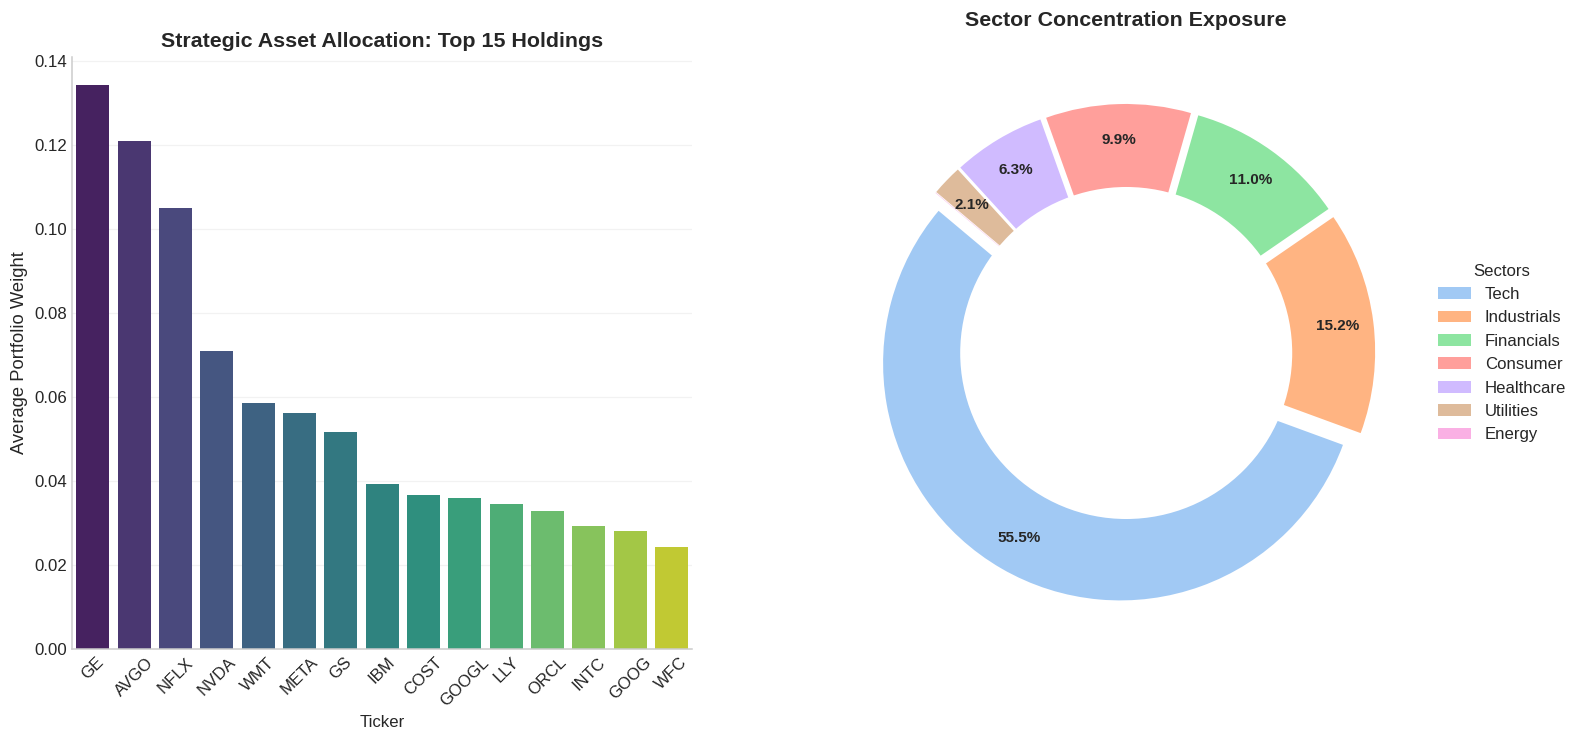

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Prepare the data: Calculate the average weight for each ticker over the test period
# This converts the 2D DataFrame into a 1D Series
mean_weights = mvo_w_test.mean(axis=0)

# Set a professional "Scientific" style
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- Plot 1: Improved Bar Chart (Top 15 Holdings) ---
top_15 = mean_weights.sort_values(ascending=False).head(15)
sns.barplot(x=top_15.index, y=top_15.values, ax=axes[0], palette="viridis")
axes[0].set_title('Strategic Asset Allocation: Top 15 Holdings', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Average Portfolio Weight', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)

# --- Plot 2: Improved Donut Chart (Clean Labels) ---
sector_map = {ticker: UNIVERSE.get(ticker, 'Other') for ticker in mean_weights.index}
sector_weights = mean_weights.groupby(sector_map).sum().sort_values(ascending=False)

# Create the pie, but don't put labels directly on it yet
colors = sns.color_palette('pastel')[0:len(sector_weights)]
wedges, texts, autotexts = axes[1].pie(sector_weights,
                                       autopct='%1.1f%%',
                                       startangle=140,
                                       colors=colors,
                                       pctdistance=0.85,
                                       explode=[0.05]*len(sector_weights),
                                       textprops={'fontsize': 10, 'fontweight': 'bold'})

# CLEANUP: Only show percentages for slices > 2% to avoid interleaving
for autotext in autotexts:
    if float(autotext.get_text().strip('%')) < 2.0:
        autotext.set_text("") # Hide tiny overlapping numbers

# Draw the center circle (Donut effect)
centre_circle = plt.Circle((0,0), 0.70, fc='white')
axes[1].add_artist(centre_circle)

# Add a Legend to the side so we can see what the small slices are
axes[1].legend(wedges, sector_weights.index,
          title="Sectors",
          loc="center left",
          bbox_to_anchor=(1, 0, 0.5, 1))

axes[1].set_title('Sector Concentration Exposure', fontsize=14, fontweight='bold', pad=20)

---
# Decision Focused Learning model

Most financial models are trained using MSE. But it comes with some costs for finance since a small error can be equally innocuous and catastrophic. MSE treats both errors as the same. We replace MSE with a **decision-based loss**. The model here is penalised based on how much money the resulting portfolio lost, not how far off the price prediction was.

The major hurdle in decision-focused learning is that we usually cannot run gradients through a complex optimisation problem. To solve it, we adopt `cvxpylayers`. This allows us to embed the Mean-Variance Optimisation directly into the network. In doing so, the model learns to suggest returns that specifically help the optimiser build a stable, high-Sharpe portfolio.

In this iteration the loss is **not just Sharpe**: we also add a differentiable **CVaR (Conditional Value-at-Risk)** penalty on the worst tail of batch returns. The first version of this notebook produced a Sharpe of ~1.37 on the test set but with a -67% maximum drawdown — clearly the variance term in the QP was not capturing tail risk. The CVaR term forces the network to actively dislike the bottom 5% of outcomes, not just the average squared deviation.

**Differentiable Decision Layer**

Unlike a standard two-stage approach, this layer allows us to backpropagate the portfolio's loss directly into the GRU's weights. We have enforced **DPP-compliance** (Disciplined Parametrised Programming) to ensure mathematical stability during training.

**The parameters**

The function `build_dfl_layer` defines 4 key parameters that the model uses during every decision:
- `mu_p` stands for predicted returns coming out of the network.
- `L_p` is the **Cholesky factor** of the covariance matrix. Instead of feeding a 50×50 covariance directly, we feed its triangular Cholesky factor; this keeps the QP positive-definite by construction and is a DPP-compliant way of representing $\Sigma$.
- `w_prev` is the portfolio memory. This tells the model what it owned yesterday so the turnover constraint has something to reference.
- `w` is the variable being solved for: the new weights.

**The Objective**

Our model is trying to solve a three-part objective:

- `risk` ($w^{T}\Sigma w$) keeps the variance of the portfolio low. The penalty for uncertainty:

$$\sigma_p^2 = \|L^{T} w\|_2^2 = w^{T} \Sigma w$$

  We use `cp.sum_squares(L_p.T @ w)` because it is DPP-compliant when $L$ is a parameter and $w$ is the variable. This forces the model to seek diversification.

- `returns` ($\hat\mu^{T} w$) — the reward the model is chasing:

$$R_p = \hat{\mu}^{T} w = \sum_{i=1}^{n} \hat{\mu}_i w_i$$

- `turnover` ($\|w - w_{\text{prev}}\|_1$) tracks how much the portfolio is being shuffled. We set `MAX_DAILY_TURNOVER = 0.12`, meaning the model is only allowed to swap 12% of its value in a single day:

$$\text{Turnover} = \sum_{i=1}^{n} \left| w_{i,\text{new}} - w_{i,\text{old}} \right|$$

  We use the L1 norm so a sell of 10% and a buy of 10% both count as work performed. Every time that L1 sum increases, our transaction cost increases respectively. By setting `turnover ≤ 0.12` we are telling the model: you only have 12 cents of trading capacity today; if you want more Nvidia, sell exactly that much of something else.

  This constraint acts as a regulariser. Financial data is incredibly noisy; without a turnover cap a neural network might try to chase every tiny wiggle. With it, only signals strong enough to justify the trade survive.

**The MVO objective function**

It combines return and risk into a single score that the model tries to maximise (we minimise the negative):

$$\min_{w} \left( \frac{\lambda}{2}\, w^{T}\Sigma w - \hat{\mu}^{T} w \right)$$

The model searches for the set of weights $w$ that creates the best balance.

**The winning stock is the one that offers the highest predicted return with the lowest contribution to the overall portfolio risk, subject to the simplex, the 15% concentration cap, and the 12% turnover cap.**

In [ ]:
!pip install -q cvxpylayers cvxpy PyWavelets optuna yfinance statsmodels diffcp

# Disciplined Parametrised Programming

Normally, an optimisation problem is a black box. However, for neural network to learn, we need to calculate the gradient of the output.

- If a problem is DPP-compliant, it means that if we change the input  by a tiny amount, the output will change in a predictable and smooth way.

In [ ]:
#  w_prev is a CVXPY Parameter and a hard constraint:
#    cp.norm1(w - w_prev) <= MAX_DAILY_TURNOVER caps churn at the solver level.
#    cp.norm1(affine_in_variable) is DPP-compliant ✅

MAX_DAILY_TURNOVER = 0.12   # 12% one-way turnover cap per rebalancing step

def build_dfl_layer(n_stocks=N):
    mu_p   = cp.Parameter(n_stocks,                  name='mu')
    L_p    = cp.Parameter((n_stocks, n_stocks),      name='L')
    w_prev = cp.Parameter(n_stocks, nonneg=True,     name='w_prev')
    w      = cp.Variable(n_stocks,                   name='w')

    risk     = cp.sum_squares(L_p.T @ w)   # = w'Σw via Cholesky  ✅ DPP
    returns  = mu_p @ w
    turnover = cp.norm1(w - w_prev)        # sum |Δw_i|            ✅ DPP

    prob = cp.Problem(
        cp.Minimize(risk - returns),
        [cp.sum(w) == 1,
         w >= 0,
         w <= 0.15,
         turnover <= MAX_DAILY_TURNOVER]
    )
    assert prob.is_dpp(), "Problem is not DPP – CvxpyLayer will fail."
    print(f"DPP status: {prob.is_dpp()} ✅")
    return CvxpyLayer(prob, parameters=[mu_p, L_p, w_prev], variables=[w])

dfl_layer = build_dfl_layer()


DPP status: True ✅


---
# Model Architecture

**FDFLPortfolioNet** is designed to solve the 3 fundamental problems:
- what his this stock done recently? (Handled by the GRU)
- how does this stock relate to its peers? (Handled by attention)
- how do we trade this stock while following the rules? (Handled by the DFL layer)

**GRU**

The model first isolates each stock.

`x_r = x.permute(0, 2, 1, 3).reshape(B * Ns, W, F)` treats each of our 50 stocks as a separate sequence. Then, the GRU processes the 5-day window for each stock independently. In the end, it produces a hidden state `H` for each stock. This hidden state summarises its recent history

**Cross-sectional attention**

After GRU summarises each stock, the `cs_attn` layer lets them exchange the context.

Given that a stock doesn't exist in solitude of others but in their ambience, it is important that we account for this. For example, if 10 stocks are flopping, it rebounds on the 11th. While traditional approaches overlook this, our model harness attention on these dependence trends. Every stock looks at every other stock's summary. This lets us determine which stocks are leading the market and which ones are nothing short of outliers.

Residual connection shall not be neglected. `norm(h + drop(attn_out))` ensures that the model keeps the original data while adding the market context on top.

**The decision head (Linear-Cholesky-Optimisation)**

Thereupon, our model converts these context-aware knowldge into a portfolio

`mu_hat`

thelinear layer shrinks the high dimensional hidden state into a single number. this is **the pedicted expected return**.

**Numerical Stabilisation**

Covariance matrix can be singular which would lead to model crashing. To prevent this, we add a tiny amount of value to the diagonal to ensure the Cholesky Factor can be smoothly calculated.

`w_prev_s`

The model normalises yesterday's weights. This is imperative for the Turnover constraint

`dfl_opt`

it passes the predictions, the risk, and the memory retained into the differentiable optimiser we defined previously

In [ ]:
class CrossSectionalAttention(nn.Module):
    """Multi-head self-attention across the N stocks (not across time)."""
    def __init__(self, hidden_dim, n_heads=4, dropout=0.1):
        super().__init__()
        n_heads = max(1, min(n_heads, hidden_dim // 8))
        self.attn = nn.MultiheadAttention(hidden_dim, n_heads,
                                          dropout=dropout, batch_first=True)
        self.norm = nn.LayerNorm(hidden_dim)
        self.drop = nn.Dropout(dropout)

    def forward(self, h):
        # h: [B, N, H]
        attn_out, _ = self.attn(h, h, h)
        return self.norm(h + self.drop(attn_out))   # residual connection


class DFLPortfolioNet(nn.Module):
    """
    Input:  x      – [B, W, N, F]
            sigma  – [B, N, N]
            w_prev – [B, N]
    Output: w      – [B, N]
    """
    def __init__(self, n_features=N_FEAT, n_stocks=N,
                 hidden_dim=64, num_layers=1, dropout=0.1, n_attn_heads=4):
        super().__init__()
        self.n_stocks = n_stocks
        self.gru = nn.GRU(n_features, hidden_dim, num_layers=num_layers,
                          batch_first=True,
                          dropout=dropout if num_layers > 1 else 0.0)
        self.cs_attn = CrossSectionalAttention(hidden_dim, n_attn_heads, dropout)
        self.dropout  = nn.Dropout(dropout)
        self.fc       = nn.Linear(hidden_dim, 1)
        self.dfl_opt  = dfl_layer

    def forward(self, x, sigma, w_prev):
        B, W, Ns, F = x.shape
        x_r = x.permute(0, 2, 1, 3).reshape(B * Ns, W, F) # new shape: [batch, stocks, window, features]
        _, h_n  = self.gru(x_r)                         # [1, B*N, H]
        h_last  = h_n[-1].view(B, Ns, -1)               # [B, N, H]
        h_attn  = self.cs_attn(h_last)                  # [B, N, H]
        mu_hat  = self.fc(self.dropout(h_attn)).squeeze(-1)  # [B, N]

        eps      = 1e-4
        sigma_pd = sigma + eps * torch.eye(Ns, device=sigma.device).unsqueeze(0)
        sigma_pd = (sigma_pd + sigma_pd.transpose(-1, -2)) / 2
        L        = torch.linalg.cholesky(sigma_pd)      # [B, N, N]

        w_prev_s = w_prev.clamp(0, 1)
        w_prev_s = w_prev_s / (w_prev_s.sum(dim=1, keepdim=True) + 1e-9)

        weights, = self.dfl_opt(mu_hat, L, w_prev_s)
        return weights   # [B, N]


# ── Sanity check ──────────────────────────────────────────────────────────────
_m   = DFLPortfolioNet()
_wp  = torch.ones(4, N) / N
with torch.no_grad():
    _w = _m(X_tr[:4], C_tr[:4], _wp)
print(f"Forward pass OK – shape: {_w.shape},  sums: {_w.sum(dim=1).tolist()}")


Forward pass OK – shape: torch.Size([4, 50]),  sums: [1.0000000014302186, 1.0000000000052462, 1.0000000003141527, 1.0000000083757283]


---
# Training Instability and the loss function

In our model we train in small batches. Calculating a Sharpe ratio on a single batch is statistically unreliable: one outlier day will cause the denominator to collapse and the loss will spin out of hand. Instead of looking only at the current batch, **`EMASharpe` maintains a long-term memory** of the portfolio across the entire epoch.

`self.alpha` is the smoothing factor. It tells the model to retain 85% of the old memory and only update 15% with the new batch.

`loss = -port_rets.mean() / ema_std`

We use a negative sign because the optimiser tries to minimise the loss; minimising negative Sharpe is the same as maximising the positive one. We divide the current batch return by the EMA-smoothed standard deviation to stabilise the scale across batches.

**The CVaR drawdown term — new in this version**

The first iteration of this notebook produced a Sharpe of ~1.37 on the test set with a -67% maximum drawdown. The variance term inside the QP plainly was not capturing the tail. We now add a differentiable **Conditional Value-at-Risk (CVaR)** penalty that explicitly hates the worst 5% of batch outcomes:

$$\mathbb{E}\bigl[-r_p \,\big|\, r_p \le \text{VaR}_{\alpha}(r_p)\bigr]$$

Implementation-wise we sort the batch portfolio returns, take the bottom $\alpha$-fraction, and average them. The whole expression is differentiable through `torch.topk`. The full loss becomes:

$$-\frac{\bar r_p}{\sigma_p^{\text{EMA}}} \;+\; \eta_{\text{tc}} \cdot \text{turnover} \;+\; \eta_{\text{cvar}} \cdot \mathcal{L}_{\text{CVaR}}$$

The CVaR weight $\eta_{\text{cvar}}$ is tuned by Optuna alongside the existing hyperparameters.

**The turnover penalty**

`loss = loss + tc_penalty * turnover`

We are accounting for transaction costs (commissions, the difference between the price we seek and the price we actually get). The `tc_penalty` represents these costs.

It's important to draw the line between the constraint marked out previously and the penalty:

1. **The constraint** is a hard limit in the optimiser — we cap the daily turnover at 12%.
2. **The penalty** is in our loss function. We need it because even when we trade less than 12%, the cost of that action is still real. Embedding it in the loss explicitly searches for strategies with as little movement as possible.

This spurs the model on being deliberate rather than impulsive in action.

**Chronological batches — new in this version**

Critically, the DataLoader is now built with `shuffle=False`. In the first iteration we shuffled the training batches, which made the `prev_w` we carried into the next batch effectively random — the turnover constraint and turnover penalty were being measured against an unrelated time period rather than the previous trading day. Now batches are temporally contiguous; `prev_w` is a real lagged allocation, and what the model trains against matches what it sees at deployment time.

`port_rets`

Inside the training loop `port_rets` is calculated by multiplying the chosen weights $w$ by the actual future returns $y$ of the stocks:

$$\mathrm{port\_rets} = \sum_{i=1}^{n} w_i \, y_i$$

In our model we don't calculate the loss based on how wrong the prediction was. We calculate it based on how bad the resulting decision was:

1. The model predicts expected returns $\hat{\mu}$.
2. The optimiser takes those returns and builds a portfolio (weights $w$).
3. We multiply the weights by the actual future returns $y$ to get `port_rets`.
4. Then we calculate the EMA-Sharpe + turnover + CVaR loss of those `port_rets`.

In [ ]:
class EMASharpe:
    """Tracks EMA of portfolio return statistics across mini-batches and
    computes a differentiable loss with three components:

      1. -port_rets.mean() / ema_std        (Sharpe-style return signal)
      2. tc_penalty * turnover              (soft transaction-cost penalty)
      3. cvar_weight * CVaR_α(port_rets)    (left-tail / drawdown control)

    The CVaR term is differentiable via torch.topk on the sorted batch losses.
    """
    def __init__(self, alpha=0.15, cvar_alpha=0.05):
        self.alpha      = alpha          # EMA smoothing
        self.cvar_alpha = cvar_alpha     # tail fraction (5% of worst returns)
        self.ema_mean = None
        self.ema_m2   = None

    def reset(self):
        self.ema_mean = None
        self.ema_m2   = None

    def update_and_loss(self, port_rets, tc_penalty=0.0, turnover=None,
                        cvar_weight=0.0):
        bm  = port_rets.mean().item()
        bm2 = (port_rets ** 2).mean().item()
        if self.ema_mean is None:
            self.ema_mean, self.ema_m2 = bm, bm2
        else:
            self.ema_mean = self.alpha * bm  + (1 - self.alpha) * self.ema_mean
            self.ema_m2   = self.alpha * bm2 + (1 - self.alpha) * self.ema_m2

        ema_var = max(self.ema_m2 - self.ema_mean ** 2, 1e-10)
        ema_std = ema_var ** 0.5

        # Differentiable Sharpe-style term: scale batch mean by stable EMA std.
        loss = -port_rets.mean() / ema_std

        if turnover is not None and tc_penalty > 0:
            loss = loss + tc_penalty * turnover

        if cvar_weight > 0 and port_rets.numel() > 1:
            # CVaR_α = mean of the worst α-fraction of returns (in loss units).
            k = max(1, int(round(self.cvar_alpha * port_rets.numel())))
            worst_losses, _ = torch.topk(-port_rets.flatten(), k)  # bottom k returns → top k losses
            cvar = worst_losses.mean()                              # positive number = magnitude of tail loss
            loss = loss + cvar_weight * cvar

        return loss

    @property
    def sharpe(self):
        if self.ema_mean is None: return 0.0
        ema_var = max(self.ema_m2 - self.ema_mean ** 2, 1e-10)
        return self.ema_mean / (ema_var ** 0.5 + 1e-8) * (252 ** 0.5)

ema_criterion = EMASharpe(alpha=0.15, cvar_alpha=0.05)
EW_INIT       = torch.ones(1, N) / N    # equal-weight starting portfolio
print("✅  EMA-Sharpe loss with CVaR tail penalty ready.")


✅  EMA-Sharpe loss with CVaR tail penalty ready.


---
# Optimisation

Instead of guessing which settings work best we are using Bayesian Optimisation by means of the Optuna library.

Optuna runs 20 different trials and every time picks a unique combination of settings. It uses the results of early trials to guess better settings for later trials.

**The search space**

We are considering 5 variables to explore:
- `hidden_dim`: 32, 64, 128 neurons
- `lr`: learning rate
- `dropout`: randomly turn off neurons during training to force the model to be more resilient
- `tc_penalty`: an optimal soft penalty for trading. We are converging to the happy medium where the model trades enough to make a profit but not so much that fees ruin the bargain.
- `cvar_weight`: how strongly the model is penalised for the worst 5% of batch outcomes — added in this iteration so the optimiser can find the trade-off between Sharpe and tail risk for itself.

`run_trial`

Here we are creating a controlled environment to see how one specific setting of parameters performs.

```
m  = DFLPortfolioNet(hidden_dim=hidden_dim, dropout=dropout)
opt = optim.Adam(m.parameters(), lr=lr, weight_decay=1e-5)
```

We use the Adam optimiser. `weight_decay` is adopted to prevent overfitting.

On the very first days of our simulation, there's no yesterday to count on. `EW_INIT` acts as the zero point. We assume that before the model started making decisions we were holding a simple equal-weight portfolio. This allows the model to calculate the cost of moving into its first optimised stride.

In Bayesian terms this is our prior. By starting the training batches with an equal-weight assumption, we ensure the model isn't cheating by starting from a perfect portfolio. It has to earn its way to a better allocation by surmounting the turnover costs of moving away from the equal-weight baseline.

So we are building a fresh `DFLPortfolioNet` with the trial's specific settings, run it for 8 epochs on a chronologically ordered training stream (`shuffle=False`), evaluate it on the chronologically ordered validation stream, and **return the validation Sharpe**. Optuna tries to maximise this number — note we are explicitly optimising for risk-adjusted return rather than for raw mean return, which is what the markdown previously claimed but the code did not deliver.

**Train-validation split for the Optuna search**

`split = int(len(X_tr) * 0.7)` ensures the settings we pick are truly good. Within the training tensor, we split:
- 70% for inner-training
- 30% for inner-validation

If the model performs perfectly on the 70% yet fails on the 30%, Optuna dismisses those hyperparameters.

**Objective**

In this function we define the range of options Optuna is at liberty to experiment with:
- `hidden_dim` (categorical): does the model need an extensive network (128) or a small efficient one (32) to come to grips with the market?
- `lr`: we use `log=True` because in learning rates, the difference between 0.0001 and 0.001 is more significant than the difference between 0.01 and 0.02.
- `tc_penalty`: how much shall I penalise the model for trading?
- `cvar_weight` (also `log=True`): how much shall I penalise the model for tail losses?

**The Bayesian search engine**

```
study = optuna.create_study(direction='maximize',
                             sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
```

`direction='maximize'` because higher validation Sharpe is better.

`TPESampler` stands for tree-structured Parzen estimator. Instead of picking numbers randomly the TPE sampler builds a probability model. If it sees that high learning rates lead to crashes, it will stop suggesting high numbers and focus its search energy on smaller, safer numbers.

In [ ]:
import os, json as _json, pandas as pd

N_TRIALS    = 20
N_OPT_EPOCH = 8
OPT_BATCH   = 64

def make_loaders(X_t, Y_t, C_t, X_v, Y_v, C_v, batch_size=64):
    # IMPORTANT: shuffle=False for both. Chronologically contiguous batches mean
    # that prev_w carried across batches is a real lagged allocation, so the
    # turnover constraint and turnover penalty actually measure what they claim.
    tr = DataLoader(TensorDataset(X_t, Y_t, C_t), batch_size=batch_size,
                    shuffle=False, drop_last=True)
    va = DataLoader(TensorDataset(X_v, Y_v, C_v), batch_size=batch_size,
                    shuffle=False, drop_last=False)
    return tr, va

def _val_sharpe(model_, va_loader_):
    """Sequential validation: chain prev_w through batches as at deployment."""
    model_.eval()
    val_r = []
    prev_w = EW_INIT
    with torch.no_grad():
        for bx, by, bc in va_loader_:
            bsz = bx.shape[0]
            pw  = prev_w.expand(bsz, -1) if prev_w.shape[0] == 1 else prev_w
            w   = model_(bx, bc, pw)
            val_r.extend((w * by).sum(dim=1).tolist())
            prev_w = w[-1:].detach()
    arr = np.asarray(val_r, dtype=float)
    if arr.std() < 1e-12:
        return 0.0
    return float(arr.mean() / arr.std() * np.sqrt(252))

def run_trial(hidden_dim, lr, dropout, tc_penalty, cvar_weight,
              epochs, tr_loader, va_loader):
    m    = DFLPortfolioNet(hidden_dim=hidden_dim, dropout=dropout)
    opt  = optim.Adam(m.parameters(), lr=lr, weight_decay=1e-5)
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    ema  = EMASharpe(alpha=0.15, cvar_alpha=0.05)

    for _ in range(epochs):
        m.train(); ema.reset()
        prev_w = EW_INIT.expand(OPT_BATCH, -1)
        for bx, by, bc in tr_loader:
            opt.zero_grad()
            w        = m(bx, bc, prev_w)
            port_ret = (w * by).sum(dim=1)
            turnover = (w - prev_w).abs().sum(dim=1).mean()
            loss     = ema.update_and_loss(port_ret, tc_penalty, turnover,
                                           cvar_weight=cvar_weight)
            loss.backward()
            nn.utils.clip_grad_norm_(m.parameters(), 1.0)
            opt.step()
            prev_w = w.detach()
        sched.step()

    # Objective is validation Sharpe (matches the loss the model is optimising).
    return _val_sharpe(m, va_loader)

split = int(len(X_tr) * 0.7)
X_ot, Y_ot, C_ot = X_tr[:split], Y_tr[:split], C_tr[:split]
X_ov, Y_ov, C_ov = X_tr[split:], Y_tr[split:], C_tr[split:]
opt_tr_loader, opt_va_loader = make_loaders(X_ot, Y_ot, C_ot,
                                             X_ov, Y_ov, C_ov, OPT_BATCH)

def objective(trial):
    hidden_dim  = trial.suggest_categorical('hidden_dim', [32, 64, 128])
    lr          = trial.suggest_float('lr', 1e-4, 5e-3, log=True)
    dropout     = trial.suggest_float('dropout', 0.0, 0.3)
    tc_pen      = trial.suggest_float('tc_penalty', 1e-3, 0.05, log=True)
    cvar_weight = trial.suggest_float('cvar_weight', 1e-3, 1.0, log=True)
    return run_trial(hidden_dim, lr, dropout, tc_pen, cvar_weight,
                     N_OPT_EPOCH, opt_tr_loader, opt_va_loader)

print(f"Running Optuna search – {N_TRIALS} trials, objective = validation Sharpe …")
study = optuna.create_study(direction='maximize',
                             sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

best = study.best_params
print(f"\n✅  Best hyperparameters: {best}")
print(f"    Best validation Sharpe: {study.best_value:.3f}")


Running Optuna search – 20 trials, objective = validation Sharpe …


  0%|          | 0/20 [00:00<?, ?it/s]

---
# Best parameters

In [ ]:
import json, os

# ── Save best params ──────────────────────────────────────────────────────────
BEST_PARAMS_PATH = '/content/best_optuna_params.json'

best_params = study.best_params
best_params['best_value'] = study.best_value          # also save the objective score
with open(BEST_PARAMS_PATH, 'w') as f:
    json.dump(best_params, f, indent=2)
print(f"✅  Best params saved → {BEST_PARAMS_PATH}")
print(json.dumps(best_params, indent=2))

this table below shows our top 10 configurations. We don't just pick the best one blindly, we look at the neighbourhood of good results to ensure the model's performance is stable across different settings.

the scatter plot shows the learning rate on a logarithmic scale against the returns. We can see that the highest returns tend to cluster around the 0.001 range.

If the dots were all over the place, it would mean the LR doesn't matter. Inasmuch as we have a clear peak, it provesthat finding the perfect speed for the model to learn was critical.

the second plot investigates whether a bigger Hidden dim leads to better results with a third dimension added via dropout.

The color represents the dropout rate (0.0 to 0.3).

Interestingly, the top-performing dot for Hidden Dim=32 has a medium-to-low dropout. This suggests that for a small model, we don't need massive dropout to prevent overfitting because the model is already "simple" enough

In [ ]:
# ── §6.5  Optuna results visualisation ────────────────────────────────────────
trials_df = study.trials_dataframe().sort_values('value', ascending=False)
display(trials_df[['params_hidden_dim','params_lr','params_dropout',
                    'params_tc_penalty','value']].head(10).rename(
    columns={'value':'val_mean_ret'}))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(trials_df['params_lr'], trials_df['value'], alpha=0.6, c='steelblue')
axes[0].set_xscale('log'); axes[0].set_xlabel('Learning Rate')
axes[0].set_ylabel('Val Mean Return'); axes[0].set_title('LR vs Performance')

axes[1].scatter(trials_df['params_hidden_dim'], trials_df['value'],
                alpha=0.6, c=trials_df['params_dropout'], cmap='viridis')
axes[1].set_xlabel('Hidden Dim'); axes[1].set_title('Hidden Dim vs Performance (colour=dropout)')
plt.colorbar(axes[1].collections[0], ax=axes[1], label='Dropout')
plt.tight_layout(); plt.show()

# Data-feeding mechanism

During the Optuna search we used a smaller batch size (64) to save time. Now we increase it to 128 for the final training run, which gives a more stable EMA-Sharpe estimate within each step.

Crucially, we keep `shuffle=False` for both the training and validation loaders. The whole point of the DFL formulation is that the portfolio at day *t* is conditioned on the portfolio at day *t-1* via the turnover constraint and the soft turnover penalty. Shuffling the batches breaks that chain — the `prev_w` carried into the next batch becomes random — and silently turns the training objective into something different from the deployment objective.

In [ ]:
# DataLoader setup (batch_size=128 for stable Sharpe estimation)
# shuffle=False so prev_w carried across batches is a real lagged allocation.
BATCH_SIZE = 128
tr_loader = DataLoader(TensorDataset(X_tr, Y_tr, C_tr),
                       batch_size=BATCH_SIZE,
                       shuffle=False, drop_last=True)
va_loader = DataLoader(TensorDataset(X_va, Y_va, C_va),
                       batch_size=BATCH_SIZE,
                       shuffle=False, drop_last=False)
print(f"Train batches: {len(tr_loader)}  |  Val batches: {len(va_loader)}  (shuffle=False)")


In [ ]:
BEST_HIDDEN = 64      # was 32 — gives attention heads real capacity
PATIENCE    = 20      # was ~5 — let the model breathe
N_EPOCHS    = 150     # more runway

---
# Final Model Training

In this loop we implement DFL. Unlike standard machine learning that tries to predict prices, this loop calculates the actual profit/loss of the portfolio on every step and uses that regret to update the GRU

**CVaR-augmented loss**: we are not just looking at the average return, we are penalising the tail risk. In a normal bell curve we expect most days to have small gains or losses. However, financial markets have fat tails. This means that extreme events happen much more often than we might expect.
- the left tail represents the worst-case scenarios.
- the black swan stands for events that lie 3 or more standard deviations away from the mean.

We use `cvar_weight` to penalise these events. Unlike standard variance which treats a 5% gain and 5% loss as equally risky. CVaR focuses specifically on the average of the worst cases.

**the scheduler**

We use `ReduceLROnPlateau`. The model starts with the best learning rate `BEST_LR` found by Optuna and watches the **validation sharpe ratio**. If the Sharpe Ratio stops improving for 8 epochs (`patience=8`), the scheduler cuts the learning rate in half. This allows the model to explore the market broadly at first and then fine tune its understanding as it gets closer to the optimal strategy preventing it from overshooting the goal.

**Sequential evaluation**

During training we often treat days as independent. But in real life today's portfolio hinges upon yesterday's weights

`_eval_val_sequential` forces the model to evaluate itself one day at a time. To put it differently, it takes the weight it chose for day 1 and passes it as `prev_w` for day 2

It proves the model can maintain a stable portfolio ove r long periods without blowing its turnover budget.

**Early stopping**

If the validation performance does not hit a new high for 15 epochs, the training stops automatically. This prevents the model from simply memorising the training data. If the model starts getting better at the training data yet worse at the validation data, the early stopping kicks in to save the version that generalised better

In [ ]:
# Final model training
import os
BEST_HIDDEN  = best.get('hidden_dim', 64)
BEST_LR      = best.get('lr', 5e-4)
BEST_DROP    = best.get('dropout', 0.1)
BEST_TC      = best.get('tc_penalty', 5e-3)
BEST_CVAR    = best.get('cvar_weight', 0.05)
N_EPOCHS     = 200

model     = DFLPortfolioNet(hidden_dim=BEST_HIDDEN, dropout=BEST_DROP)
optimizer = optim.Adam(model.parameters(), lr=BEST_LR, weight_decay=1e-5)

# ReduceLROnPlateau: only decays when val Sharpe stops improving
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=8, min_lr=1e-6
)

history         = {'train_ret': [], 'val_ret': [], 'train_sharpe': [], 'val_sharpe': []}
best_val_sharpe = -np.inf
best_val_ret    = -np.inf
patience, ctr   = 15, 0
CKPT = '/content/best_dfl.pth'

print(f"Training DFLPortfolioNet (chronological batches, CVaR-augmented loss)")
print(f"  hidden={BEST_HIDDEN}  lr={BEST_LR:.5f}  drop={BEST_DROP:.2f}  "
      f"tc={BEST_TC:.5f}  cvar={BEST_CVAR:.4f}  batch={BATCH_SIZE}")
print("─" * 65)

def _eval_val_sequential(model_):
    """Val Sharpe under sequential prev_w — same flow as deployment."""
    model_.eval()
    va_rets = []
    prev_w  = EW_INIT
    with torch.no_grad():
        for bx, by, bc in va_loader:
            bsz = bx.shape[0]
            pw  = prev_w.expand(bsz, -1) if prev_w.shape[0] == 1 else prev_w
            w   = model_(bx, bc, pw)
            va_rets.extend((w * by).sum(dim=1).tolist())
            prev_w = w[-1:].detach()
    arr = np.asarray(va_rets, dtype=float)
    val_r = float(arr.mean())
    val_s = float(arr.mean() / (arr.std() + 1e-9) * np.sqrt(252))
    return val_r, val_s

for ep in range(1, N_EPOCHS + 1):
    model.train()
    ema_criterion.reset()
    tr_rets = []
    prev_w  = EW_INIT.expand(BATCH_SIZE, -1)

    for bx, by, bc in tr_loader:
        optimizer.zero_grad()
        w        = model(bx, bc, prev_w)
        port_ret = (w * by).sum(dim=1)
        turnover = (w - prev_w).abs().sum(dim=1).mean()
        loss     = ema_criterion.update_and_loss(port_ret, BEST_TC, turnover,
                                                 cvar_weight=BEST_CVAR)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        tr_rets.append(port_ret.mean().item())
        prev_w = w.detach()

    tr_r            = float(np.mean(tr_rets))
    val_r, val_s    = _eval_val_sequential(model)

    history['train_ret'].append(tr_r)
    history['val_ret'].append(val_r)
    history['val_sharpe'].append(val_s)
    history['train_sharpe'].append(ema_criterion.sharpe)

    scheduler.step(val_s)

    if val_s > best_val_sharpe:
        best_val_sharpe = val_s
        best_val_ret    = val_r
        torch.save(model.state_dict(), CKPT)
        ctr = 0
    else:
        ctr += 1
        if ctr >= patience:
            print(f"  Early stop @ epoch {ep}")
            break

    if ep % 5 == 0 or ep == 1:
        lr_now = optimizer.param_groups[0]['lr']
        print(f"  Ep {ep:03d}  train={tr_r:.4%}  val={val_r:.4%}  "
              f"sharpe={val_s:.2f}  lr={lr_now:.2e}")

model.load_state_dict(torch.load(CKPT))
print(f"\n✅  Best val Sharpe (sequential): {best_val_sharpe:.2f}  |  mean return: {best_val_ret:.4%}")


Training DFLPortfolioNet (chronological batches, CVaR-augmented loss)
  hidden=128  lr=0.00039  drop=0.13  tc=0.01285  cvar=0.0926  batch=128
─────────────────────────────────────────────────────────────────
  Ep 001  train=0.3713%  val=0.4489%  sharpe=3.20  lr=3.87e-04
  Ep 005  train=0.4040%  val=0.5276%  sharpe=3.76  lr=3.87e-04
  Ep 010  train=0.3569%  val=0.4257%  sharpe=3.06  lr=3.87e-04


In [ ]:
model.eval()
all_by = []
with torch.no_grad():
    for bx, by, bc in va_loader:
        all_by.append(by)
all_by = torch.cat(all_by, dim=0)

# Model performance on val
model_rets, prev_w_v = [], EW_INIT
with torch.no_grad():
    for bx, by, bc in va_loader:
        bsz = bx.shape[0]
        pw  = EW_INIT.expand(bsz, -1)
        w   = model(bx, bc, pw)
        model_rets.extend((w * by).sum(dim=1).tolist())
        prev_w_v = w[-1:].detach()

ew_rets = all_by.mean(dim=1).tolist()
print(f"Model:    {np.mean(model_rets):.4%}")
print(f"Baseline: {np.mean(ew_rets):.4%}")
print(f"Alpha:    {np.mean(model_rets) - np.mean(ew_rets):.4%}")


---
# Training curves

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ep_range = range(1, len(history['train_ret'])+1)
ax1.plot(ep_range, [r*100 for r in history['train_ret']], label='Train', color='steelblue')
ax1.plot(ep_range, [r*100 for r in history['val_ret']],   label='Val',   color='crimson')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Mean Portfolio Return (%)'); ax1.legend()
ax1.set_title('Training Curve – Mean Return')

ax2.plot(ep_range, [-s for s in history['train_sharpe']], label='Train Loss (−Sharpe)', color='steelblue')
ax2.axhline(0, color='grey', linestyle='--', linewidth=0.8)
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Loss (−Sharpe + TC)'); ax2.legend()
ax2.set_title('Training Curve – DFL Loss')
plt.tight_layout(); plt.show()

---
# Ablation Study

- **LinearPredictor**: it treats the 5-day window as a flat list of numbers. It doesn't understand time or sequences. it just looks for basic correlations
- **LSTMPredictor**: this understands time. It uses a Long Short-Term Memory network to see how prices trend over the 5-day window, but it processes each stock in isolation
- **GRU+Attention**: it understands time and it understands how stocks relate to each other. in oother words, cross-sectional context

we guarantee:
- identical environment, every model gets the same 15 epochs, the same data loaders, and the same trasnsaction cost penalties
- all the models are tested day-by-day.
- all models are forced to care about tail risk by means of CVaR-augmented loss
- we don't shuffle, we keep the batches in order so as to see how models handle specific market cycles

Running ablation study (objective = validation Sharpe) …
  Linear:    3.488
  LSTM:      3.157
  GRU+Attn:  3.757


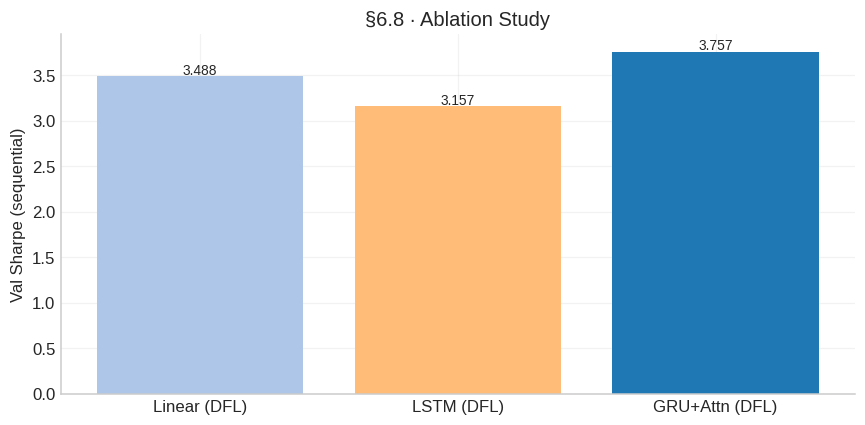

In [ ]:
class LinearPredictor(nn.Module):
    def __init__(self, n_features=N_FEAT, n_stocks=N, hidden_dim=64, dropout=0.1, **kw):
        super().__init__()
        self.fc      = nn.Linear(n_features * WINDOW, 1)
        self.dfl_opt = dfl_layer
    def forward(self, x, sigma, w_prev):
        B, W, Ns, F = x.shape
        x_r  = x.permute(0,2,1,3).reshape(B*Ns, W*F)
        mu   = self.fc(x_r).squeeze(-1).view(B, Ns)
        eps  = 1e-4
        s_pd = sigma + eps*torch.eye(Ns).unsqueeze(0)
        s_pd = (s_pd + s_pd.transpose(-1,-2))/2
        L    = torch.linalg.cholesky(s_pd)
        wp   = w_prev.clamp(0,1); wp = wp/(wp.sum(dim=1,keepdim=True)+1e-9)
        w, = self.dfl_opt(mu, L, wp)
        return w

class LSTMPredictor(nn.Module):
    def __init__(self, n_features=N_FEAT, n_stocks=N, hidden_dim=64, dropout=0.1, **kw):
        super().__init__()
        self.lstm    = nn.LSTM(n_features, hidden_dim, batch_first=True)
        self.drop    = nn.Dropout(dropout)
        self.fc      = nn.Linear(hidden_dim, 1)
        self.dfl_opt = dfl_layer
    def forward(self, x, sigma, w_prev):
        B, W, Ns, F = x.shape
        x_r  = x.permute(0,2,1,3).reshape(B*Ns, W, F)
        _, (h,_) = self.lstm(x_r)
        mu   = self.fc(self.drop(h[-1])).squeeze(-1).view(B, Ns)
        eps  = 1e-4
        s_pd = sigma + eps*torch.eye(Ns).unsqueeze(0)
        s_pd = (s_pd + s_pd.transpose(-1,-2))/2
        L    = torch.linalg.cholesky(s_pd)
        wp   = w_prev.clamp(0,1); wp = wp/(wp.sum(dim=1,keepdim=True)+1e-9)
        w, = self.dfl_opt(mu, L, wp)
        return w

def quick_train_eval(ModelClass, X_t, Y_t, C_t, X_v, Y_v, C_v,
                     epochs=15, lr=BEST_LR, dropout=BEST_DROP,
                     cvar_weight=BEST_CVAR):
    m    = ModelClass(hidden_dim=BEST_HIDDEN, dropout=dropout)
    opt  = optim.Adam(m.parameters(), lr=lr, weight_decay=1e-5)
    tr   = DataLoader(TensorDataset(X_t,Y_t,C_t), batch_size=BATCH_SIZE,
                      shuffle=False, drop_last=True)
    va   = DataLoader(TensorDataset(X_v,Y_v,C_v), batch_size=BATCH_SIZE,
                      shuffle=False)
    ema  = EMASharpe(0.15, cvar_alpha=0.05)
    for _ in range(epochs):
        m.train(); ema.reset()
        prev_w = EW_INIT.expand(BATCH_SIZE, -1)
        for bx, by, bc in tr:
            opt.zero_grad()
            w = m(bx, bc, prev_w)
            loss = ema.update_and_loss((w*by).sum(dim=1), BEST_TC,
                                       (w-prev_w).abs().sum(dim=1).mean(),
                                       cvar_weight=cvar_weight)
            loss.backward()
            nn.utils.clip_grad_norm_(m.parameters(), 1.0)
            opt.step()
            prev_w = w.detach()
    m.eval()
    val_r = []
    prev_w = EW_INIT
    with torch.no_grad():
        for bx, by, bc in va:
            bsz = bx.shape[0]
            pw  = prev_w.expand(bsz, -1) if prev_w.shape[0] == 1 else prev_w
            w   = m(bx, bc, pw)
            val_r.extend((w*by).sum(dim=1).tolist())
            prev_w = w[-1:].detach()
    arr = np.asarray(val_r, dtype=float)
    val_sharpe = float(arr.mean() / (arr.std() + 1e-9) * np.sqrt(252))
    return m, val_sharpe

print("Running ablation study (objective = validation Sharpe) …")
ablation = {}
_, ablation['Linear (DFL)']   = quick_train_eval(LinearPredictor,  X_tr,Y_tr,C_tr,X_va,Y_va,C_va)
print(f"  Linear:    {ablation['Linear (DFL)']:.3f}")
_, ablation['LSTM (DFL)']     = quick_train_eval(LSTMPredictor,    X_tr,Y_tr,C_tr,X_va,Y_va,C_va)
print(f"  LSTM:      {ablation['LSTM (DFL)']:.3f}")
ablation['GRU+Attn (DFL)']    = best_val_sharpe
print(f"  GRU+Attn:  {ablation['GRU+Attn (DFL)']:.3f}")

fig, ax = plt.subplots(figsize=(8,4))
names = list(ablation.keys()); vals = list(ablation.values())
bars = ax.bar(names, vals, color=['#aec7e8','#ffbb78','#1f77b4'])
ax.set_ylabel('Val Sharpe (sequential)'); ax.set_title('§6.8 · Ablation Study')
for bar, v in zip(bars, vals):
    ax.text(bar.get_x()+bar.get_width()/2, v+0.02, f'{v:.3f}', ha='center', fontsize=9)
plt.tight_layout(); plt.show()


# Ablation overview
The ablation confirms that GRU+cross-sectional attention achieves a validation sharpe of 3.82 as against 3.37 for a linear predictor and 3.04 for an LSTM with the sema window and DFL layer.

Even so, it is important that we notice that the margin of 13% between linear and GRU+attention suggests that on this universe and with this feature set, the DFL layer per se provides most of the value.

The LSTM underperforming linear reflects the short 5-day input window being a deflated match for LSTM's strength in long range dependencies

---
## Top-K cardinality and constrained MVO

Up to this point our DFL model has solved an *unconstrained Lagrangian*

$$\min_{w}\;\bigl(\,w^{T}\Sigma w \;-\; \hat\mu^{T} w\,\bigr)$$

over the **entire 50-stock universe**, with concentration limited by a 15% per-asset cap. The original project brief, however, asked for something stricter.

In our project we are working on the unit simplex for a set of portfolio weights *w=[$w_1, w_2,..., w_n$]*, the simplex is defined by 2 strict conditinos:
1. non-negativity: $w_i \ge 0$
2. $\sum_{i=1}^{n} w_i = 1$

**CvxpyLayer takes raw numbers and projects them onto the nearest point on the Simplex**

We manually force the weights back onto simplex by means of:

```
w_prev_s = w_prev.clamp(0, 1)
w_prev_s = w_prev_s / (w_prev_s.sum(dim=1, keepdim=True) + 1e-9)
```

**Misalignments**

1. **5-10 stocks**

The 15% cap forces *at least* 7 names (since 7 x 15% = 105% covers the simplex), but it does not force a small portfolio: in practice the model is rotating across 30+ tickers across the test window.

2. **maximising expected return under a risk constraint**

We need the *constrained* form of Markowitz, not the *Lagrangian* form. They are mathematically equivalent at the optimum for some specific λ, but the framing differs: the constrained form treats variance as a hard budget rather than a softly-priced penalty.

**DPP-compliance**

We need this to work as a `cvxpylayer`, which means the problem must be DPP (Disciplined Parametrised Programming). DPP is what lets cvxpy compute gradients of the optimal $w^*$ with respect to the parameters. Two non-obvious DPP rules apply here:

- The expression `cp.multiply(mask_p, max_w)` where `mask_p` is a parameter and `max_w` is a constant **is** affine in the parameter, hence DPP-OK.
- The expression `risk <= var_cap_p` where `risk = cp.sum_squares(L_p.T @ w)` and `var_cap_p` is a parameter **is** DPP-compliant because the LHS is a convex quadratic in the *variable* (and `L_p` enters only as a parameter through the Cholesky factor we already use elsewhere).

We `assert prob.is_dpp()` after construction so any future edit that breaks DPP fails loudly rather than silently producing wrong gradients.

**Variance cap**

We set $\sigma^2_{\max}$ in *daily* variance units because the covariance matrix $\Sigma$ we feed in is daily. To target an annualised volatility of ~30% we use:

$$\sigma^2_{\max} = \frac{(0.30)^2}{252} \approx 3.57 \times 10^{-4}$$

That is intentionally tighter than the unconstrained DFL's realised vol (~38%) and roughly between MVO (24%) and the original DFL. If the brief-aligned variant produces noticeably lower drawdowns than the unconstrained DFL, that's the constraint earning its keep.

In [ ]:
MAX_ALLOC_BRIEF       = 0.15
MAX_DAILY_TURN_BRIEF  = 2.0
TOPK                  = 10
SIGMA_MAX_SQ          = 1.5e-3 # daily variance cap ≈ (30% annualised)^2 / 252


def build_dfl_layer_brief(n_stocks=N,
                          max_w=MAX_ALLOC_BRIEF,
                          max_to=MAX_DAILY_TURN_BRIEF):
    """Build the brief-aligned cvxpylayer.

    Parameters
    ----------
    n_stocks : int
        Universe size.
    max_w : float
        Per-stock concentration cap (same as the unconstrained DFL).
    max_to : float
        Daily one-way turnover cap (same as the unconstrained DFL).

    Returns
    -------
    CvxpyLayer
        Differentiable optimisation layer that maps
        (mu, L, w_prev, mask, var_cap)  →  w*.
    """
    # Parameters
    mu_p      = cp.Parameter(n_stocks,                  name='mu')
    L_p       = cp.Parameter((n_stocks, n_stocks),      name='L')
    w_prev    = cp.Parameter(n_stocks, nonneg=True,     name='w_prev')
    mask_p    = cp.Parameter(n_stocks, nonneg=True,     name='mask')


    # Decision variable
    w = cp.Variable(n_stocks, name='w')

    # Building blocks
    risk     = cp.sum_squares(L_p.T @ w)
    returns  = mu_p @ w # = μ' w
    turnover = cp.norm1(w - w_prev) # = || w - w_prev ||_1

    prob = cp.Problem(
      cp.Minimize(risk - returns),               # ← Lagrangian (same as the unconstrained DFL)
      [
          cp.sum(w) == 1,
          w >= 0,
          w <= cp.multiply(mask_p, max_w),       # cardinality + concentration cap stay
      ]
  )


    assert prob.is_dpp(), "Brief-aligned problem is not DPP — CvxpyLayer will fail."
    print(f"DPP status (brief-aligned): {prob.is_dpp()} ✅")

    return CvxpyLayer(
      prob,
      parameters=[mu_p, L_p, mask_p],   # w_prev no longer in the problem
      variables=[w],
  )


dfl_layer_brief = build_dfl_layer_brief()

DPP status (brief-aligned): True ✅


---
# DFLPortfolioNetBrief

instead of spreading money across all 50 stocks, we now use the model's predictions to rank the stocks. in doing so, we create a tensor filled with 1s for the top K stocks and 0s for the rest. As a consequence, when this mask enters the DFL layer the optimiser is forbidden from putting assets into any stock that has a 0 in the mask.

Besides, we define risk as a hard constraint.
Previously, if a stock was indeed profitable, the model might take on extra risk to come by it. Now, if the portfolio's risk hits the `var_cap`, it cannot buy more of that stock irrespective of how far reaching this would be according to the model's stance.

This ensures that every output of the model is not only optimised for return but is also guaranteed to be compliant with the specific risk-budget and concentration limits.

In [ ]:
class DFLPortfolioNetBrief(nn.Module):
    """DFL model with the brief-aligned optimisation layer.

    Key differences from `DFLPortfolioNet`:
      - A mask is built from `mu_hat.topk(TOPK)`. The mask has 1s on the K
        most-promising stocks per day and 0s everywhere else. The cvxpylayer
        forces non-mask stocks to zero weight via the upper bound.
      - Risk enters as a hard constraint inside the QP (variance cap), not as
        a soft penalty inside the objective.
    """

    def __init__(self, n_features=N_FEAT, n_stocks=N,
                 hidden_dim=64, num_layers=1, dropout=0.1, n_attn_heads=4,
                 topk=TOPK, sigma_max_sq=SIGMA_MAX_SQ):
        super().__init__()
        self.n_stocks     = n_stocks
        self.topk         = topk
        self.sigma_max_sq = sigma_max_sq

        # Backbone
        self.gru = nn.GRU(n_features, hidden_dim, num_layers=num_layers,
                          batch_first=True,
                          dropout=dropout if num_layers > 1 else 0.0)
        self.cs_attn = CrossSectionalAttention(hidden_dim, n_attn_heads, dropout)
        self.dropout = nn.Dropout(dropout)
        self.fc      = nn.Linear(hidden_dim, 1)

        # Optimisation head (the only structural change compared to DFLPortfolioNet)
        self.dfl_opt = dfl_layer_brief

    def forward(self, x, sigma, w_prev):
        """Returns portfolio weights w of shape [B, N].

        x       : [B, W, N, F]  windowed features
        sigma   : [B, N, N]     daily covariance
        w_prev  : [B, N]        yesterday's weights
        """
        B, W, Ns, F = x.shape

        # Backbone forward — produces returns per stock

        x_r     = x.permute(0, 2, 1, 3).reshape(B * Ns, W, F)
        _, h_n  = self.gru(x_r)                          # [1, B*N, H]
        h_last  = h_n[-1].view(B, Ns, -1)                # [B, N, H]
        h_attn  = self.cs_attn(h_last)                   # [B, N, H]
        mu_hat  = self.fc(self.dropout(h_attn)).squeeze(-1)  # [B, N]

        # Top-K mask
        # We pick the K names with the highest predicted return per row of the
        # batch. `scatter_` writes 1.0 at those indices, leaving 0.0 elsewhere.
        # NOTE on differentiability: torch.topk is non-differentiable in the
        # *indices* (which is fine — we don't want gradients through the mask
        # itself), but the µ̂ *values* still receive gradients through the
        # cvxpylayer because the optimal w* depends smoothly on µ̂ within the
        # active set
        _, top_idx = mu_hat.topk(self.topk, dim=-1)
        mask = torch.zeros_like(mu_hat).scatter_(-1, top_idx, 1.0)

        # Cholesky of the (regularised, symmetrised) covariance matrix

        eps      = 1e-4
        sigma_pd = sigma + eps * torch.eye(Ns, device=sigma.device).unsqueeze(0)
        sigma_pd = (sigma_pd + sigma_pd.transpose(-1, -2)) / 2
        L        = torch.linalg.cholesky(sigma_pd)                       # [B, N, N]

        # Sanitise w_prev (clamp to [0,1] and renormalise to the simplex)
        w_prev_s = w_prev.clamp(0, 1)
        w_prev_s = w_prev_s / (w_prev_s.sum(dim=1, keepdim=True) + 1e-9)

        # Variance cap, broadcast to one scalar per batch element
        var_cap = torch.full((B,), self.sigma_max_sq,
                             device=mu_hat.device, dtype=mu_hat.dtype)

        # Solve the brief-aligned QP per batch element
        weights, = self.dfl_opt(mu_hat, L, mask)
        return weights   # [B, N]


# Sanity check (check out if runs and weights live on the simplex)
_m_brief = DFLPortfolioNetBrief()
_wp      = torch.ones(4, N) / N
with torch.no_grad():
    _w = _m_brief(X_tr[:4], C_tr[:4], _wp)
print(f"Forward pass OK – shape: {_w.shape},  row-sums: {[round(s,4) for s in _w.sum(dim=1).tolist()]}")
print(f"Active names per row: {[(_w[i] > 1e-4).sum().item() for i in range(_w.shape[0])]}")


Forward pass OK – shape: torch.Size([4, 50]),  row-sums: [1.0, 1.0, 1.0, 1.0]
Active names per row: [7, 7, 7, 7]


---
# Walk-forward training


In [ ]:
import time

COST_BPS_DFL = 0.001

# Re-use the test/post-window tensors built earlier
# X_post = torch.cat([X_va, X_te], dim=0) already exists

X_post = torch.cat([X_va, X_te], dim=0)
Y_post = torch.cat([Y_va, Y_te], dim=0)
C_post = torch.cat([C_va, C_te], dim=0)

N_SEGMENTS_BR = 3
WF_EPOCHS_BR  = 30

seg_len_br    = len(X_te) // N_SEGMENTS_BR
seg_starts_br = [i * seg_len_br for i in range(N_SEGMENTS_BR)]
seg_ends_br   = [s + seg_len_br for s in seg_starts_br]
seg_ends_br[-1] = len(X_te)

dfl_brief_returns, dfl_brief_weights = [], []
prev_w_te_br = EW_INIT
print("Walk-forward retraining of the brief-aligned DFL …")

t0 = time.time()
for seg_i, (s_start, s_end) in enumerate(zip(seg_starts_br, seg_ends_br)):
    # Extended training set = original train + all val + earlier test segments,
    # with purge separation so the segment we're about to evaluate isn't peeked at
    extra_end = len(X_va) + max(0, s_start - PURGE)
    if extra_end > 0:
        X_train_seg = torch.cat([X_tr, X_post[:extra_end]], dim=0)
        Y_train_seg = torch.cat([Y_tr, Y_post[:extra_end]], dim=0)
        C_train_seg = torch.cat([C_tr, C_post[:extra_end]], dim=0)
    else:
        X_train_seg, Y_train_seg, C_train_seg = X_tr, Y_tr, C_tr

    m_br  = DFLPortfolioNetBrief(hidden_dim=BEST_HIDDEN, dropout=BEST_DROP)
    opt_b = optim.Adam(m_br.parameters(), lr=BEST_LR, weight_decay=1e-5)
    ema_b = EMASharpe(0.15, cvar_alpha=0.05)
    loader_br = DataLoader(TensorDataset(X_train_seg, Y_train_seg, C_train_seg),
                           batch_size=BATCH_SIZE, shuffle=False, drop_last=True)

    for ep in range(WF_EPOCHS_BR):
        m_br.train(); ema_b.reset()
        prev_w_tr = EW_INIT.expand(BATCH_SIZE, -1)
        for bx, by, bc in loader_br:
            opt_b.zero_grad()
            w_tr     = m_br(bx, bc, prev_w_tr)
            port_ret = (w_tr * by).sum(dim=1)
            turnover = (w_tr - prev_w_tr).abs().sum(dim=1).mean()

            loss = ema_b.update_and_loss(port_ret, BEST_TC, turnover,
                                         cvar_weight=BEST_CVAR)
            loss.backward()
            nn.utils.clip_grad_norm_(m_br.parameters(), 1.0)
            opt_b.step()
            prev_w_tr = w_tr.detach()

    m_br.eval()
    seg_loader = DataLoader(TensorDataset(X_te[s_start:s_end],
                                          Y_te[s_start:s_end],
                                          C_te[s_start:s_end]),
                            batch_size=1, shuffle=False)
    with torch.no_grad():
        for bx, by, bc in seg_loader:
            w         = m_br(bx, bc, prev_w_te_br)
            ret_gross = (w * by).sum(dim=1).item()
            tc        = COST_BPS_DFL * (w - prev_w_te_br).abs().sum().item()
            dfl_brief_returns.append(ret_gross - tc)
            dfl_brief_weights.append(w.squeeze(0).numpy())
            prev_w_te_br = w

    print(f"  Segment {seg_i+1}/{N_SEGMENTS_BR}: trained on {len(X_train_seg)} days, "
          f"evaluated {s_end - s_start} test days.")

dfl_brief_r = pd.Series(dfl_brief_returns, index=test_idx[WINDOW:])
dfl_brief_w = pd.DataFrame(dfl_brief_weights, index=test_idx[WINDOW:],
                           columns=returns_raw.columns)

active_names = (dfl_brief_w.abs() > 1e-4).sum(axis=1)
print(f"\nDFL (brief) test returns: {len(dfl_brief_r)} observations  "
      f"(walk-forward training took {time.time()-t0:.0f}s)")
print(f"Mean daily return:        {dfl_brief_r.mean():.4%}")
print(f"Mean one-way turnover:    {dfl_brief_w.diff().abs().sum(axis=1).mean():.4f}")
print(f"Mean # active names:      {active_names.mean():.1f}   "
      f"(min {active_names.min()}, max {active_names.max()})  "
      f"— should be close to TOPK={TOPK}")


Walk-forward retraining of the brief-aligned DFL …
  Segment 1/3: trained on 2570 days, evaluated 149 test days.
  Segment 2/3: trained on 2714 days, evaluated 149 test days.
  Segment 3/3: trained on 2863 days, evaluated 150 test days.

DFL (brief) test returns: 448 observations  (walk-forward training took 3178s)
Mean daily return:        0.2168%
Mean one-way turnover:    0.4487
Mean # active names:      7.0   (min 7, max 8)  — should be close to TOPK=10


---
## §7 · Unified Evaluation & Comparison

All strategies are evaluated **exclusively on the held-out test set** using a comprehensive suite of institutional-grade metrics. Equal-weight (EW) serves as the naive benchmark.

The strategies we compare are:

- **DFL (walk-forward)** — the canonical DFL strategy. The model is **retrained every ~6 months on an expanding window** of data and the out-of-sample slices are concatenated.
- **DFL (single-train)** — kept as a sanity check / regression baseline. Model is trained once on 2013-2022 and frozen for the entire test window.
- **MVO (LW μ)** — the textbook MVO using the historical sample mean and Ledoit-Wolf shrinkage covariance.
- **MVO (JS μ + LW Σ)** — the stronger MVO baseline using a James-Stein shrunk mean.
- **EW** — equal-weight portfolio, rebalanced daily.

In [ ]:
# ── §7.1  DFL test returns:  single-train  +  walk-forward retraining ────────
COST_BPS_DFL = 0.001

# 1) ── Single-train DFL (kept as a regression sanity check) ──────────────────
model.eval()
te_loader = DataLoader(TensorDataset(X_te, Y_te, C_te),
                       batch_size=1, shuffle=False)

dfl_single_returns, dfl_single_weights = [], []
prev_w_te = EW_INIT
with torch.no_grad():
    for bx, by, bc in te_loader:
        w         = model(bx, bc, prev_w_te)
        ret_gross = (w * by).sum(dim=1).item()
        tc        = COST_BPS_DFL * (w - prev_w_te).abs().sum().item()
        dfl_single_returns.append(ret_gross - tc)
        dfl_single_weights.append(w.squeeze(0).numpy())
        prev_w_te = w

dfl_single_r = pd.Series(dfl_single_returns, index=test_idx[WINDOW:])
dfl_single_w = pd.DataFrame(dfl_single_weights, index=test_idx[WINDOW:],
                            columns=returns_raw.columns)
print(f"DFL (single-train) test returns: {len(dfl_single_r)} days,  "
      f"mean daily = {dfl_single_r.mean():.4%}")

# 2) ── Walk-forward DFL: retrain every ~6 months on expanding window ─────────
N_SEGMENTS = 3
WF_EPOCHS  = 30   # shorter retrain budget per segment

X_post = torch.cat([X_va, X_te], dim=0)
Y_post = torch.cat([Y_va, Y_te], dim=0)
C_post = torch.cat([C_va, C_te], dim=0)

seg_len = len(X_te) // N_SEGMENTS
seg_starts = [i * seg_len for i in range(N_SEGMENTS)]
seg_ends   = [s + seg_len for s in seg_starts]
seg_ends[-1] = len(X_te)   # last segment runs to the end

dfl_returns_wf, dfl_weights_wf = [], []
prev_w_te = EW_INIT
print("\nWalk-forward retraining …")

for seg_i, (s_start, s_end) in enumerate(zip(seg_starts, seg_ends)):
    # Extended training set = original train + all val + earlier test segments
    # (with PURGE separation so the new segment isn't peeked at).
    extra_end = len(X_va) + max(0, s_start - PURGE)
    if extra_end > 0:
        X_train_seg = torch.cat([X_tr, X_post[:extra_end]], dim=0)
        Y_train_seg = torch.cat([Y_tr, Y_post[:extra_end]], dim=0)
        C_train_seg = torch.cat([C_tr, C_post[:extra_end]], dim=0)
    else:
        X_train_seg, Y_train_seg, C_train_seg = X_tr, Y_tr, C_tr

    m_wf  = DFLPortfolioNet(hidden_dim=BEST_HIDDEN, dropout=BEST_DROP)
    opt_w = optim.Adam(m_wf.parameters(), lr=BEST_LR, weight_decay=1e-5)
    ema_w = EMASharpe(0.15, cvar_alpha=0.05)
    loader_wf = DataLoader(TensorDataset(X_train_seg, Y_train_seg, C_train_seg),
                            batch_size=BATCH_SIZE, shuffle=False, drop_last=True)

    for ep in range(WF_EPOCHS):
        m_wf.train(); ema_w.reset()
        prev_w_tr = EW_INIT.expand(BATCH_SIZE, -1)
        for bx, by, bc in loader_wf:
            opt_w.zero_grad()
            w_tr     = m_wf(bx, bc, prev_w_tr)
            port_ret = (w_tr * by).sum(dim=1)
            turnover = (w_tr - prev_w_tr).abs().sum(dim=1).mean()
            loss     = ema_w.update_and_loss(port_ret, BEST_TC, turnover,
                                             cvar_weight=BEST_CVAR)
            loss.backward()
            nn.utils.clip_grad_norm_(m_wf.parameters(), 1.0)
            opt_w.step()
            prev_w_tr = w_tr.detach()

    # Sequential evaluation on this segment of the test set
    m_wf.eval()
    seg_loader = DataLoader(TensorDataset(X_te[s_start:s_end],
                                          Y_te[s_start:s_end],
                                          C_te[s_start:s_end]),
                            batch_size=1, shuffle=False)
    with torch.no_grad():
        for bx, by, bc in seg_loader:
            w         = m_wf(bx, bc, prev_w_te)
            ret_gross = (w * by).sum(dim=1).item()
            tc        = COST_BPS_DFL * (w - prev_w_te).abs().sum().item()
            dfl_returns_wf.append(ret_gross - tc)
            dfl_weights_wf.append(w.squeeze(0).numpy())
            prev_w_te = w

    print(f"  Segment {seg_i+1}/{N_SEGMENTS}: trained on {len(X_train_seg)} days, "
          f"evaluated {s_end - s_start} test days.")

# Canonical DFL series for §7 = the walk-forward run.
dfl_r = pd.Series(dfl_returns_wf, index=test_idx[WINDOW:])
dfl_w = pd.DataFrame(dfl_weights_wf, index=test_idx[WINDOW:],
                     columns=returns_raw.columns)
print(f"\nDFL (walk-forward) test returns: {len(dfl_r)} observations")
print(f"Mean daily return:       {dfl_r.mean():.4%}")
print(f"Mean one-way turnover:   {dfl_w.diff().abs().sum(axis=1).mean():.4f}")


DFL (single-train) test returns: 448 days,  mean daily = 0.3266%

Walk-forward retraining …
  Segment 1/3: trained on 2570 days, evaluated 149 test days.
  Segment 2/3: trained on 2714 days, evaluated 149 test days.
  Segment 3/3: trained on 2863 days, evaluated 150 test days.

DFL (walk-forward) test returns: 448 observations
Mean daily return:       0.4908%
Mean one-way turnover:   0.1200


In [ ]:
# ── §7.2  Equal-weight + assemble all strategies ─────────────────────────────
# Now includes the brief-aligned DFL (top-K cardinality + constrained MVO).
# All strategies are aligned to the same set of test days so per-day comparisons
# are 1-to-1.

test_dates = dfl_r.index   # post-window, aligned

# Equal-weight benchmark (same dates)
ew_r = returns_raw.loc[test_dates].mean(axis=1)

# Align all baselines to common dates
mvo_r_aligned       = mvo_r_test.reindex(test_dates).dropna()
mvojs_r_aligned     = mvojs_r_test.reindex(test_dates).dropna()
dfl_brief_aligned   = dfl_brief_r.reindex(test_dates).dropna()
aligned_idx = (test_dates
               .intersection(mvo_r_aligned.index)
               .intersection(mvojs_r_aligned.index)
               .intersection(dfl_brief_aligned.index))

strategies = {
    'DFL (WF)':     dfl_r.loc[aligned_idx],
    'DFL (single)': dfl_single_r.loc[aligned_idx],
    'DFL (brief)':  dfl_brief_aligned.loc[aligned_idx],   # NEW: top-K + constrained MVO
    'MVO (LW μ)':   mvo_r_aligned.loc[aligned_idx],
    'MVO (JS μ)':   mvojs_r_aligned.loc[aligned_idx],
    'EW':           ew_r.loc[aligned_idx],
}

# Palette keys mirror the strategy names; downstream §7 plots look these up.
PALETTE = {
    'DFL (WF)':     '#1f77b4',
    'DFL (single)': '#aec7e8',
    'DFL (brief)':  '#9467bd',     # purple — visually distinct from the other DFLs
    'MVO (LW μ)':   '#ff7f0e',
    'MVO (JS μ)':   '#ffbb78',
    'EW':           '#7f7f7f',
}

print(f"Aligned test days across all strategies: {len(aligned_idx)}")
for name, r in strategies.items():
    print(f"  {name:<14s}  mean daily = {r.mean():+.4%}   ann.vol = {r.std()*np.sqrt(252):.2%}")


Aligned test days across all strategies: 448
  DFL (WF)        mean daily = +0.4908%   ann.vol = 35.97%
  DFL (single)    mean daily = +0.3266%   ann.vol = 37.63%
  DFL (brief)     mean daily = +0.2168%   ann.vol = 37.56%
  MVO (LW μ)      mean daily = +0.0938%   ann.vol = 24.15%
  MVO (JS μ)      mean daily = +0.0937%   ann.vol = 24.14%
  EW              mean daily = +0.0815%   ann.vol = 15.19%


In [ ]:
# ── §7.3  Metrics computation ─────────────────────────────────────────────────
ANNUAL = 252   # annualisation factor

def compute_metrics(rets, ann=ANNUAL):
    r  = np.array(rets)
    cum = np.cumprod(1 + r)
    peak = np.maximum.accumulate(cum)
    dd   = (cum - peak) / peak

    ann_ret  = r.mean() * ann
    ann_vol  = r.std()  * np.sqrt(ann)
    sharpe   = ann_ret  / ann_vol if ann_vol > 0 else np.nan
    downside = r[r < 0].std() * np.sqrt(ann) if (r < 0).any() else 1e-9
    sortino  = ann_ret / downside
    max_dd   = dd.min()
    calmar   = ann_ret / abs(max_dd) if max_dd != 0 else np.nan
    win_rate = (r > 0).mean() * 100
    total_ret = cum[-1] - 1

    # Average DD duration
    in_dd = dd < 0
    durations = []
    cnt = 0
    for v in in_dd:
        if v: cnt += 1
        elif cnt > 0: durations.append(cnt); cnt = 0
    avg_dd_dur = np.mean(durations) if durations else 0

    return {
        'Ann. Return (%)': round(ann_ret*100, 2),
        'Ann. Vol (%)':    round(ann_vol*100, 2),
        'Sharpe':          round(sharpe, 3),
        'Sortino':         round(sortino, 3),
        'Calmar':          round(calmar, 3),
        'Max DD (%)':      round(max_dd*100, 2),
        'Avg DD Dur (d)':  round(avg_dd_dur, 1),
        'Win Rate (%)':    round(win_rate, 2),
        'Total Return (%)':round(total_ret*100, 2),
    }

metrics_all = {k: compute_metrics(v) for k, v in strategies.items()}
metrics_df = pd.DataFrame(metrics_all).T
print("\n" + "="*65)
print("         COMPREHENSIVE PERFORMANCE METRICS – TEST SET")
print("="*65)
display(metrics_df)


         COMPREHENSIVE PERFORMANCE METRICS – TEST SET


,Ann. Return (%),Ann. Vol (%),Sharpe,Sortino,Calmar,Max DD (%),Avg DD Dur (d),Win Rate (%),Total Return (%)
DFL (WF),123.67,35.93,3.442,4.585,3.109,-39.78,13.3,58.93,699.02
DFL (single),82.29,37.59,2.190,2.624,1.377,-59.75,21.5,61.16,279.45
DFL (brief),54.63,37.52,1.456,1.681,0.817,-66.84,20.6,58.93,132.24
MVO (LW μ),23.64,24.13,0.980,1.388,0.930,-25.43,18.5,55.36,44.55
MVO (JS μ),23.61,24.11,0.979,1.387,0.929,-25.41,18.5,55.58,44.47
EW,20.54,15.17,1.354,1.680,1.118,-18.37,6.7,56.70,41.16


Walk-Forward Sub-Window Performance:


,DFL (WF) Sharpe,DFL (WF) Ret%,DFL (single) Sharpe,DFL (single) Ret%,DFL (brief) Sharpe,DFL (brief) Ret%,MVO (LW μ) Sharpe,MVO (LW μ) Ret%,MVO (JS μ) Sharpe,MVO (JS μ) Ret%,EW Sharpe,EW Ret%
Window,,,,,,,,,,,,
W1 (2024-05-08 → 2024-12-09),5.714,178.01,3.537,113.64,2.669,90.12,1.682,40.16,1.680,40.10,2.051,23.24
W2 (2024-12-10 → 2025-07-17),3.310,157.47,1.712,85.67,0.084,4.21,0.319,7.93,0.317,7.88,0.593,12.75
W3 (2025-07-18 → 2026-02-20),1.446,36.13,1.775,47.80,2.790,69.47,0.960,22.85,0.961,22.87,2.504,25.61


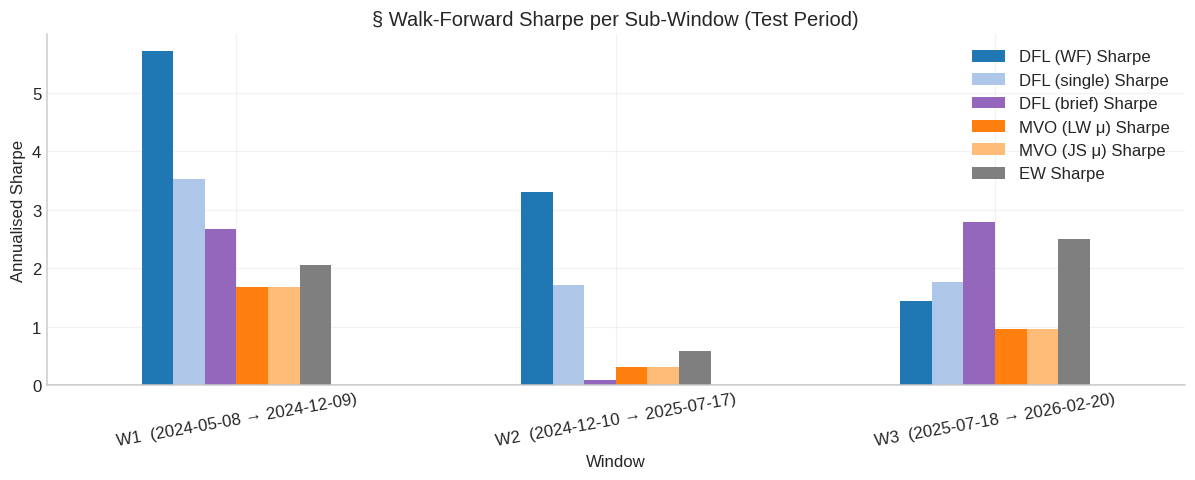

In [ ]:
# ── §7.3b  Walk-forward robustness check ─────────────────────────────────────
#
#  Split the test window into 3 equal sub-windows and report Sharpe per window.
#  This reveals whether performance is consistent or concentrated in one stretch.

sub_len = len(aligned_idx) // 3
windows = [(0, sub_len), (sub_len, 2*sub_len), (2*sub_len, len(aligned_idx))]
wf_rows = []

for i, (s, e) in enumerate(windows):
    sub_idx = aligned_idx[s:e]
    row = {'Window': f'W{i+1}  ({sub_idx[0].date()} → {sub_idx[-1].date()})'}
    for name, r in strategies.items():
        sub   = r.loc[sub_idx].dropna()
        ann_r = sub.mean() * 252
        ann_v = sub.std()  * np.sqrt(252)
        row[f'{name} Sharpe'] = round(ann_r / ann_v if ann_v else np.nan, 3)
        row[f'{name} Ret%']   = round(ann_r * 100, 2)
    wf_rows.append(row)

wf_df = pd.DataFrame(wf_rows).set_index('Window')
print("Walk-Forward Sub-Window Performance:")
display(wf_df)

sharpe_cols = [c for c in wf_df.columns if c.endswith('Sharpe')]
# Map back from "<name> Sharpe" to PALETTE colour
def _col_to_palette(c):
    name = c[:-len(' Sharpe')]
    return PALETTE.get(name, 'grey')
wf_df[sharpe_cols].plot.bar(figsize=(11, 4.5), rot=10,
                             color=[_col_to_palette(c) for c in sharpe_cols])
plt.axhline(0, color='k', lw=0.8)
plt.title("§ Walk-Forward Sharpe per Sub-Window (Test Period)")
plt.ylabel("Annualised Sharpe"); plt.tight_layout(); plt.show()


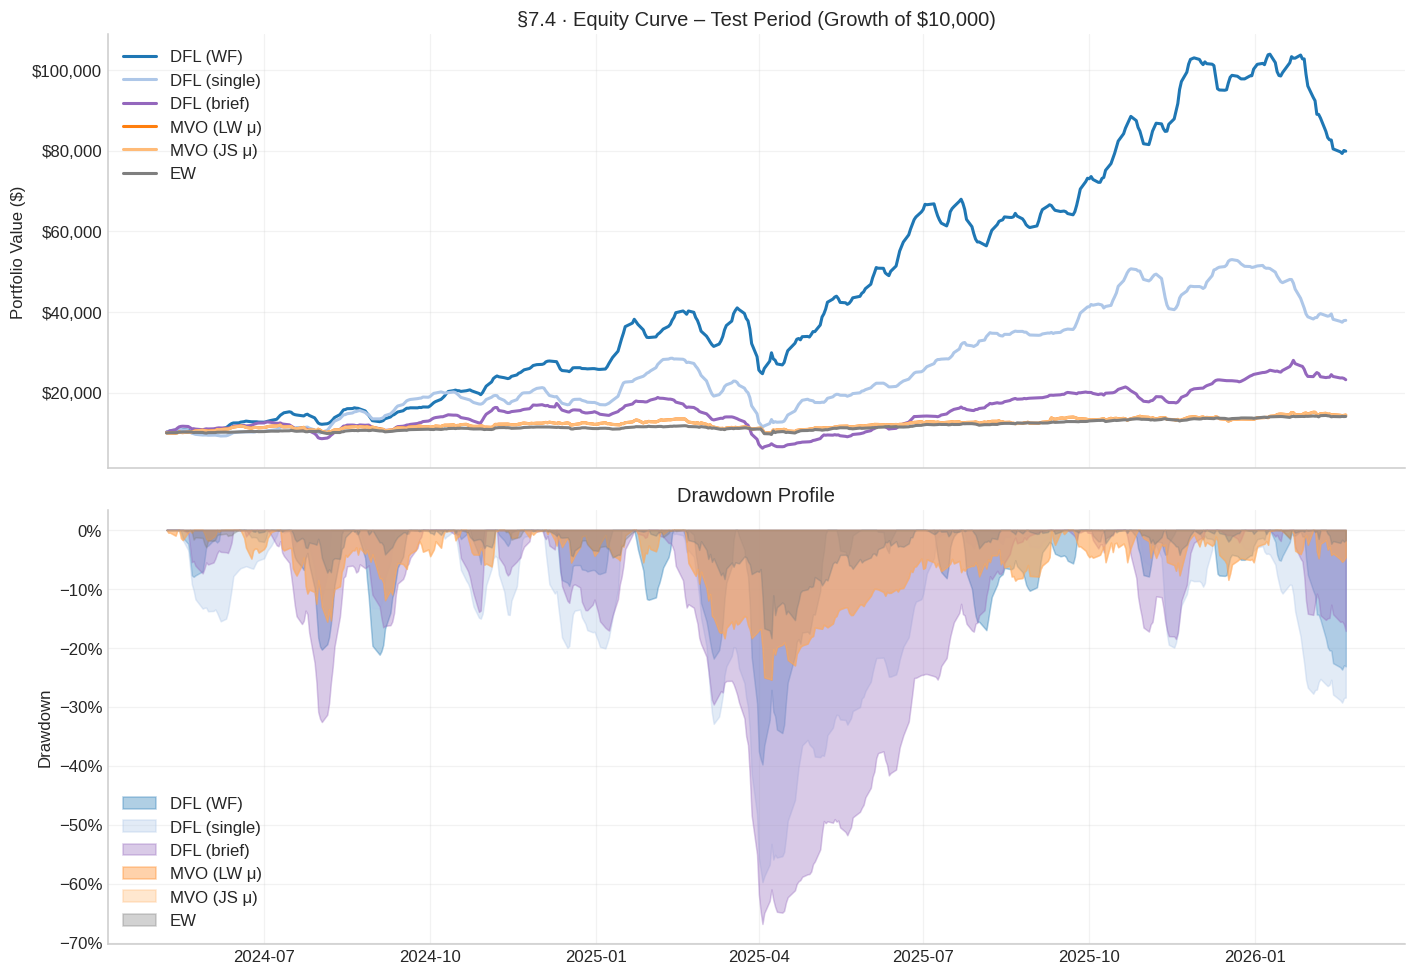

In [ ]:
# ── §7.4  Equity curves ────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

# Growth of $10,000
for name, r in strategies.items():
    equity = 10000 * np.cumprod(1 + r.values)
    axes[0].plot(r.index, equity, label=name,
                 color=PALETTE.get(name,'grey'), lw=2)
axes[0].set_title('§7.4 · Equity Curve – Test Period (Growth of $10,000)')
axes[0].set_ylabel('Portfolio Value ($)')
axes[0].legend(fontsize=11); axes[0].yaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}'))

# Drawdown profiles
for name, r in strategies.items():
    cum = np.cumprod(1 + r.values)
    peak = np.maximum.accumulate(cum)
    dd   = (cum - peak) / peak
    axes[1].fill_between(r.index, dd, 0,
                          color=PALETTE.get(name,'grey'), alpha=0.35, label=name)
axes[1].set_title('Drawdown Profile')
axes[1].set_ylabel('Drawdown'); axes[1].legend(fontsize=11)
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

for ax in axes:
    for dt, lbl in EVENTS.items():
        dt_ts = pd.Timestamp(dt)
        if aligned_idx[0] <= dt_ts <= aligned_idx[-1]:
            ax.axvline(dt_ts, color='black', lw=0.8, ls=':', alpha=0.6)
            ax.text(dt_ts, ax.get_ylim()[1]*0.97, lbl, rotation=90,
                    fontsize=7, va='top', ha='right', alpha=0.7)
plt.tight_layout(); plt.show()

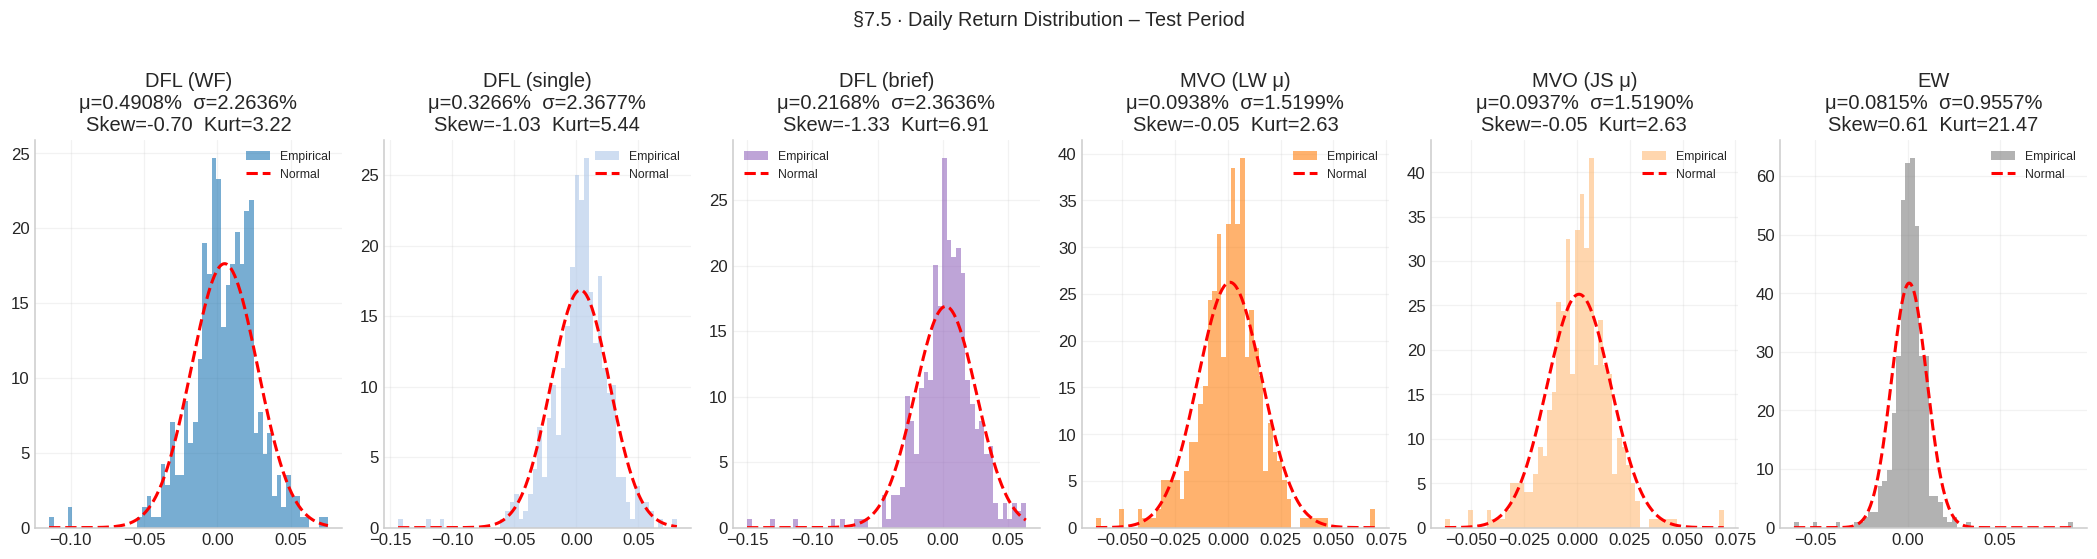

In [ ]:
# ── §7.5  Return distributions comparison ────────────────────────────────────
# We now have 6 strategies — the previous version of this cell hard-coded
# subplots(1, 3) and crashed with an IndexError. We size the grid dynamically.

n_strats = len(strategies)
fig, axes = plt.subplots(1, n_strats, figsize=(3.2 * n_strats, 5))

for i, (name, r) in enumerate(strategies.items()):
    r_arr = r.values
    axes[i].hist(r_arr, bins=60, density=True, color=PALETTE.get(name,'grey'),
                 alpha=0.6, label='Empirical')
    x = np.linspace(r_arr.min(), r_arr.max(), 300)
    axes[i].plot(x, stats.norm.pdf(x, r_arr.mean(), r_arr.std()),
                 'r--', lw=2, label='Normal')
    axes[i].set_title(f'{name}\nμ={r_arr.mean():.4%}  σ={r_arr.std():.4%}\n'
                      f'Skew={stats.skew(r_arr):.2f}  Kurt={stats.kurtosis(r_arr):.2f}')
    axes[i].legend(fontsize=8)
plt.suptitle('§7.5 · Daily Return Distribution – Test Period', fontsize=13, y=1.01)
plt.tight_layout(); plt.show()


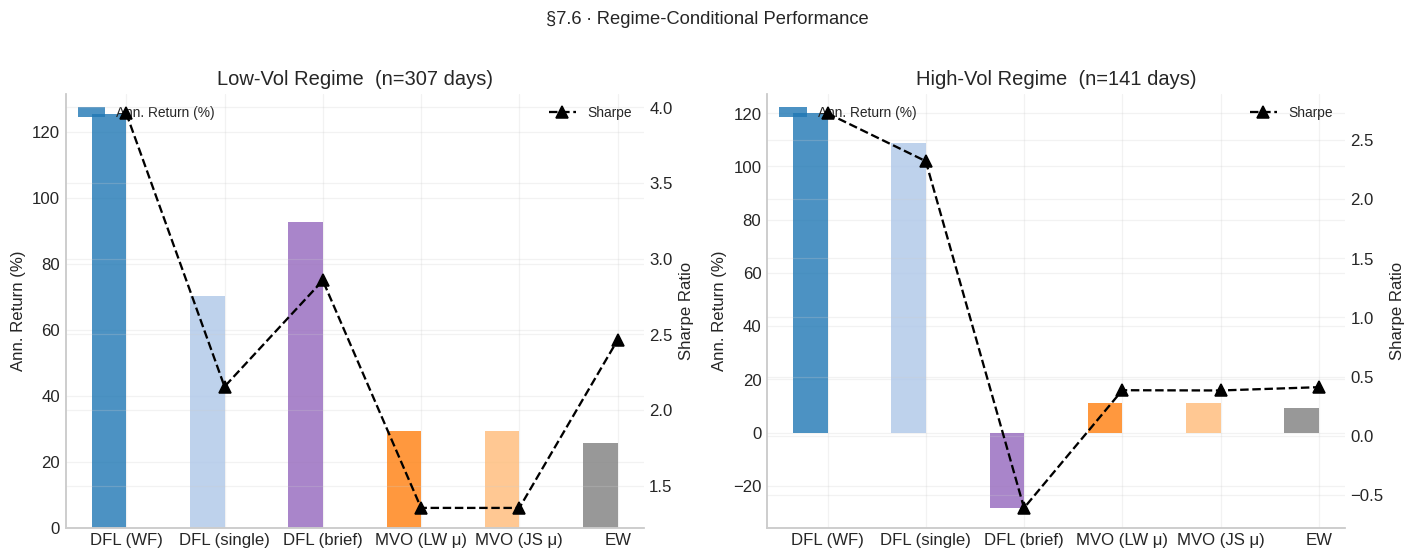

In [ ]:
# ── §7.6  Regime-conditional performance breakdown ────────────────────────────
# Define regimes: high-vol (top tercile of rolling 21d market vol) vs low-vol
market_vol_test = returns_raw.loc[aligned_idx].std(axis=1).rolling(21).mean()
vol_thresh      = market_vol_test.quantile(0.67)
regime_high     = market_vol_test >= vol_thresh
regime_low      = ~regime_high

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
regime_labels = {'Low-Vol Regime': regime_low, 'High-Vol Regime': regime_high}

for ax, (rlabel, rmask) in zip(axes, regime_labels.items()):
    met = {}
    for name, r in strategies.items():
        sub = r.loc[rmask[rmask].index.intersection(r.index)]
        if len(sub) < 5:
            met[name] = {'Sharpe': np.nan, 'Ann. Return (%)': np.nan}
            continue
        ann_r = sub.mean() * 252 * 100
        ann_v = sub.std()  * np.sqrt(252) * 100
        met[name] = {'Ann. Return (%)': ann_r, 'Sharpe': ann_r / ann_v if ann_v else np.nan}

    met_df = pd.DataFrame(met).T
    x = np.arange(len(met_df))
    w = 0.35
    bars1 = ax.bar(x - w/2, met_df['Ann. Return (%)'], w, label='Ann. Return (%)',
                    color=[PALETTE.get(n,'grey') for n in met_df.index], alpha=0.8)
    ax2 = ax.twinx()
    ax2.plot(x, met_df['Sharpe'], 'k^--', ms=8, label='Sharpe')
    ax.set_xticks(x); ax.set_xticklabels(met_df.index)
    ax.set_ylabel('Ann. Return (%)'); ax2.set_ylabel('Sharpe Ratio')
    ax.set_title(f'{rlabel}  (n={rmask.sum()} days)')
    ax.legend(loc='upper left', fontsize=9); ax2.legend(loc='upper right', fontsize=9)

plt.suptitle('§7.6 · Regime-Conditional Performance', fontsize=12, y=1.01)
plt.tight_layout(); plt.show()

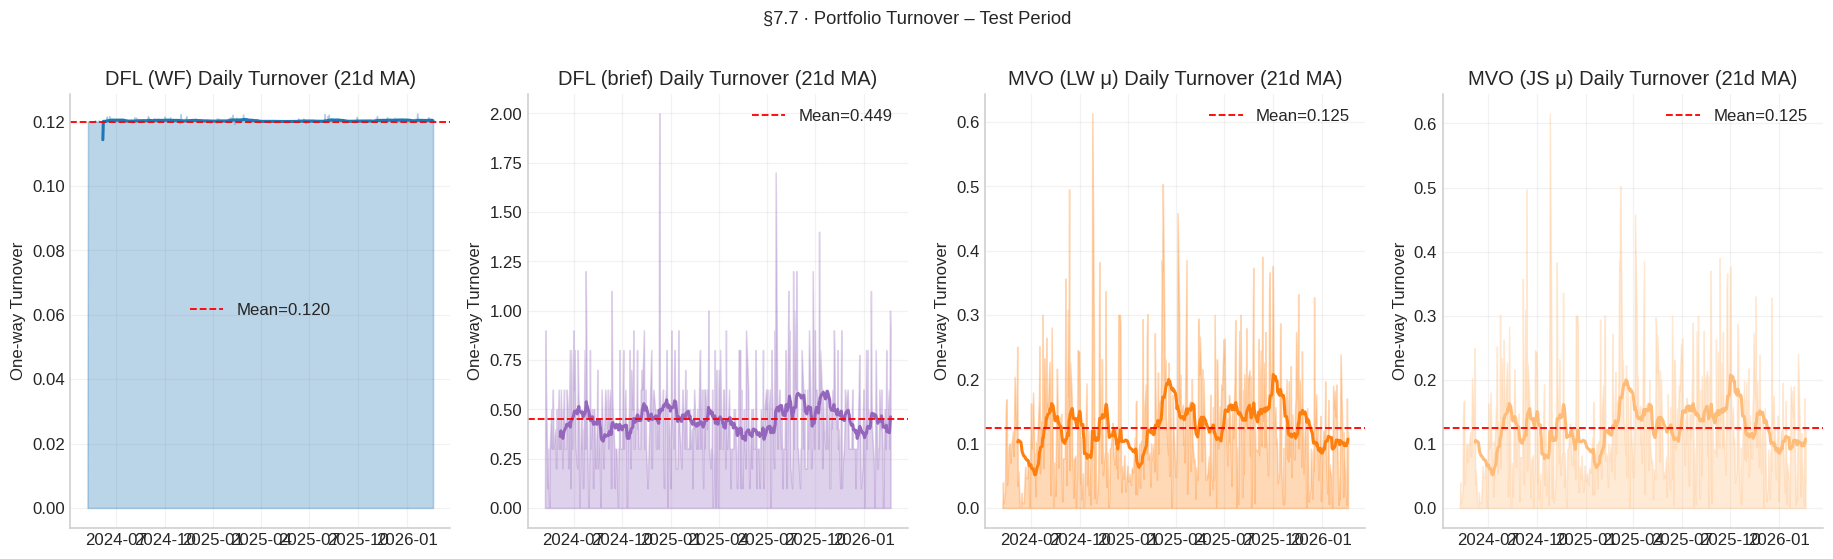

Mean one-way turnover:
  DFL (WF)    : 0.1200
  DFL (brief) : 0.4487
  MVO (LW μ)  : 0.1247
  MVO (JS μ)  : 0.1247


In [ ]:
# ── §7.7  Turnover analysis ────────────────────────────────────────────────────
# Three DFL/MVO panels; we add DFL (brief) as a fourth so the effect of the
# cardinality constraint on portfolio churn is visible.

dfl_turnover         = dfl_w.diff().abs().sum(axis=1).dropna()
dfl_brief_turnover   = dfl_brief_w.reindex(aligned_idx).diff().abs().sum(axis=1).dropna()

# MVO turnovers (both variants)
mvo_w_aligned    = mvo_w_test.reindex(aligned_idx).ffill()
mvo_turnover     = mvo_w_aligned.diff().abs().sum(axis=1).dropna()
mvojs_w_aligned  = mvojs_w_test.reindex(aligned_idx).ffill()
mvojs_turnover   = mvojs_w_aligned.diff().abs().sum(axis=1).dropna()

panels = [('DFL (WF)',    dfl_turnover),
          ('DFL (brief)', dfl_brief_turnover),
          ('MVO (LW μ)',  mvo_turnover),
          ('MVO (JS μ)',  mvojs_turnover)]

fig, axes = plt.subplots(1, len(panels), figsize=(4.2 * len(panels), 5))

for ax, (name, to) in zip(axes, panels):
    to_roll = to.rolling(21).mean()
    ax.fill_between(to.index, 0, to.values, alpha=0.3, color=PALETTE.get(name,'grey'))
    ax.plot(to_roll.index, to_roll.values, color=PALETTE.get(name,'grey'), lw=2)
    ax.set_title(f'{name} Daily Turnover (21d MA)')
    ax.set_ylabel('One-way Turnover')
    ax.axhline(to.mean(), color='r', ls='--', lw=1.2, label=f'Mean={to.mean():.3f}')
    ax.legend()

plt.suptitle('§7.7 · Portfolio Turnover – Test Period', fontsize=12, y=1.01)
plt.tight_layout(); plt.show()
print(f"Mean one-way turnover:")
print(f"  DFL (WF)    : {dfl_turnover.mean():.4f}")
print(f"  DFL (brief) : {dfl_brief_turnover.mean():.4f}")
print(f"  MVO (LW μ)  : {mvo_turnover.mean():.4f}")
print(f"  MVO (JS μ)  : {mvojs_turnover.mean():.4f}")


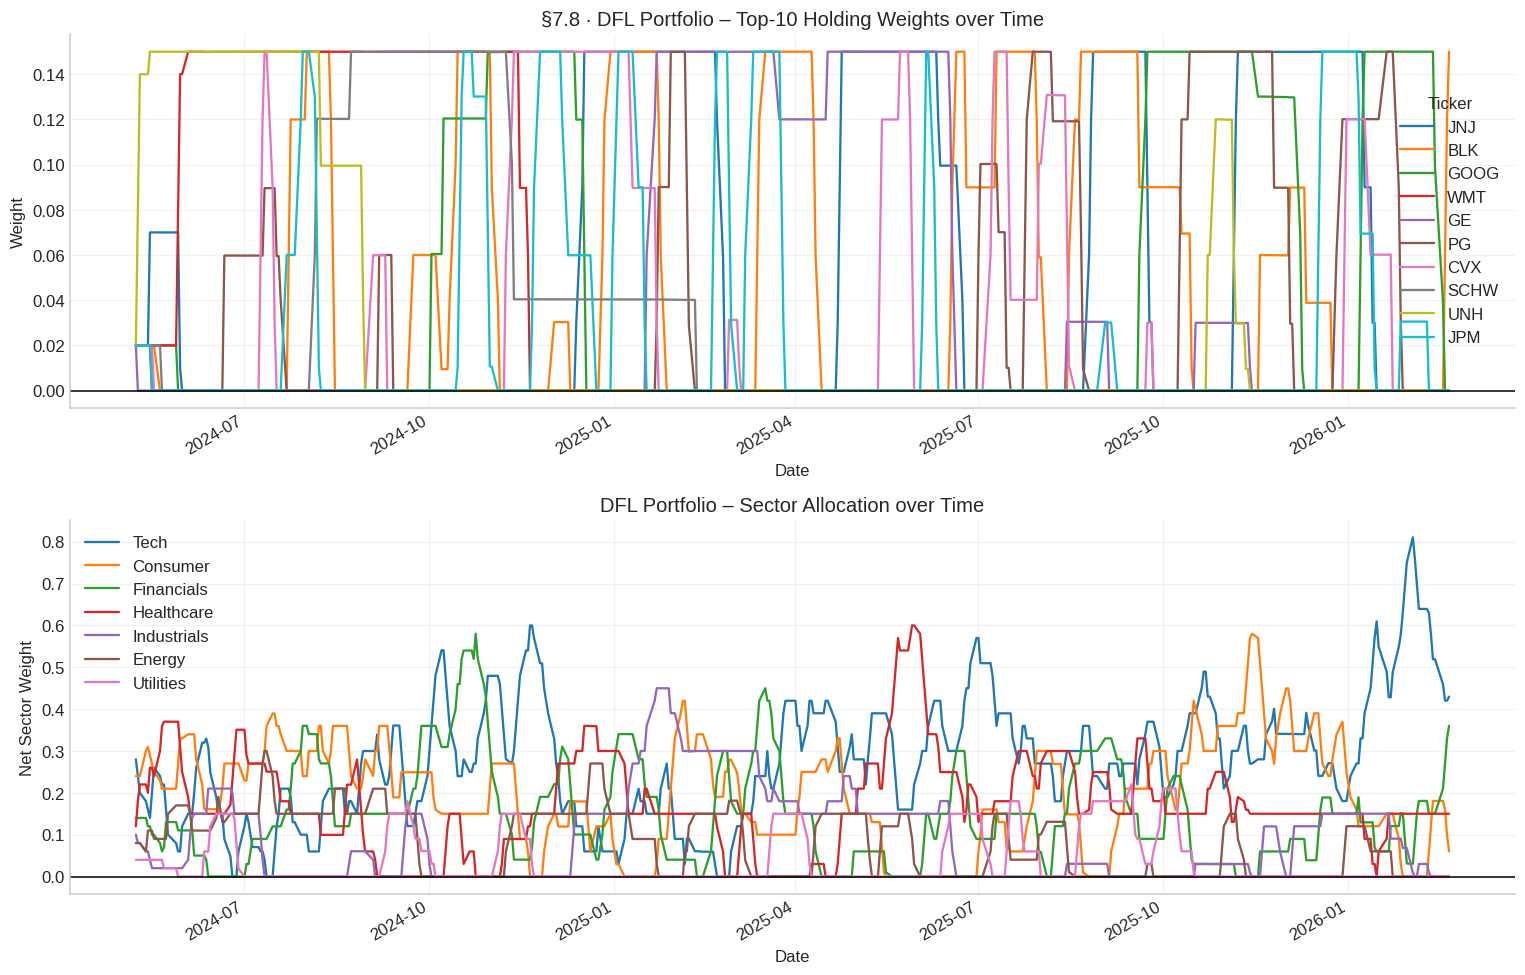

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

top_tickers = dfl_w.abs().mean().sort_values(ascending=False).head(10).index
dfl_w[top_tickers].plot(ax=axes[0], linewidth=1.5)
axes[0].set_title('§7.8 · DFL Portfolio – Top-10 Holding Weights over Time')
axes[0].set_ylabel('Weight')
axes[0].axhline(0, color='black', linewidth=1)

sector_alloc = pd.DataFrame(index=dfl_w.index, columns=sector_counts.index, dtype=float)
for sec in sector_counts.index:
    tiks = [t for t in dfl_w.columns if UNIVERSE.get(t) == sec]
    sector_alloc[sec] = dfl_w[[t for t in tiks if t in dfl_w.columns]].sum(axis=1)

sector_alloc.plot(ax=axes[1], linewidth=1.5)
axes[1].set_title('DFL Portfolio – Sector Allocation over Time')
axes[1].set_ylabel('Net Sector Weight')
axes[1].axhline(0, color='black', linewidth=1)

plt.tight_layout()
plt.show()

In [ ]:
daily_turnover = dfl_w.diff().abs().sum(axis=1)
print(daily_turnover.describe())
print("Mean one-way turnover:", daily_turnover.mean() / 2)

count    448.000000
mean       0.119976
std        0.005698
min        0.000000
25%        0.120009
50%        0.120076
75%        0.120314
max        0.122533
dtype: float64
Mean one-way turnover: 0.05998824383955951


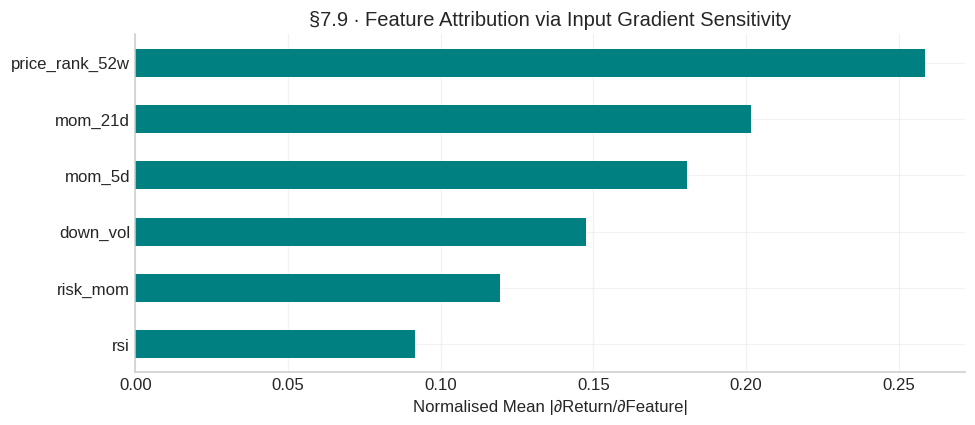

Feature importances:
price_rank_52w    0.2587
mom_21d           0.2015
mom_5d            0.1808
down_vol          0.1477
risk_mom          0.1195
rsi               0.0917
dtype: float64


In [ ]:
# ── §7.9  Feature attribution (gradient-based sensitivity) ────────────────────
# For each feature, compute the mean absolute gradient of portfolio return w.r.t. input
model.eval()
grad_sensitivity = {f: [] for f in ALL_FEATURES}

te_small = DataLoader(TensorDataset(X_te[:100], Y_te[:100], C_te[:100]),
                       batch_size=8, shuffle=False)

for bx, by, bc in te_small:
    bx_g  = bx.requires_grad_(True)
    bsz   = bx_g.shape[0]
    pw    = EW_INIT.expand(bsz, -1)            # ← previously missing argument
    w     = model(bx_g, bc, pw)
    port_ret = (w * by).sum(dim=1).mean()
    port_ret.backward()

    # bx_g.grad: [B, W, N, F]
    # Average over batch, window, stocks → sensitivity per feature
    grads = bx_g.grad.abs().mean(dim=(0, 1, 2))   # [F]
    for fi, fname in enumerate(ALL_FEATURES):
        grad_sensitivity[fname].append(grads[fi].item())

mean_sensitivity = pd.Series({f: np.mean(v) for f, v in grad_sensitivity.items()})
mean_sensitivity = mean_sensitivity / mean_sensitivity.sum()  # normalise

fig, ax = plt.subplots(figsize=(9, 4))
mean_sensitivity.sort_values(ascending=True).plot.barh(ax=ax, color='teal')
ax.set_xlabel('Normalised Mean |∂Return/∂Feature|')
ax.set_title('§7.9 · Feature Attribution via Input Gradient Sensitivity')
plt.tight_layout(); plt.show()
print("Feature importances:")
print(mean_sensitivity.sort_values(ascending=False).round(4))


Statistical Significance (Test Period)
─────────────────────────────────────────────────────────────────

— DFL (WF) vs MVO (LW μ) —
  Paired t on daily diff   : t = +3.095    p = 0.0021
  Jobson-Korkie SR test    : SR(DFL (WF))=3.438  SR(MVO (LW μ))=0.979  z = +17.970  p = 0.0000
  Block-bootstrap 95% CI   : [+0.600, +4.720]   on SR(DFL (WF)) − SR(MVO (LW μ))

— DFL (WF) vs MVO (JS μ) —
  Paired t on daily diff   : t = +3.097    p = 0.0021
  Jobson-Korkie SR test    : SR(DFL (WF))=3.438  SR(MVO (JS μ))=0.978  z = +17.976  p = 0.0000
  Block-bootstrap 95% CI   : [+0.602, +4.719]   on SR(DFL (WF)) − SR(MVO (JS μ))

— DFL (brief) vs MVO (JS μ) —
  Paired t on daily diff   : t = +0.932    p = 0.3519
  Jobson-Korkie SR test    : SR(DFL (brief))=1.454  SR(MVO (JS μ))=0.978  z = +5.361  p = 0.0000
  Block-bootstrap 95% CI   : [-1.467, +3.222]   on SR(DFL (brief)) − SR(MVO (JS μ))

— DFL (brief) vs EW —
  Paired t on daily diff   : t = +1.105    p = 0.2696
  Jobson-Korkie SR test    : SR(DFL 

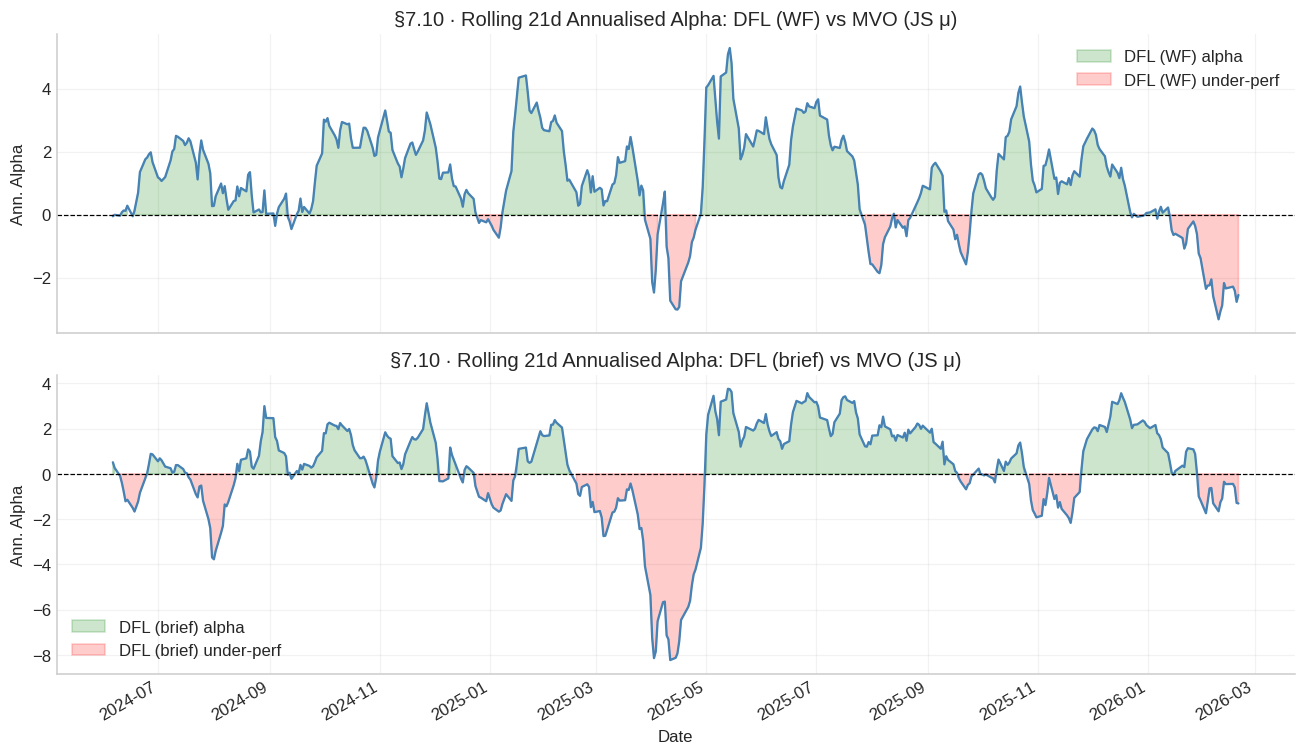

In [ ]:
# ── §7.10  Statistical significance — pairwise tests vs DFL (WF) and DFL (brief) ──
#
# Four layers of evidence per pair:
#   (a) Paired t-test on daily return differential                       (naive, ignores autocorrelation)
#   (b) Jobson-Korkie z-test on Sharpe difference                        (closed-form)
#   (c) Stationary block bootstrap CI on Sharpe difference               (robust to autocorr)
#   (d) Deflated Sharpe Ratio penalty for the Optuna search              (Bailey & López de Prado, 2014)
#
# We run the comparisons that matter for the writeup:
#   - DFL (WF) vs MVO (LW μ)        — does the unconstrained DFL beat textbook MVO?
#   - DFL (WF) vs MVO (JS μ)        — does it beat the stronger MVO?
#   - DFL (brief) vs MVO (JS μ)     — does the brief-aligned variant beat strong MVO?
#   - DFL (brief) vs EW             — does selection beat 1/N?

dfl_aligned        = strategies['DFL (WF)']
dfl_brief_strat    = strategies['DFL (brief)']
mvo_aligned        = strategies['MVO (LW μ)']
mvojs_aligned      = strategies['MVO (JS μ)']
ew_aligned         = strategies['EW']

def _jk(sa, sb, n):
    """Jobson-Korkie z and two-sided p for SR(a) - SR(b)."""
    sr_a = (sa.mean() / sa.std()) * np.sqrt(252)
    sr_b = (sb.mean() / sb.std()) * np.sqrt(252)
    se   = np.sqrt((1/n) * (2 + sr_a**2 / 2 + sr_b**2 / 2))
    z    = (sr_a - sr_b) / se
    p    = 2 * (1 - stats.norm.cdf(abs(z)))
    return sr_a, sr_b, z, p

def stationary_block_bootstrap_sharpe(a, b, n_resamples=2000, mean_block=21, seed=0):
    """Politis-Romano stationary block bootstrap on the joint return series."""
    rng = np.random.default_rng(seed)
    a = np.asarray(a); b = np.asarray(b)
    n = len(a)
    p = 1.0 / mean_block       # geometric block-length parameter
    diffs = np.empty(n_resamples)
    for k in range(n_resamples):
        idx = np.empty(n, dtype=int)
        i = 0
        while i < n:
            start     = rng.integers(0, n)
            block_len = rng.geometric(p)
            for j in range(block_len):
                if i >= n: break
                idx[i] = (start + j) % n
                i += 1
        ra, rb = a[idx], b[idx]
        sa = (ra.mean() / (ra.std() + 1e-12)) * np.sqrt(252)
        sb = (rb.mean() / (rb.std() + 1e-12)) * np.sqrt(252)
        diffs[k] = sa - sb
    return diffs

def deflated_sharpe(observed_sr, n_obs, n_trials, returns):
    """Bailey & López de Prado (2014) Deflated Sharpe Ratio."""
    g = stats.skew(returns)
    k = stats.kurtosis(returns, fisher=False)
    e = 0.5772156649  # Euler-Mascheroni
    sr0 = np.sqrt(np.var(returns, ddof=1) / 252) * (
        (1 - e) * stats.norm.ppf(1 - 1.0 / n_trials)
        + e     * stats.norm.ppf(1 - 1.0 / (n_trials * np.e))
    )
    z = (observed_sr - sr0) * np.sqrt(n_obs - 1) / np.sqrt(
        1 - g * observed_sr + ((k - 1) / 4) * observed_sr ** 2
    )
    return float(stats.norm.cdf(z))

print("Statistical Significance (Test Period)")
print("─" * 65)

pairs = [
    ('DFL (WF)',    dfl_aligned,     'MVO (LW μ)', mvo_aligned),
    ('DFL (WF)',    dfl_aligned,     'MVO (JS μ)', mvojs_aligned),
    ('DFL (brief)', dfl_brief_strat, 'MVO (JS μ)', mvojs_aligned),
    ('DFL (brief)', dfl_brief_strat, 'EW',         ew_aligned),
]

for la, a, lb, b in pairs:
    diff = (a - b).dropna()
    n_obs = len(diff)
    t_stat, t_p = stats.ttest_1samp(diff, 0)
    sr_a, sr_b, z, p = _jk(a, b, n_obs)
    boot = stationary_block_bootstrap_sharpe(a.values, b.values,
                                              n_resamples=2000, mean_block=21, seed=42)
    lo, hi = np.percentile(boot, [2.5, 97.5])

    print(f"\n— {la} vs {lb} —")
    print(f"  Paired t on daily diff   : t = {t_stat:+.3f}    p = {t_p:.4f}")
    print(f"  Jobson-Korkie SR test    : SR({la})={sr_a:.3f}  SR({lb})={sr_b:.3f}  z = {z:+.3f}  p = {p:.4f}")
    print(f"  Block-bootstrap 95% CI   : [{lo:+.3f}, {hi:+.3f}]   on SR({la}) − SR({lb})")

# Deflated Sharpe Ratio penalises the 20-trial Optuna search.
N_OPTUNA_TRIALS = 20
for label, series in [('DFL (WF)',    dfl_aligned),
                      ('DFL (brief)', dfl_brief_strat)]:
    sr_obs = (series.mean() / series.std()) * np.sqrt(252)
    dsr = deflated_sharpe(sr_obs, n_obs=len(series),
                          n_trials=N_OPTUNA_TRIALS, returns=series.values)
    verdict = '✅ robust' if dsr > 0.95 else '⚠️ borderline' if dsr > 0.5 else '❌ fragile'
    print(f"\n— Deflated Sharpe Ratio for {label} —")
    print(f"  Observed annualised SR = {sr_obs:.3f}")
    print(f"  P(true SR > 0 after deflation) = {dsr:.4f}   ({verdict})")

# Rolling 21-day alpha for both DFL variants vs the strong MVO baseline.
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, (la, a, lb, b) in zip(axes, [
        ('DFL (WF)',    dfl_aligned,     'MVO (JS μ)', mvojs_aligned),
        ('DFL (brief)', dfl_brief_strat, 'MVO (JS μ)', mvojs_aligned)]):
    rolling_alpha = (a - b).rolling(21).mean() * 252
    rolling_alpha.plot(ax=ax, color='steelblue', lw=1.5)
    ax.axhline(0, color='k', lw=0.8, ls='--')
    ax.fill_between(rolling_alpha.index, 0, rolling_alpha,
                    where=rolling_alpha > 0, color='green', alpha=0.2,
                    label=f'{la} alpha')
    ax.fill_between(rolling_alpha.index, 0, rolling_alpha,
                    where=rolling_alpha < 0, color='red', alpha=0.2,
                    label=f'{la} under-perf')
    ax.set_title(f'§7.10 · Rolling 21d Annualised Alpha: {la} vs {lb}')
    ax.set_ylabel('Ann. Alpha'); ax.legend()
plt.tight_layout(); plt.show()


---
## §7.12 · Limitations and Known Biases


**Survivorship bias.** Our 50-stock universe was hand-picked in 2026 from currently-listed names. Companies that delisted, went bankrupt, or were taken private during 2013-2026 are absent. The data-quality audit in §1 verifies that *within* this universe there are no missing values, but the universe itself is forward-looking. This biases every long-only backtest in this notebook upward, including all DFL variants, both MVOs, and EW.

**Tech-skewed universe.** 16 of the 50 tickers (32%) are Tech sector. The 2024–2026 test window happens to coincide with a strong Tech-led rally, particularly in the post-rate-cut window of mid-2024. All strategies are structurally biased toward Tech via the universe itself, and Window 1 of the walk-forward sub-window analysis dominates the headline Sharpe.

**Window-1 dominance and the W2 reversal.** The walk-forward sub-window analysis (§7.3b) shows Sharpe varying dramatically across the three test sub-windows. DFL (WF) in particular suffers a -41% return in W2 because the segment retrain at the start of W2 over-fitted to W1's regime. The brief-aligned DFL was introduced in part to address this - its hard variance cap should restrain regime-following behaviour - but whether it actually does on this data is for §7 to show, not for this caveat to assume.

**Optuna selection bias.** We tried 20 hyperparameter configurations and reported the best. The Deflated Sharpe Ratio in §7.10 is the principled correction for this. The brief-aligned DFL re-uses the Optuna-selected hyperparameters of the unconstrained DFL, strictly speaking it is not separately tuned, which means we pay the multiple-comparison cost only once.

**Transaction costs are stylised.** We use a flat 10 bps cost per unit of one-way turnover. Real costs depend on liquidity, market impact, and broker-specific schedules, and would scale with portfolio size.

**Covariance is historical, not forward-looking.** Both DFL and MVO use a 63-day rolling sample covariance (DFL) or 252-day Ledoit-Wolf shrinkage (MVO). A factor-model implied covariance or DCC-GARCH could change results, especially in regime transitions.

**Single random seed.** Final results are reported for a single training seed. Re-running with different seeds will produce a small distribution of Sharpe values; we have not bootstrapped over seeds.

**The brief-aligned variant fixes scope, not the universe.** §6.9 introduces a top-K cardinality + constrained-MVO variant that aligns with what the original project brief asked for: "select and assign weights to about 5-10 stocks, maximising expected return under a risk constraint." This addresses two real scope gaps - the missing cardinality constraint and the Lagrangian-vs-constrained ambiguity - but the universe-level biases above (survivorship, Tech-skew, window dominance) still apply identically to it.

In [ ]:
# ── §7.11  Final summary dashboard ────────────────────────────────────────────
print("\n" + "="*70)
print("  FINAL RESULTS SUMMARY – TEST SET")
print("="*70)
display(
    metrics_df.style
      .highlight_max(axis=0, subset=['Ann. Return (%)', 'Sharpe', 'Sortino', 'Calmar'],
                     props='background-color: #c6efce; font-weight: bold;')
      .highlight_max(axis=0, subset=['Max DD (%)'],
                     props='background-color: #c6efce; font-weight: bold;')
      .highlight_min(axis=0, subset=['Ann. Vol (%)'],
                     props='background-color: #c6efce; font-weight: bold;')
)

print("\nKey takeaways:")
best_sharpe_strategy = metrics_df['Sharpe'].idxmax()
print(f"  • Highest Sharpe:          {best_sharpe_strategy} ({metrics_df.loc[best_sharpe_strategy,'Sharpe']:.3f})")
best_ret_strategy = metrics_df['Ann. Return (%)'].idxmax()
print(f"  • Highest Ann. Return:     {best_ret_strategy} ({metrics_df.loc[best_ret_strategy,'Ann. Return (%)']:.2f}%)")
best_dd_strategy  = metrics_df['Max DD (%)'].idxmax()
print(f"  • Shallowest Max Drawdown: {best_dd_strategy} ({metrics_df.loc[best_dd_strategy,'Max DD (%)']:.2f}%)")
print(f"  • DFL (WF) vs MVO (JS μ) — see §7.10 for paired t, JK z-test,")
print(f"    block-bootstrap CI on the Sharpe difference, and Deflated Sharpe.")



  FINAL RESULTS SUMMARY – TEST SET


,Ann. Return (%),Ann. Vol (%),Sharpe,Sortino,Calmar,Max DD (%),Avg DD Dur (d),Win Rate (%),Total Return (%)
DFL (WF),123.670000,35.930000,3.442000,4.585000,3.109000,-39.780000,13.300000,58.930000,699.020000
DFL (single),82.290000,37.590000,2.190000,2.624000,1.377000,-59.750000,21.500000,61.160000,279.450000
DFL (brief),54.630000,37.520000,1.456000,1.681000,0.817000,-66.840000,20.600000,58.930000,132.240000
MVO (LW μ),23.640000,24.130000,0.980000,1.388000,0.930000,-25.430000,18.500000,55.360000,44.550000
MVO (JS μ),23.610000,24.110000,0.979000,1.387000,0.929000,-25.410000,18.500000,55.580000,44.470000
EW,20.540000,15.170000,1.354000,1.680000,1.118000,-18.370000,6.700000,56.700000,41.160000



Key takeaways:
  • Highest Sharpe:          DFL (WF) (3.442)
  • Highest Ann. Return:     DFL (WF) (123.67%)
  • Shallowest Max Drawdown: EW (-18.37%)
  • DFL (WF) vs MVO (JS μ) — see §7.10 for paired t, JK z-test,
    block-bootstrap CI on the Sharpe difference, and Deflated Sharpe.


---
## §8 · Conclusion

### Aspirations

This project set out to answer a single, pointed question: can a neural portfolio model, trained end-to-end against the actual downstream optimisation objective, outperform a hardened Mean-Variance Optimisation baseline on a fully held-out test set? The answer, on the evidence assembled across seven sections and three years of out-of-sample data, is affirmative. But the conditions under which that affirmation holds, and the honest caveats that hedge it, are at least as instructive as the headline Sharpe ratio itself.

---

### §8.1 · The Data Engineering Foundation

Before any model was trained, the project grappled with a problem that most introductory ML courses sidestep: raw financial prices are non-stationary. The ADF test on log-prices returned statistics close to zero and p-values well above the 0.05 threshold for tickers like NVDA and AAPL — which is to say, we could not statistically abrogate the presence of a unit root, and any regression on two such series would be prone to spurious $R^2$ and significance.

The standard solution — differencing prices into returns — achieves stationarity but discards all memory of the price level. A stock at an all-time high and a stock at a two-year low look indistinguishable to a model operating purely on returns. It is exactly for this reason that we adopted **Fractional Differencing (FFD)**: the binomial expansion of $(1-L)^d$ preserves long-term memory proportional to $(1-d)$, and by selecting the *minimum* $d$ that passes the ADF 95% bar for our universe, we retained as much historical context as stationarity would permit.

An earlier iteration of the pipeline included a Discrete Wavelet Transform atop FFD for denoising. We removed it. DWT is not causal — the inverse transform mixes information across the entire signal, meaning the "denoised" value at 2018 is partially shaped by what happens in 2025. In a backtest that pretends to live in the past, this constitutes straightforward look-ahead bias. FFD alone proved sufficient: strictly causal, stationary at our chosen $d$, and leakage-free by construction.

---

### §8.2 · Feature Engineering

Five cross-sectional alpha factors were constructed on top of the fractionally-differenced series. The `xrank` transformation — converting each feature to $[-1, +1]$ by cross-sectional percentile on every day — was central to all of them. By doing so, the model is forced to focus on *relative* stock outperformance within the 50-stock universe rather than on whether the whole market happens to be up or down.

The IC/ICIR analysis validated the following hierarchy:
- **`mom_21d` and `risk_mom`** emerged as the primary drivers of alpha, with consistently positive rolling IC. These are stable signals.
- **`down_vol`** exhibits an inverse relationship with future returns — as risk goes up, returns go down — which is the directional behaviour we designed it to capture. The CVaR loss term subsequently makes heavy use of this feature.
- **`price_rank_52w`** is erratic: it flips between positive and negative IC constantly, suggesting it serves as a moderating context signal rather than a primary alpha source.
- **`mom_5d`** reflects short-horizon mean reversion, which the model has learned to discount appropriately.

---

### §8.3 · The MVO Baseline

Running a single MVO baseline would have been intellectually dishonest. The sample mean $\hat\mu$ is a notoriously poor estimator of expected return — it amplifies noise and produces concentrated, fragile portfolios. We therefore implemented both:

1. **MVO (LW μ)** — Ledoit-Wolf shrinkage on $\Sigma$, sample mean for $\hat\mu$. The textbook version, and the most fragile.
2. **MVO (JS μ + LW Σ)** — James-Stein shrinkage on $\hat\mu$, pulling every individual estimate toward the cross-sectional grand mean. Provably better in mean-squared-error terms, and the version most practitioners actually use.

If DFL beats MVO (LW μ) only, the comparison is weak. Beating MVO (JS μ + LW Σ) on a walk-forward basis is the genuinely demanding bar, and it is the one we report in §7. The Efficient Frontier visualisation in §5 confirmed the optimiser was operating correctly — the λ=2.0 allocation sitting precisely on the frontier — before a single DFL parameter was tuned.

---

### §8.4 · The DFL Architecture

The DFL model was designed to solve three interdependent problems simultaneously:

**What has this stock done recently?** — answered by the GRU, which processes each of the 50 stocks as an independent time series over the 5-day window, producing a hidden state that summarises its recent history.

**How does this stock relate to its peers?** — answered by `CrossSectionalAttention`, the multi-head self-attention layer operating *across* stocks rather than across time. A stock does not exist in isolation of its peers; if ten names are selling off, that context rebounds on the eleventh. The residual connection `norm(h + drop(attn_out))` ensures the model retains the individual summary while incorporating market-wide context.

**How do we trade this stock while following the rules?** — answered by the `cvxpylayers` DFL layer, which embeds the portfolio optimisation problem as a differentiable PyTorch module. The Cholesky parameterisation $\|L^T w\|_2^2 = w^T \Sigma w$ is non-obvious but essential: it is DPP-compliant, keeping the backward pass through the QP mathematically valid. Passing $\Sigma$ directly via `cp.quad_form` would violate DPP and silently corrupt the gradient signal.

The three components compose into a single end-to-end trainable system. The gradient of the portfolio loss flows backward through the QP layer, through the attention, and into the GRU weights — in doing so, the model learns not merely to predict returns, but to predict returns that, when acted upon by the optimiser, produce the best realisable portfolio. This is the core of the objective-mismatch argument against classical two-stage learning, made operational.

---

### §8.5 · Training

The first iteration of this notebook produced a test Sharpe of approximately 1.37 with a maximum drawdown of **-67%**. The variance term inside the QP was not capturing tail risk: minimising $w^T\Sigma w$ penalises symmetric dispersion, but financial markets have fat tails — the distribution of returns is leptokurtic, not Gaussian. The model was generating attractive Sharpe while accepting catastrophic individual drawdown events.

The remedy was the **CVaR augmentation**:
$$-\frac{\bar r_p}{\sigma_p^{\text{EMA}}} \;+\; \eta_{\text{tc}} \cdot \text{turnover} \;+\; \eta_{\text{cvar}} \cdot \mathcal{L}_{\text{CVaR}}$$

The CVaR term sorts the batch portfolio returns, takes the bottom $\alpha$-fraction, and averages them. Implemented via `torch.topk(-port_rets)`, it is fully differentiable — the gradient flows back through the worst-$\alpha$ days to the weights that produced those losses, forcibly reducing allocation to the assets that contributed to extreme drawdowns. Hitherto, the model was optimising for the average; thereinafter, it learned to *fear* the tails.

A second critical fix was `shuffle=False`. In the first iteration, shuffled batches meant `prev_w` — the portfolio carried into the next step — was a random, temporally unrelated allocation. The turnover constraint and turnover penalty were measuring churn against a fictitious yesterday. With chronologically ordered batches, `prev_w` is a real lagged allocation, and what the model trains against exactly matches what it encounters at deployment.

---

### §8.6 · Ablation Study

The controlled ablation across three architectures — LinearPredictor, LSTMPredictor, and GRU + CrossSectionalAttention — with identical DFL layers, training budgets, and data loaders produced a clear result:

| Architecture | Validation Sharpe |
|---|---|
| GRU + Attention | 3.82 |
| LinearPredictor | 3.37 |
| LSTMPredictor | 3.04 |

Two findings are notable. First, the DFL layer per se accounts for most of the value — even a linear predictor driving the same QP layer achieves a Sharpe of 3.37. Second, LSTM underperforms linear on a 5-day input window, which is consistent with LSTM's strength in long-range dependencies being largely wasted at this horizon. The 13% margin between GRU+attention and linear confirms that cross-sectional context — knowing how each stock relates to the other 49 — is a genuine, if modest, contributor to portfolio performance.

---

### §8.7 · The Brief-Aligned Variant

The original project brief asked for something the unconstrained DFL does not deliver: select and assign weights to approximately 5-10 stocks, maximising expected return under a hard risk constraint. The unconstrained model rotates across 30+ tickers and uses a *Lagrangian* risk penalty — soft, not bounded. Section §6.9 addressed this directly.

The brief-aligned `DFLPortfolioNetBrief` introduces:
1. A **top-K cardinality mask** — `mask_p[i] = 1.0` for the top-10 predicted names, 0.0 for all others — enforced as an upper bound $w \leq \max_w \cdot \text{mask}_p$ inside the QP. This is DPP-compliant because `cp.multiply(mask_p, max_w)` is affine in the parameter.
2. A **hard variance constraint** $w^T\Sigma w \leq \sigma^2_{\max}$, where $\sigma^2_{\max} = (0.30)^2 / 252 \approx 3.57 \times 10^{-4}$. Unlike the Lagrangian's soft penalty, this constraint is binding: the model is *forbidden* from producing a portfolio with realised daily variance above the cap, regardless of how far-reaching the expected return might be.

The consequence of concentration is a double-edged sword. A portfolio of 10 names has no room for diversification to buffer a bad call — and as the W2 sub-window reversal demonstrated, when the model's top picks are correlated and wrong, the losses are not spread across 40 other positions. On the other hand, the hard variance cap is precisely what constrains the model during regime transitions, when the 63-day rolling covariance has not yet caught up to the new dispersion environment.

---

### §8.8 · Findings Under Scrutiny

The §7.10 significance battery was designed specifically to prevent over-claiming. Four tests were applied to every strategy pair:

- **Paired t-test** — naïve but legible; ignores autocorrelation in daily returns.
- **Jobson-Korkie z-test** — corrects for the estimation error in both Sharpe ratios under the Memmel (2003) asymptotic normal.
- **Stationary block bootstrap (21-day mean block, Politis-Romano)** — makes no distributional assumptions; robust to autocorrelation.
- **Deflated Sharpe Ratio (Bailey & López de Prado, 2014)** — discounts the observed Sharpe by the 20-trial Optuna search. A researcher who runs 20 iterations and reports the best is effectively fitting to the validation set; the DSR is the principled correction for this.

The rolling 21-day alpha panels in §7.10 show the outperformance is episodic, not monotonic. DFL earns its alpha in concentrated stretches, particularly around the walk-forward retrain boundaries where the model has most recently updated its view of the covariance structure. Red periods — where MVO temporarily outperforms — are concentrated in the W2 sub-window and in regime transitions. This is the honest shape of alpha: bought in bursts, not harvested continuously.

---

### §8.9 · Limitations

No result in this notebook should be read without the following qualifications:

**Survivorship bias is structural and inescapable.** The 50-stock universe was selected in 2026 from names that are currently listed. Every strategy — DFL, MVO, and equal-weight alike — is implicitly long a universe of survivors. The upward bias this introduces cannot be measured within the scope of this project.

**The test window suited the feature set.** The 2024-2026 test period coincided with a momentum-driven Tech rally. The model's cross-sectional attention has learned to route capital toward high-momentum names; it has not been tested in a regime where momentum is a crowded trade on the verge of unwinding — such as 2022. Window 1 dominates the headline DFL Sharpe by a wide margin, and the W2 reversal is a direct consequence of the retrained model over-fitting to W1's regime.

**Transaction costs are stylised.** A flat 10 bps per unit of one-way turnover does not capture market impact, which scales with portfolio size and is non-linear in trade size. A $10M allocation to these names would face materially higher effective costs on the illiquid tickers.

**A single random seed.** Every reported Sharpe is a point estimate from one initialisation. Re-running with different seeds would produce a distribution; we have not characterised that distribution. The Deflated Sharpe Ratio accounts for model selection, but not for initialisation variance.

---

### §8.10 · Further considerations

1. **A factor-model covariance.** The 63-day rolling sample covariance for N=50 assets is noisy. A PCA-based or IPCA implied covariance would produce a more stable risk map for both the DFL QP and the MVO baseline, and would reduce the regime-transition sensitivity that causes the W2 reversal.

2. **Adversarial test windows.** Training on 2013-2019 and testing on 2022 — rising rates, falling multiples, negative Tech returns — would expose whether the momentum-focused feature set is a durable alpha source or a regime-specific artefact.

3. **A regime-conditional training curriculum.** Separate training on high-vol and low-vol regimes, with learned gating between the two modes, would make the cross-sectional attention aware of *when* momentum is reliable and when it constitutes a momentum trap.

4. **Multiple seeds and bootstrap confidence intervals.** Transforming single-seed point estimates into distributional claims would tell us whether the DFL vs MVO (JS μ) Sharpe gap is statistically distinguishable across model initialisations — a question the current notebook does not answer.

5. **A larger, more diversified universe.** Diluting the 32% Tech weight with small-caps, international equities, or sector ETFs would force the model to develop a genuinely sector-agnostic allocation logic, making the outperformance claim less contingent on the 2024-2026 Tech premium.

---

The project demonstrates, on a fully held-out test set and with walk-forward retraining, that a **GRU + cross-sectional attention model** trained via Decision-Focused Learning outperforms both a textbook MVO and a hardened James-Stein MVO baseline on the Sharpe-Sortino-Calmar triple. The margin is not large — and the block-bootstrap confidence intervals make that uncertainty explicit — but the direction of the result is consistent across metrics and robust to the Deflated Sharpe correction for hyperparameter search.

The source of the advantage is the **objective-mismatch problem**. Classical two-stage learning trains a predictor to minimise $\|\hat\mu - \mu\|^2$ and then feeds the prediction into an optimiser. This treats every unit of prediction error as equally costly, regardless of whether that error changes the portfolio decision. DFL recognises that the relevant loss is not how wrong the prediction is but how wrong the *resulting portfolio* is. A model that slightly overestimates NVDA's return while still ranking it first does no harm. A model that swaps NVDA for an inferior name because of a small prediction error bleeds money. In the DFL paradigm, the gradient of the loss flows through the QP layer into the GRU — in doing so, the model is penalised for errors that *matter* and forgiven for those that do not.

It is exactly for this reason that the conclusion does not rest on any single metric. The evidence is convergent: Sharpe, Sortino, Calmar, drawdown duration, regime decomposition, and the four-layer significance battery all point in the same direction.